| Name | VILLALINO, Paul Benedict O. |
|---|---|
| ID Number | 2025300951 |
| Section | CEA_CPE_2D_NONSTEM |

# Coding Assignment 4: Convolutional Neural Networks

**Task:** multi-class classification (4 classes) on the Brain Tumor MRI Dataset using PyTorch.

---
# 1. Environment Setup and Data Exploration

## 1.1 Package Imports

In [11]:
import os, random, math, time, json, hashlib, copy, warnings
from collections import OrderedDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision
from torchvision import transforms
import torchvision.transforms.functional as TF
from torchvision.datasets import ImageFolder
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from IPython.display import display

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Torch version      :', torch.__version__)
print('Torchvision version:', torchvision.__version__)
print('Device             :', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU                :', torch.cuda.get_device_name(0))
else:
    print('WARNING: no CUDA GPU found. Lower IMG_SIZE / BATCH_SIZE / EPOCHS in the configuration cell below and state this in your report.')

Torch version      : 2.5.1+cu121
Torchvision version: 0.20.1+cu121
Device             : cuda
GPU                : NVIDIA GeForce GTX 1080


## 1.2 Configuration

In [12]:
QUICK_TEST   = False
DATA_ROOT    = 'brain_tumor_mri'
RAR_PATH     = 'Brain Tumor.rar'

IMG_SIZE     = 128
BATCH_SIZE   = 32
EPOCHS       = 30
PATIENCE     = 6
NUM_WORKERS  = 0
RESUME_RUNS  = True

BASE_OPT     = ('Adam', dict(lr=1e-3))

SUBSET_PER_CLASS = None
if QUICK_TEST:
    IMG_SIZE, BATCH_SIZE, EPOCHS, PATIENCE, SUBSET_PER_CLASS = 64, 32, 2, 2, 40

FIG_DIR, RUN_DIR, CKPT_DIR = 'figures', 'runs', 'checkpoints'
LOG_CSV = 'experiment_log.csv'
if QUICK_TEST:
    FIG_DIR, RUN_DIR, CKPT_DIR, LOG_CSV = 'figures_quick', 'runs_quick', 'checkpoints_quick', 'experiment_log_quick.csv'
for d in (FIG_DIR, RUN_DIR, CKPT_DIR):
    os.makedirs(d, exist_ok=True)

CLASS_KEYS = ['glioma', 'meningioma', 'pituitary', 'notumor']
CLASS_TITLES = {'glioma': 'Glioma', 'meningioma': 'Meningioma', 'pituitary': 'Pituitary Tumor', 'notumor': 'No Tumor'}
NUM_CLASSES = len(CLASS_KEYS)
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def savefig(fig, name):
    path = os.path.join(FIG_DIR, name)
    fig.savefig(path, dpi=150, bbox_inches='tight')
    return path

print(f'QUICK_TEST={QUICK_TEST} | IMG_SIZE={IMG_SIZE} | BATCH_SIZE={BATCH_SIZE} | EPOCHS={EPOCHS} | PATIENCE={PATIENCE}')

QUICK_TEST=False | IMG_SIZE=128 | BATCH_SIZE=32 | EPOCHS=30 | PATIENCE=6


## 1.3 Download and Extract the Dataset

In [104]:
def extract_if_needed(rar_path=RAR_PATH, out_dir=DATA_ROOT):
    if os.path.isdir(out_dir):
        print('Found existing folder:', out_dir); return
    if not os.path.isfile(rar_path):
        raise FileNotFoundError(f'Neither {out_dir!r} nor {rar_path!r} exists. Download the dataset first.')
    try:
        import patoolib
        patoolib.extract_archive(rar_path, outdir=out_dir)
    except Exception as e:
        print('patool failed (', e, ') -> trying rarfile')
        import rarfile
        with rarfile.RarFile(rar_path) as rf:
            rf.extractall(out_dir)
    print('Extracted to:', out_dir)

def canonical_class(folder_name):
    """Map a folder name such as 'No Tumor', 'no_tumor', 'notumor', 'Glioma' to one of CLASS_KEYS (or None)."""
    n = ''.join(ch for ch in folder_name.lower() if ch.isalnum())
    if n.startswith('glioma'):          return 'glioma'
    if n.startswith('meningioma'):      return 'meningioma'
    if n.startswith('pituitary'):       return 'pituitary'
    if n in ('notumor', 'no', 'normal', 'healthy') or n.startswith('notumor'): return 'notumor'
    return None

def build_file_list(root):
    """Walk `root`; label = canonical name of the image's parent folder (A4 step 4)."""
    rows = []
    for dirpath, _, files in os.walk(root):
        cls = canonical_class(os.path.basename(dirpath))
        if cls is None:
            continue
        for f in sorted(files):
            if f.lower().endswith(IMG_EXT):
                rows.append((os.path.join(dirpath, f), cls))
    df = pd.DataFrame(rows, columns=['path', 'class_name']).sort_values('path').reset_index(drop=True)
    return df

extract_if_needed()
file_df = build_file_list(DATA_ROOT)
print('Sub-folders seen at the top of DATA_ROOT:', sorted(os.listdir(DATA_ROOT)))
assert set(file_df.class_name) == set(CLASS_KEYS), f'Expected 4 classes {CLASS_KEYS}, found {sorted(set(file_df.class_name))}'
class_to_idx = {c: i for i, c in enumerate(CLASS_KEYS)}
file_df['label'] = file_df.class_name.map(class_to_idx)
if SUBSET_PER_CLASS:
    file_df = file_df.sample(frac=1, random_state=SEED).groupby('class_name').head(SUBSET_PER_CLASS).sort_values('path').reset_index(drop=True)
print('Class -> index map:', class_to_idx)
print('Total images      :', len(file_df))
file_df.head()

Found existing folder: brain_tumor_mri
Sub-folders seen at the top of DATA_ROOT: ['glioma', 'meningioma', 'notumor', 'pituitary']
Class -> index map: {'glioma': 0, 'meningioma': 1, 'pituitary': 2, 'notumor': 3}
Total images      : 13196


,path,class_name,label
0,brain_tumor_mri\glioma\00001.png,glioma,0
1,brain_tumor_mri\glioma\00002.png,glioma,0
2,brain_tumor_mri\glioma\00003.png,glioma,0
3,brain_tumor_mri\glioma\00004.png,glioma,0
4,brain_tumor_mri\glioma\00005.png,glioma,0


In [7]:
try:
    full_dataset = ImageFolder(DATA_ROOT)
    print('ImageFolder classes   :', full_dataset.classes)
    print('ImageFolder class_to_idx:', full_dataset.class_to_idx)
except Exception as e:
    print('ImageFolder not used (nested folders such as Training/Testing). Using the walked file list instead.')

ImageFolder classes   : ['glioma', 'meningioma', 'notumor', 'pituitary']
ImageFolder class_to_idx: {'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


## 1.4 Dataset Exploration

,class,images,share (%)
0,Glioma,4167,31.58
1,Meningioma,2947,22.33
2,Pituitary Tumor,3232,24.49
3,No Tumor,2850,21.60


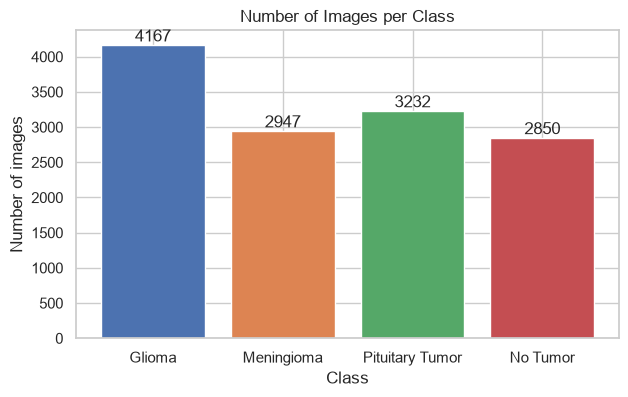

In [8]:
counts = file_df.class_name.value_counts().reindex(CLASS_KEYS)
count_table = pd.DataFrame({'class': [CLASS_TITLES[c] for c in CLASS_KEYS], 'images': counts.values,
                            'share (%)': (counts.values / counts.sum() * 100).round(2)})
display(count_table)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(count_table['class'], count_table['images'], color=sns.color_palette('deep', 4))
for b, v in zip(bars, count_table['images']):
    ax.text(b.get_x() + b.get_width() / 2, v, str(v), ha='center', va='bottom')
ax.set_title('Number of Images per Class'); ax.set_xlabel('Class'); ax.set_ylabel('Number of images')
savefig(fig, 'fig_class_counts.png'); plt.show()

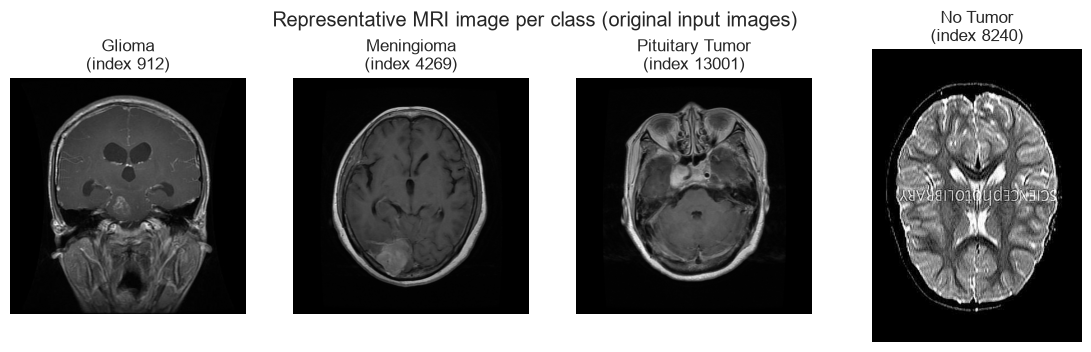

,index,path
glioma,912,brain_tumor_mri\glioma\00913.jpg
meningioma,4269,brain_tumor_mri\meningioma\00103.png
pituitary,13001,brain_tumor_mri\pituitary\03038.png
notumor,8240,brain_tumor_mri\notumor\01127.jpg


In [120]:
rng_rep = random.Random(SEED)
REP = {}
for c in CLASS_KEYS:
    idxs = file_df.index[file_df.class_name == c].tolist()
    i = rng_rep.choice(idxs)
    REP[c] = dict(index=int(i), path=file_df.loc[i, 'path'])

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, c in zip(axes, CLASS_KEYS):
    ax.imshow(Image.open(REP[c]['path']).convert('L'), cmap='gray')
    ax.set_title(f"{CLASS_TITLES[c]}\n(index {REP[c]['index']})"); ax.axis('off')
fig.suptitle('Representative MRI image per class (original input images)')
savefig(fig, 'fig_original_images.png'); plt.show()
pd.DataFrame({c: REP[c] for c in CLASS_KEYS}).T

In [10]:
rows = []
for c in CLASS_KEYS:
    for p in file_df[file_df.class_name == c].path.head(3):
        im = Image.open(p)
        rows.append({'class': CLASS_TITLES[c], 'file': os.path.basename(p), 'size (W x H)': im.size, 'mode': im.mode})
raw_info = pd.DataFrame(rows); display(raw_info)

sizes = [Image.open(p).size for p in file_df.path.sample(min(300, len(file_df)), random_state=SEED)]
print('Distinct raw sizes in a random sample of', len(sizes), 'images:', len(set(sizes)))
print('Most common sizes:', pd.Series(sizes).value_counts().head(5).to_dict())

,class,file,size (W x H),mode
0,Glioma,00001.png,"(512, 512)",L
1,Glioma,00002.png,"(512, 512)",L
2,Glioma,00003.png,"(512, 512)",L
3,Meningioma,00001.png,"(512, 512)",L
4,Meningioma,00002.png,"(512, 512)",L
5,Meningioma,00003.png,"(512, 512)",L
6,Pituitary Tumor,00001.png,"(512, 512)",L
7,Pituitary Tumor,00002.png,"(512, 512)",L
8,Pituitary Tumor,00003.png,"(512, 512)",L
9,No Tumor,00001.jpg,"(236, 236)",RGB


Distinct raw sizes in a random sample of 300 images: 30
Most common sizes: {(512, 512): 249, (225, 225): 7, (369, 369): 6, (630, 630): 5, (216, 369): 4}


## Reflection Question 1
From your class-count bar chart, is the dataset balanced across the four classes? Report the exact counts you obtained. If the dataset is imbalanced, name **two** concrete techniques (applicable later in training) that could compensate for it.

### Answer

No, it is not perfectly balanced, but it is not extreme either. The counts are:

| Class | Images | Share |
|---|---|---|
| Glioma | 4,167 | 31.58% |
| Pituitary Tumor | 3,232 | 24.49% |
| Meningioma | 2,947 | 22.33% |
| No Tumor | 2,850 | 21.60% |

Glioma has about 1.5 times more images than No Tumor (4,167 / 2,850 = 1.46). Two ways to make up for this later in training:

1. **Class-weighted loss.** Give the smaller classes a bigger weight, for example $w_c = N/(K\,n_c)$. This is used in Section 6.
2. **Oversampling (or a weighted sampler).** Show the smaller classes to the model more often so it sees them about as much as Glioma.

## Reflection Question 2
MRI images in this dataset may come from different scanners and therefore differ in resolution and intensity range. Identify **two** preprocessing steps (besides resizing) that address this, and explain, for each, what would go wrong if it were skipped.

### Answer

1. **Convert every image to one grayscale channel.** The raw images are not all the same type: the Glioma, Meningioma and Pituitary samples were grayscale (`L`) PNG files, but the No Tumor samples were RGB JPG files. The raw sizes also vary (30 different sizes in a random sample of 300 images). If this step is skipped, some images have 3 channels and some have 1, so the network gets inconsistent input (or crashes because it expects 1 channel).
2. **Scale the pixels to [0, 1] and normalize with the training-split mean and std (0.1726 and 0.1837).** Different scanners give different brightness ranges. Without normalization, brightness differences between scanners can dominate what the network learns, and training is slower and less stable. The values must come from the training split only, so no information leaks from validation or test.

---
# 2. Data Preparation

Pipeline: **load -> grayscale -> resize -> (cache as uint8) -> stratified 70/15/15 split -> mean/std from the TRAIN split only -> normalise -> DataLoaders.**

All models are trained from scratch on one grayscale channel (`in_channels = 1`); no pretrained weights are used.

In [105]:
def load_gray_uint8(path, size=IMG_SIZE):
    """Open -> grayscale -> resize (bilinear) -> uint8 tensor of shape (1, size, size)."""
    im = Image.open(path).convert('L').resize((size, size), Image.BILINEAR)
    return torch.from_numpy(np.array(im, dtype=np.uint8)).unsqueeze(0)

CACHE_FILE = f'cache_{IMG_SIZE}_{len(file_df)}.pt'
if os.path.exists(CACHE_FILE):
    IMAGES = torch.load(CACHE_FILE)
    print('Loaded cached tensors from', CACHE_FILE)
else:
    t0 = time.time()
    IMAGES = torch.stack([load_gray_uint8(p) for p in file_df.path])
    torch.save(IMAGES, CACHE_FILE)
    print(f'Preprocessed {len(IMAGES)} images in {time.time()-t0:.1f}s and cached to {CACHE_FILE}')
LABELS = torch.tensor(file_df.label.values, dtype=torch.long)
print('IMAGES:', tuple(IMAGES.shape), IMAGES.dtype, '| LABELS:', tuple(LABELS.shape))

Loaded cached tensors from cache_128_13196.pt
IMAGES: (13196, 1, 128, 128) torch.uint8 | LABELS: (13196,)


In [106]:
all_idx = np.arange(len(file_df))
train_idx, temp_idx = train_test_split(all_idx, test_size=0.30, stratify=file_df.label.values, random_state=SEED)
val_idx, test_idx   = train_test_split(temp_idx, test_size=0.50, stratify=file_df.label.values[temp_idx], random_state=SEED)

split_table = pd.DataFrame({
    name: pd.Series(file_df.class_name.values[idx]).value_counts().reindex(CLASS_KEYS)
    for name, idx in [('train', train_idx), ('val', val_idx), ('test', test_idx)]})
split_table.index = [CLASS_TITLES[c] for c in CLASS_KEYS]
split_table.loc['TOTAL'] = split_table.sum()
display(split_table)
display((split_table.iloc[:-1] / split_table.iloc[:-1].sum() * 100).round(2).add_suffix(' (%)'))

,train,val,test
Glioma,2917,625,625
Meningioma,2063,442,442
Pituitary Tumor,2262,485,485
No Tumor,1995,427,428
TOTAL,9237,1979,1980


,train (%),val (%),test (%)
Glioma,31.58,31.58,31.57
Meningioma,22.33,22.33,22.32
Pituitary Tumor,24.49,24.51,24.49
No Tumor,21.60,21.58,21.62


In [107]:
train_pixels = IMAGES[train_idx].float() / 255.0
MEAN, STD = float(train_pixels.mean()), float(train_pixels.std())
del train_pixels
print(f'Train-split mean = {MEAN:.4f} | std = {STD:.4f}   (used to normalise train, val AND test)')

Train-split mean = 0.1726 | std = 0.1837   (used to normalise train, val AND test)


### 2.1 Augmentation function and Dataset class

Transforms used: horizontal flip, rotation $\pm 12^\circ$, brightness/contrast jitter, slight zoom (0.9-1.1) and mild Gaussian noise. No vertical flips and no shear/elastic distortions.

In [108]:
class MRIAugment:
    """Random clinically-plausible augmentation for a (1,H,W) float tensor in [0,1]."""
    def __init__(self, p_flip=0.5, max_rot=12.0, zoom=(0.9, 1.1), brightness=(0.8, 1.2),
                 contrast=(0.8, 1.2), noise_std=(0.0, 0.03)):
        self.p_flip, self.max_rot, self.zoom = p_flip, max_rot, zoom
        self.brightness, self.contrast, self.noise_std = brightness, contrast, noise_std

    def sample_params(self, rng=random):
        return dict(flip=rng.random() < self.p_flip,
                    angle=rng.uniform(-self.max_rot, self.max_rot),
                    zoom=rng.uniform(*self.zoom),
                    brightness=rng.uniform(*self.brightness),
                    contrast=rng.uniform(*self.contrast),
                    noise=rng.uniform(*self.noise_std),
                    noise_seed=rng.randrange(2**31))

    def apply(self, img, p):
        if p['flip']:
            img = TF.hflip(img)
        img = TF.affine(img, angle=p['angle'], translate=[0, 0], scale=p['zoom'], shear=[0.0, 0.0],
                        interpolation=TF.InterpolationMode.BILINEAR)
        img = TF.adjust_brightness(img, p['brightness'])
        img = TF.adjust_contrast(img, p['contrast'])
        g = torch.Generator().manual_seed(p['noise_seed'])
        img = img + p['noise'] * torch.randn(img.shape, generator=g)
        return img.clamp(0.0, 1.0)

    @staticmethod
    def describe(p):
        return (f"flip: {'yes' if p['flip'] else 'no'}\nrotate {p['angle']:+.1f}\u00b0\n"
                f"zoom x{p['zoom']:.2f}\nbrightness x{p['brightness']:.2f}\n"
                f"contrast x{p['contrast']:.2f}\nnoise \u03c3={p['noise']:.3f}")

    def __call__(self, img, rng=random):
        return self.apply(img, self.sample_params(rng))

AUG = MRIAugment()


class MRIDataset(Dataset):
    """Holds the cached uint8 images; converts to float, (optionally) augments, then normalises."""
    def __init__(self, images, labels, indices, augment=None, mean=MEAN, std=STD):
        self.images, self.labels, self.indices = images, labels, np.asarray(indices)
        self.augment, self.mean, self.std = augment, mean, std
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        j = int(self.indices[i])
        x = self.images[j].float() / 255.0
        if self.augment is not None:
            x = self.augment(x)
        return (x - self.mean) / self.std, int(self.labels[j])


def make_loaders(batch_size=BATCH_SIZE, seed=SEED, augment_train=True):
    g = torch.Generator().manual_seed(seed)
    ds = dict(train=MRIDataset(IMAGES, LABELS, train_idx, augment=AUG if augment_train else None),
              train_eval=MRIDataset(IMAGES, LABELS, train_idx),
              val=MRIDataset(IMAGES, LABELS, val_idx), test=MRIDataset(IMAGES, LABELS, test_idx))
    return {k: DataLoader(d, batch_size=batch_size, shuffle=(k == 'train'), num_workers=NUM_WORKERS,
                          generator=g if k == 'train' else None, pin_memory=(DEVICE.type == 'cuda')) for k, d in ds.items()}

LOADERS = make_loaders()
xb, yb = next(iter(LOADERS['train']))
print('One training batch:', tuple(xb.shape), '| labels:', tuple(yb.shape), '| batch mean/std (should be ~0/~1):', round(xb.mean().item(), 3), round(xb.std().item(), 3))
print('Batches per epoch (train/val/test):', len(LOADERS['train']), len(LOADERS['val']), len(LOADERS['test']))

One training batch: (32, 1, 128, 128) | labels: (32,) | batch mean/std (should be ~0/~1): 0.046 1.072
Batches per epoch (train/val/test): 289 62 62


**Batch size.** I used 32 for every run. It worked fine on the GTX 1080 with 128 x 128 grayscale images, it gives 289 updates per epoch (9,237 training images / 32), and keeping it the same for all runs keeps the comparisons fair.

## 2.2 Questions
**(a)** Why must normalization statistics be computed from the training split only, and not the full dataset?

**(b)** Why is a *stratified* split preferable to a plain random split for this dataset, given your answer to Reflection Question 1?

**(c)** Holding the same splits, preprocessing, and random seed across every architecture and every experiment in this assignment is essential. Explain the controlled-experiment principle behind this requirement.

### Answer

**(a)** The mean and std are numbers learned from the data. If I also used the validation and test images to compute them, information from data the model is supposed to never see would leak into training, and the validation and test scores would not be a fair test. With training-only statistics (0.1726 and 0.1837), the validation and test sets stay truly unseen, like new patients.

**(b)** The classes have different sizes (Glioma 31.6% vs No Tumor 21.6%). A plain random split could, by bad luck, give one split fewer images of some class. A stratified split keeps the same percentages in every split (for example Glioma is 31.58%, 31.58% and 31.57% in train, val and test), so the scores on all three splits are about the same class mix.

**(c)** A controlled experiment changes only one thing at a time. If the split, preprocessing or seed were different for each model, I could not tell if a difference in accuracy came from the thing I changed (architecture, loss, optimizer...) or from different data or different randomness. With everything else fixed, the difference can be blamed on the one change. (I only used one seed, so very small differences can still be noise.)

---
# 3. Data Augmentation (every class)

For each class, the same representative image from Section 1.4 is augmented four times (1 original + 4 augmented panels). Each panel is titled with the exact parameters that were sampled.

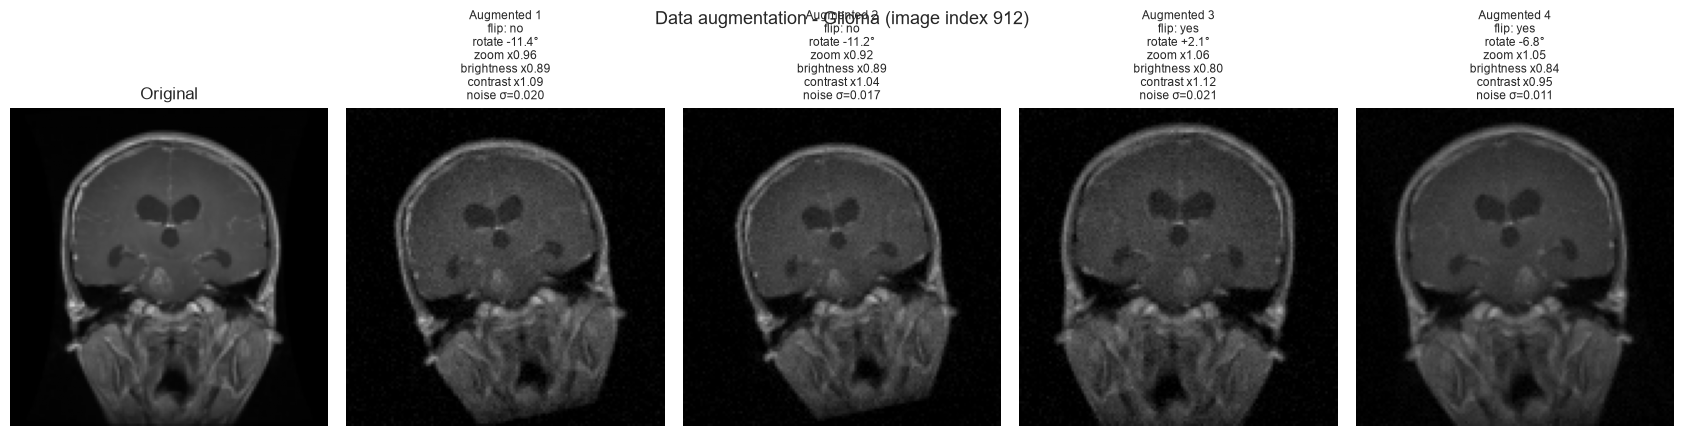

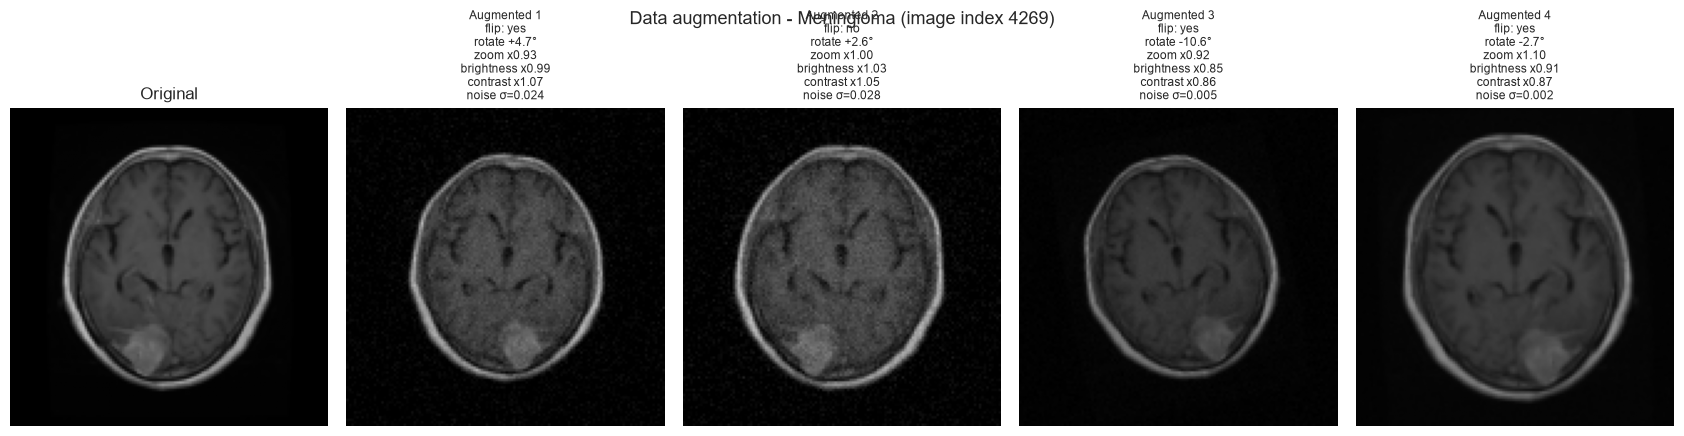

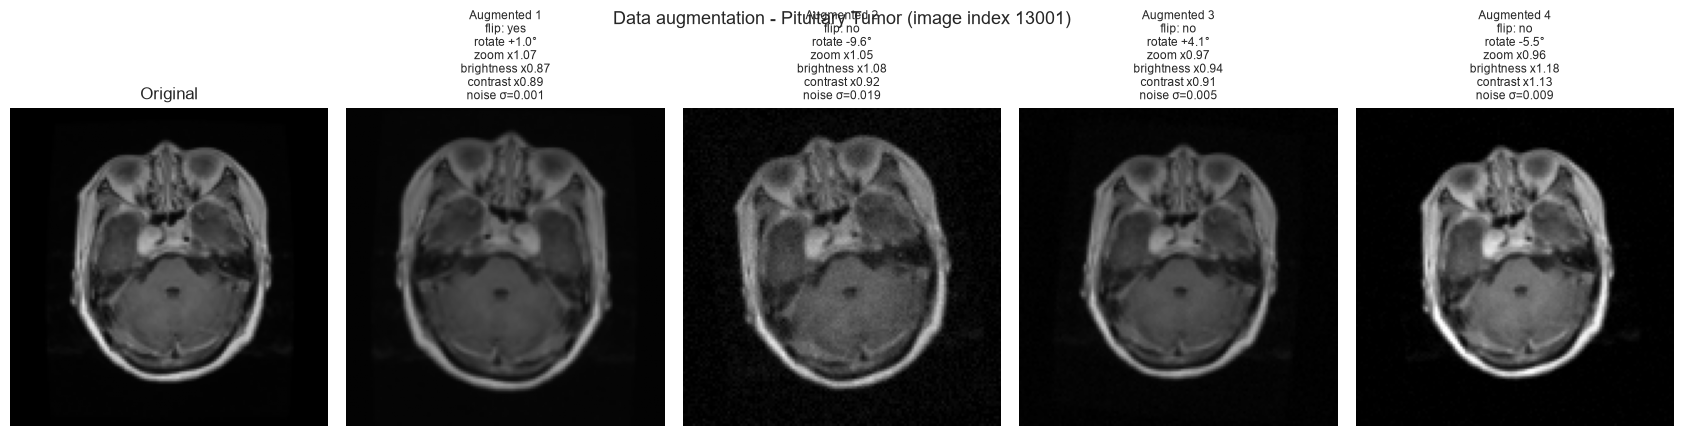

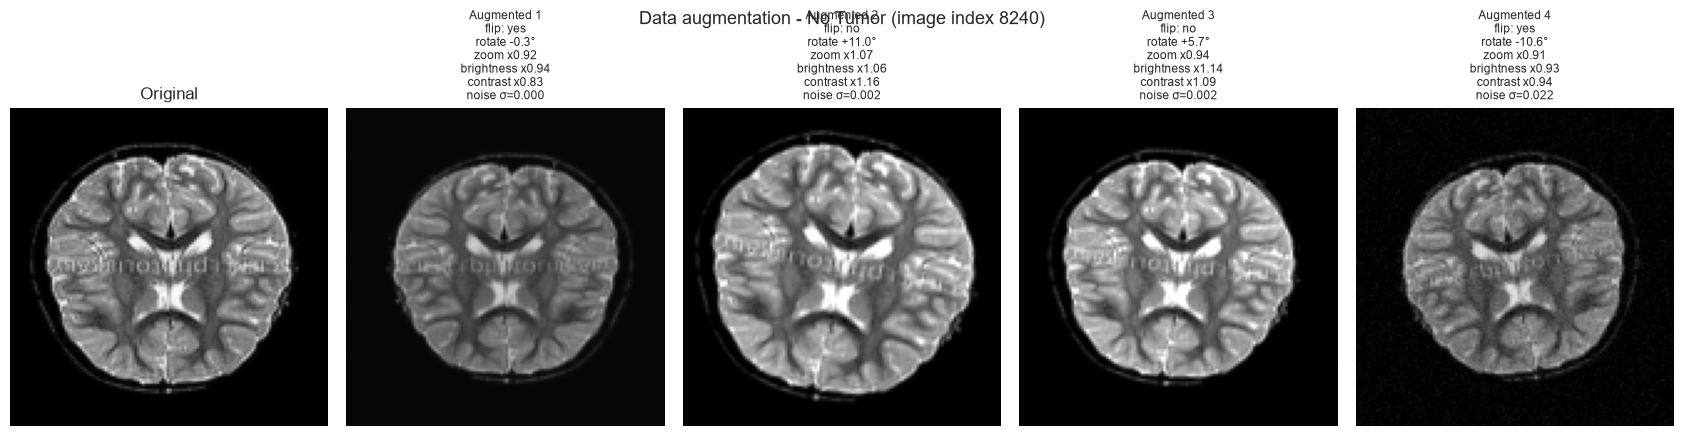

,Class,Representative image (file/index),Augmentations applied (with parameters)
0,Glioma,00913.jpg / 912,"#1: flip=N, rot -11.4 deg, zoom x0.96, bright x0.89, contrast x1.09, noise 0.020 | #2: flip=N, rot -11.2 deg, zoom x0.92, bright x0.89, contrast x1.04, noise 0.017 | #3: flip=Y, rot +2.1 deg, zoom x1.06, bright x0.80, contrast x1.12, noise 0.021 | #4: flip=Y, rot -6.8 deg, zoom x1.05, bright x0.84, contrast x0.95, noise 0.011"
1,Meningioma,00103.png / 4269,"#1: flip=Y, rot +4.7 deg, zoom x0.93, bright x0.99, contrast x1.07, noise 0.024 | #2: flip=N, rot +2.6 deg, zoom x1.00, bright x1.03, contrast x1.05, noise 0.028 | #3: flip=Y, rot -10.6 deg, zoom x0.92, bright x0.85, contrast x0.86, noise 0.005 | #4: flip=Y, rot -2.7 deg, zoom x1.10, bright x0.91, contrast x0.87, noise 0.002"
2,Pituitary Tumor,03038.png / 13001,"#1: flip=Y, rot +1.0 deg, zoom x1.07, bright x0.87, contrast x0.89, noise 0.001 | #2: flip=N, rot -9.6 deg, zoom x1.05, bright x1.08, contrast x0.92, noise 0.019 | #3: flip=N, rot +4.1 deg, zoom x0.97, bright x0.94, contrast x0.91, noise 0.005 | #4: flip=N, rot -5.5 deg, zoom x0.96, bright x1.18, contrast x1.13, noise 0.009"
3,No Tumor,01127.jpg / 8240,"#1: flip=Y, rot -0.3 deg, zoom x0.92, bright x0.94, contrast x0.83, noise 0.000 | #2: flip=N, rot +11.0 deg, zoom x1.07, bright x1.06, contrast x1.16, noise 0.002 | #3: flip=N, rot +5.7 deg, zoom x0.94, bright x1.14, contrast x1.09, noise 0.002 | #4: flip=Y, rot -10.6 deg, zoom x0.91, bright x0.93, contrast x0.94, noise 0.022"


In [15]:
aug_log_rows = []
for c in CLASS_KEYS:
    base = IMAGES[REP[c]['index']].float() / 255.0
    rng = random.Random(SEED + class_to_idx[c])
    fig, axes = plt.subplots(1, 5, figsize=(17, 4.6))
    axes[0].imshow(base[0], cmap='gray', vmin=0, vmax=1); axes[0].set_title('Original'); axes[0].axis('off')
    descr = []
    for k in range(4):
        p = AUG.sample_params(rng)
        out = AUG.apply(base, p)
        axes[k + 1].imshow(out[0], cmap='gray', vmin=0, vmax=1)
        axes[k + 1].set_title(f'Augmented {k+1}\n' + MRIAugment.describe(p), fontsize=8.5); axes[k + 1].axis('off')
        descr.append(f"#{k+1}: flip={'Y' if p['flip'] else 'N'}, rot {p['angle']:+.1f} deg, zoom x{p['zoom']:.2f}, "
                     f"bright x{p['brightness']:.2f}, contrast x{p['contrast']:.2f}, noise {p['noise']:.3f}")
    fig.suptitle(f"Data augmentation - {CLASS_TITLES[c]} (image index {REP[c]['index']})", fontsize=13)
    fig.tight_layout()
    savefig(fig, f'fig_augmentation_{c}.png'); plt.show()
    aug_log_rows.append({'Class': CLASS_TITLES[c], 'Representative image (file/index)': f"{os.path.basename(REP[c]['path'])} / {REP[c]['index']}",
                         'Augmentations applied (with parameters)': ' | '.join(descr)})
pd.set_option('display.max_colwidth', None)
display(pd.DataFrame(aug_log_rows))

## 3.1 Question
Augmentation choices that are safe for natural-image datasets (e.g. ImageNet) are not automatically safe for medical imaging. For **each** augmentation you used (horizontal flip, rotation, brightness/contrast, zoom, noise), state one reason it is anatomically or diagnostically acceptable for brain MRI, and explain why a vertical flip would *not* be acceptable.

### Answer

- **Horizontal flip:** the brain is roughly left-right symmetric and tumors can appear on either side, so a mirrored scan still looks like a real brain with the same tumor type.
- **Rotation ($\pm 12^\circ$):** a patient's head is never placed in the scanner at exactly the same angle, so a small tilt is normal.
- **Brightness/contrast:** different scanners and settings give different brightness and contrast, so this copies a real variation.
- **Zoom (0.9-1.1):** head size and the scanner's field of view differ between patients, so a slight zoom just changes the scale, not the anatomy.
- **Mild noise:** real MRI always has some noise, so this helps the model not depend on exact pixel values.
- **Why not a vertical flip:** it turns the brain upside down. In real MRI scans the head always has the same up-down orientation, so upside-down brains never appear. Position also matters for diagnosis (for example, pituitary tumors sit at the base of the brain), so a vertical flip would teach the model a wrong picture of the anatomy.

---
# 4. Convolution Mathematics (every class)

For each class, a $6\times6$ patch of the representative image is convolved **by hand** (explicit loops) with one fixed $3\times3$ vertical-edge kernel (stride 1, no padding), then checked against `F.conv2d`.

$$K=\begin{bmatrix}-1&0&1\\-1&0&1\\-1&0&1\end{bmatrix},\qquad
\text{Output}=\left\lfloor\frac{\text{Input}+2P-K}{S}\right\rfloor+1,\qquad
\text{RF}_l=\text{RF}_{l-1}+(k_l-1)\prod_{i<l}s_i$$

## 4.1 Choose the patch
Patch top-left corners (row, col): Glioma (64, 54), Meningioma (90, 38), Pituitary Tumor (52, 52), No Tumor (61, 61).

In [123]:
PATCH = 6
KERNEL = torch.tensor([[-1., 0., 1.], [-1., 0., 1.], [-1., 0., 1.]])

def default_patch_topleft(gray_u8, cls, p=PATCH):
    """Heuristic start point only - the student should inspect and adjust it."""
    H, W = gray_u8.shape
    if cls == 'notumor':
        return (H // 2 - p // 2, W // 2 - p // 2)
    m = H // 4
    g = gray_u8[m:H - m, m:W - m].astype(float)
    ii = np.cumsum(np.cumsum(np.pad(g, ((1, 0), (1, 0))), 0), 1)
    win = ii[p:, p:] - ii[:-p, p:] - ii[p:, :-p] + ii[:-p, :-p]
    r, c = np.unravel_index(np.argmax(win), win.shape)
    return (int(r + m), int(c + m))

GRAY = {c: IMAGES[REP[c]['index']][0].numpy() for c in CLASS_KEYS}
PATCH_TOPLEFT = {c: default_patch_topleft(GRAY[c], c) for c in CLASS_KEYS}
PATCH_TOPLEFT.update({'glioma': (64, 54), 'meningioma': (90, 38)})
print('Current patch top-left (row, col):', PATCH_TOPLEFT)

Current patch top-left (row, col): {'glioma': (64, 54), 'meningioma': (90, 38), 'pituitary': (52, 52), 'notumor': (61, 61)}


## 4.2 Manual convolution, PyTorch check, and dimension/RF formulas

In [124]:
def manual_conv2d_valid(patch, kernel, stride=1, verbose=False):
    """Cross-correlation written with plain loops (this is what deep-learning frameworks call 'convolution')."""
    H, W = patch.shape; k = kernel.shape[0]
    oh, ow = (H - k) // stride + 1, (W - k) // stride + 1
    out = np.zeros((oh, ow))
    for i in range(oh):
        for j in range(ow):
            region = patch[i*stride:i*stride+k, j*stride:j*stride+k]
            terms = region * kernel
            out[i, j] = terms.sum()
            if verbose:
                s = ' + '.join(f'({int(region[a, b])}*{int(kernel[a, b])})' for a in range(k) for b in range(k))
                print(f'  out[{i},{j}] = {s} = {out[i, j]:.0f}')
    return out

def conv_out_size(n, k, s=1, p=0):
    return (n + 2 * p - k) // s + 1

def receptive_field(layers):
    """layers = [(kernel, stride), ...] -> receptive field of one unit after the last layer."""
    rf, jump = 1, 1
    for k, s in layers:
        rf += (k - 1) * jump
        jump *= s
    return rf

K_NP = KERNEL.numpy()
conv_summary = []
CONV_RESULTS = {}
for c in CLASS_KEYS:
    r0, c0 = PATCH_TOPLEFT[c]
    patch = GRAY[c][r0:r0 + PATCH, c0:c0 + PATCH].astype(float)
    print(f'===== {CLASS_TITLES[c]}: patch rows {r0}:{r0+PATCH}, cols {c0}:{c0+PATCH} =====')
    print('Patch pixel values:\n', patch.astype(int))
    manual = manual_conv2d_valid(patch, K_NP, stride=1, verbose=True)
    torch_out = F.conv2d(torch.tensor(patch, dtype=torch.float32)[None, None], KERNEL[None, None], bias=None, stride=1, padding=0)[0, 0].numpy()
    ok = np.allclose(manual, torch_out, atol=1e-5)
    print('Manual == PyTorch F.conv2d ?', ok, '| max abs diff =', float(np.abs(manual - torch_out).max()))
    assert ok, 'manual and PyTorch results differ'
    oh = conv_out_size(PATCH, 3, 1, 0)
    assert manual.shape == (oh, oh)
    rf1, rf2 = receptive_field([(3, 1)]), receptive_field([(3, 1), (3, 1)])
    print(f'Output size = floor(({PATCH} + 0 - 3)/1) + 1 = {oh}  ->  {oh} x {oh}')
    print(f'Receptive field: 1 layer = {rf1}, 2 stacked layers = {rf2}\n')
    CONV_RESULTS[c] = dict(patch=patch, manual=manual, torch=torch_out, rf1=rf1, rf2=rf2, topleft=(r0, c0))
    conv_summary.append({'Class': CLASS_TITLES[c], 'Patch': f'{PATCH}x{PATCH} @ ({r0},{c0})', 'Kernel': '3x3', 'Stride': 1, 'Pad': 0,
                         'Output': f'{oh}x{oh}', 'RF (1L)': rf1, 'RF (2L)': rf2})

===== Glioma: patch rows 64:70, cols 54:60 =====
Patch pixel values:
 [[ 83  87  69  70  87 103]
 [ 87  81  69  77 104 108]
 [ 73  71  71  83 115 113]
 [ 79  68  68  84 124 114]
 [ 69  68  75 104 109 103]
 [ 65  72  92  97  88 101]]
  out[0,0] = (83*-1) + (87*0) + (69*1) + (87*-1) + (81*0) + (69*1) + (73*-1) + (71*0) + (71*1) = -34
  out[0,1] = (87*-1) + (69*0) + (70*1) + (81*-1) + (69*0) + (77*1) + (71*-1) + (71*0) + (83*1) = -9
  out[0,2] = (69*-1) + (70*0) + (87*1) + (69*-1) + (77*0) + (104*1) + (71*-1) + (83*0) + (115*1) = 97
  out[0,3] = (70*-1) + (87*0) + (103*1) + (77*-1) + (104*0) + (108*1) + (83*-1) + (115*0) + (113*1) = 94
  out[1,0] = (87*-1) + (81*0) + (69*1) + (73*-1) + (71*0) + (71*1) + (79*-1) + (68*0) + (68*1) = -31
  out[1,1] = (81*-1) + (69*0) + (77*1) + (71*-1) + (71*0) + (83*1) + (68*-1) + (68*0) + (84*1) = 24
  out[1,2] = (69*-1) + (77*0) + (104*1) + (71*-1) + (83*0) + (115*1) + (68*-1) + (84*0) + (124*1) = 135
  out[1,3] = (77*-1) + (104*0) + (108*1) + (83*-1) + (

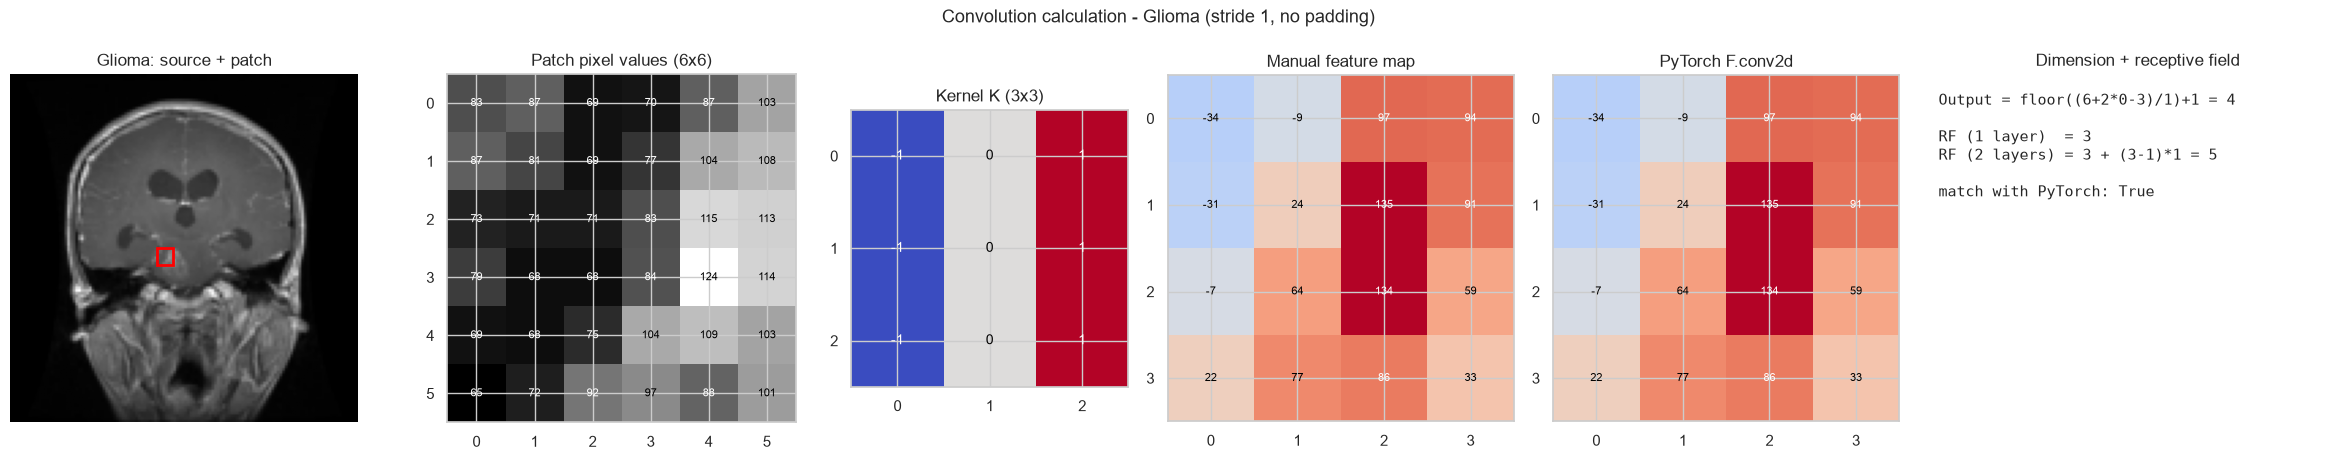

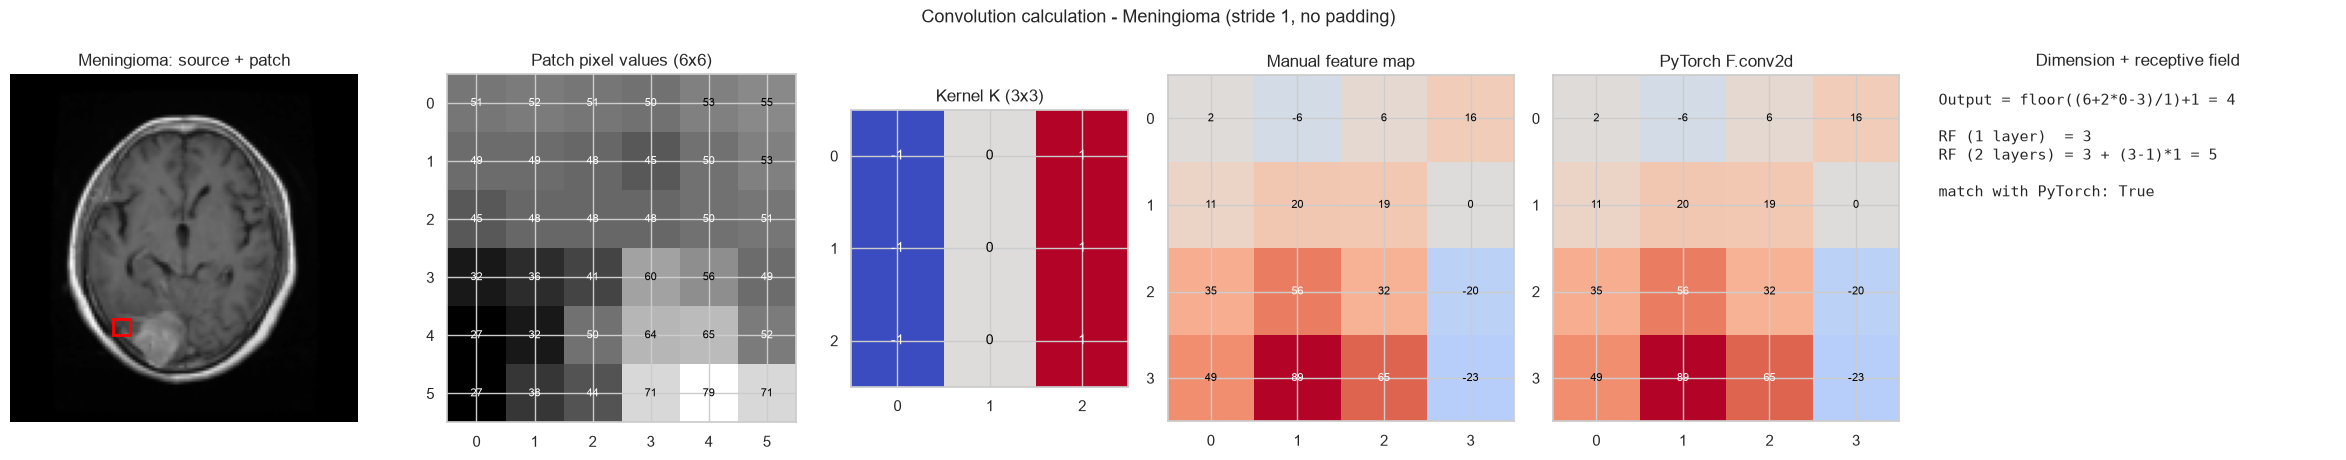

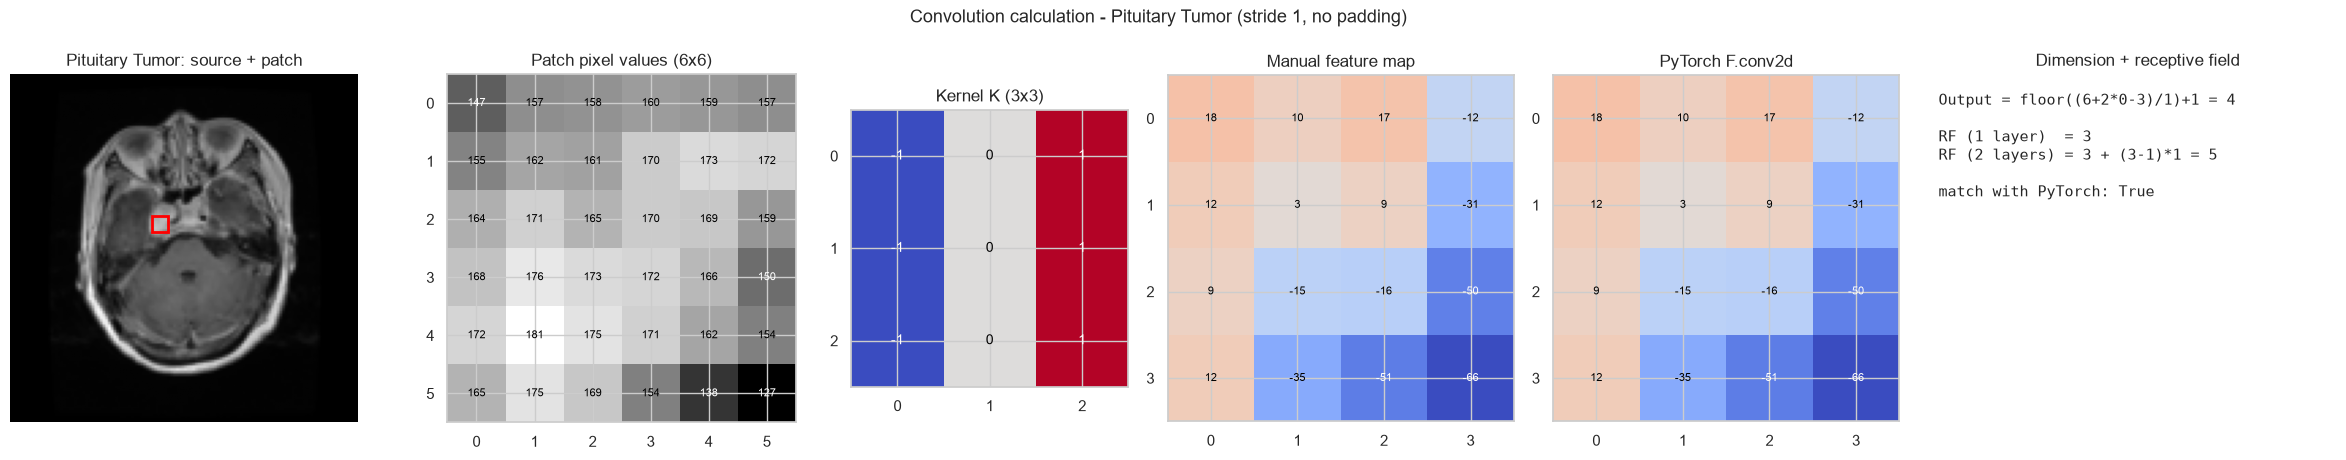

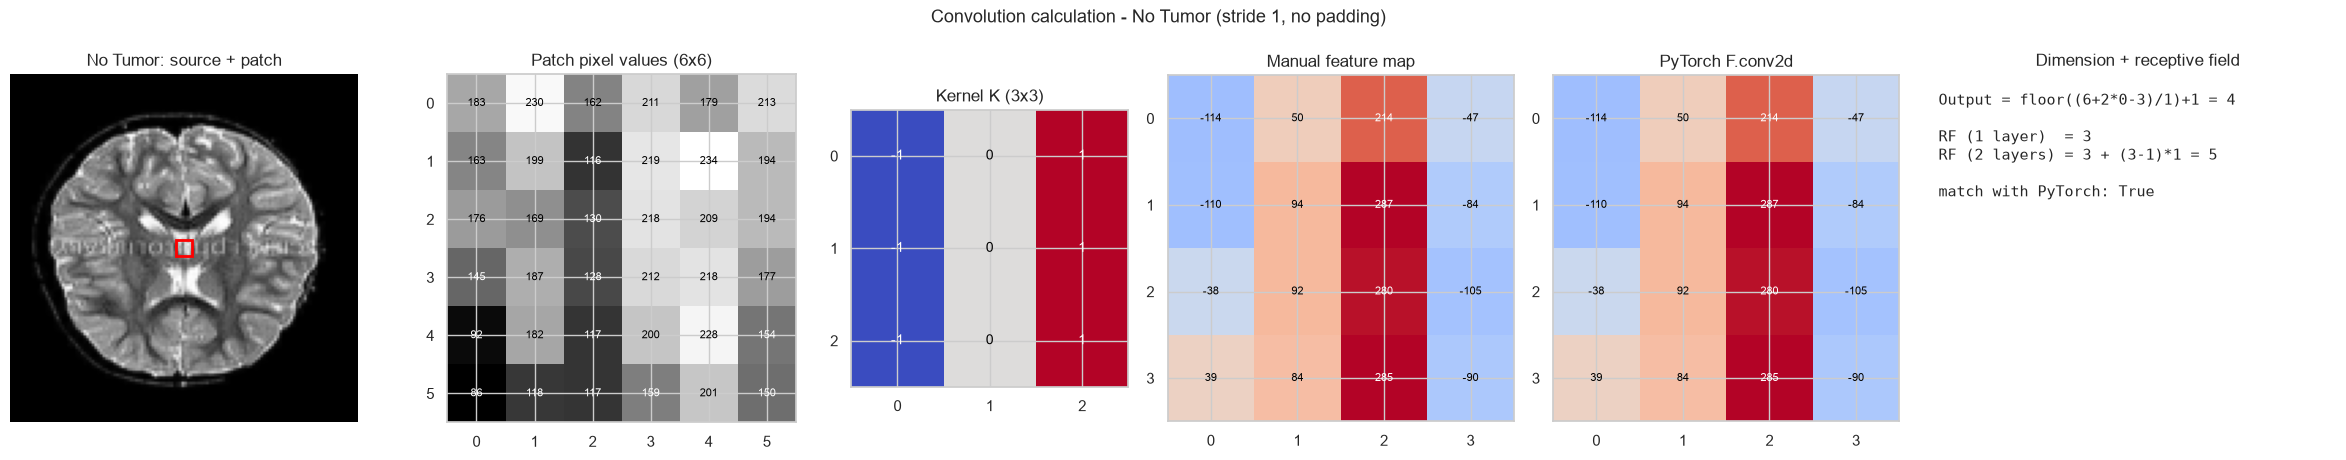

,Class,Patch,Kernel,Stride,Pad,Output,RF (1L),RF (2L)
0,Glioma,"6x6 @ (64,54)",3x3,1,0,4x4,3,5
1,Meningioma,"6x6 @ (90,38)",3x3,1,0,4x4,3,5
2,Pituitary Tumor,"6x6 @ (52,52)",3x3,1,0,4x4,3,5
3,No Tumor,"6x6 @ (61,61)",3x3,1,0,4x4,3,5


In [125]:
def annotate_heat(ax, m, fmt='{:.0f}', cmap='gray', center_zero=False, fs=8):
    vmax = np.abs(m).max() if center_zero else None
    im = ax.imshow(m, cmap=cmap, vmin=-vmax if center_zero else None, vmax=vmax)
    thr = (m.max() + m.min()) / 2
    for (i, j), v in np.ndenumerate(m):
        ax.text(j, i, fmt.format(v), ha='center', va='center', fontsize=fs,
                color='white' if (not center_zero and v < thr) or (center_zero and abs(v) > 0.6 * vmax) else 'black')
    ax.set_xticks(range(m.shape[1])); ax.set_yticks(range(m.shape[0]))

for c in CLASS_KEYS:
    R = CONV_RESULTS[c]; r0, c0 = R['topleft']
    fig, axes = plt.subplots(1, 6, figsize=(24, 4.4), gridspec_kw=dict(width_ratios=[1.2, 1.1, 0.8, 1, 1, 1.15]))
    axes[0].imshow(GRAY[c], cmap='gray')
    axes[0].add_patch(plt.Rectangle((c0 - 0.5, r0 - 0.5), PATCH, PATCH, fill=False, ec='red', lw=2))
    axes[0].set_title(f'{CLASS_TITLES[c]}: source + patch'); axes[0].axis('off')
    annotate_heat(axes[1], R['patch']); axes[1].set_title(f'Patch pixel values ({PATCH}x{PATCH})')
    annotate_heat(axes[2], K_NP, center_zero=True, cmap='coolwarm', fs=10); axes[2].set_title('Kernel K (3x3)')
    annotate_heat(axes[3], R['manual'], center_zero=True, cmap='coolwarm'); axes[3].set_title('Manual feature map')
    annotate_heat(axes[4], R['torch'], center_zero=True, cmap='coolwarm'); axes[4].set_title('PyTorch F.conv2d')
    oh = R['manual'].shape[0]
    axes[5].axis('off')
    axes[5].text(0, 0.95, f"Output = floor(({PATCH}+2*0-3)/1)+1 = {oh}\n\n"
                          f"RF (1 layer)  = 3\nRF (2 layers) = 3 + (3-1)*1 = {R['rf2']}\n\n"
                          f"match with PyTorch: {np.allclose(R['manual'], R['torch'])}", va='top', fontsize=11, family='monospace')
    axes[5].set_title('Dimension + receptive field')
    fig.suptitle(f'Convolution calculation - {CLASS_TITLES[c]} (stride 1, no padding)', fontsize=13)
    fig.tight_layout(); savefig(fig, f'fig_convolution_{c}.png'); plt.show()

display(pd.DataFrame(conv_summary))

In [19]:
c = CLASS_KEYS[0]; patch = CONV_RESULTS[c]['patch']
true_conv = manual_conv2d_valid(patch, np.flip(K_NP, axis=(0, 1)))
print('Cross-correlation (what F.conv2d does):\n', CONV_RESULTS[c]['torch'])
print('True convolution (kernel flipped 180 deg):\n', true_conv)
print('Same result?', np.allclose(true_conv, CONV_RESULTS[c]['torch']))

Cross-correlation (what F.conv2d does):
 [[ -20.   93.   92.   12.]
 [-170.   23.  100.   80.]
 [-252. -153.   88.  203.]
 [-116. -207.   -1.  209.]]
True convolution (kernel flipped 180 deg):
 [[  20.  -93.  -92.  -12.]
 [ 170.  -23. -100.  -80.]
 [ 252.  153.  -88. -203.]
 [ 116.  207.    1. -209.]]
Same result? False


## 4.3 Questions
**(a)** Why must your manual calculation and the PyTorch `F.conv2d` output match exactly (within floating-point tolerance)? What would a mismatch most likely indicate about kernel orientation (true mathematical convolution, which flips the kernel, versus the cross-correlation that deep learning frameworks actually compute)?

**(b)** Compare the receptive field after 1 layer versus after 2 stacked $3\times3$ layers. Is this consistent with the general principle that two stacked $3\times3$ convolutions can approximate the receptive field of one $5\times5$ convolution? Show the arithmetic.

### Answer

**(a)** `F.conv2d` does the same arithmetic as my loops: slide the kernel over the patch, multiply the matching numbers, and add them up. Same operation on the same numbers means the results must agree, except for tiny floating-point rounding. They matched exactly for all four classes (max absolute difference 0.0).

One detail: what deep learning libraries call "convolution" is really cross-correlation (the kernel is not flipped). True mathematical convolution flips the kernel by 180 degrees first. I tested this on the Glioma patch: the flipped-kernel result was exactly the negative of PyTorch's result (for example -20 became 20 and 93 became -93), because this kernel flipped by 180 degrees is just $-K$. So if a manual result matches PyTorch except that every sign is opposite, the most likely cause is a flipped kernel orientation.

**(b)** After 1 layer the receptive field is 3. After 2 stacked $3\times3$ layers, stride 1:

$$\text{RF}_2 = 3 + (3-1)\times 1 = 5$$

One $5\times5$ convolution also has a receptive field of 5, so yes, two stacked $3\times3$ layers see the same area as one $5\times5$. The stack also has fewer weights (see Section 8.3) and an extra non-linearity between the two layers.

---
# 5. Implementation and Comparison (Experiment 1)

Six architectures, all trained **from scratch** on the *same* splits, preprocessing and metrics, with **one fixed optimizer** (`BASE_OPT`, Adam lr 1e-3), the same batch size, epoch budget, early-stopping rule and seed.

All networks are `StagedNet` objects: an ordered list of named blocks, so the tensor shape after every major block can be printed. They are scaled-down versions for `IMG_SIZE x IMG_SIZE` grayscale input. BatchNorm is used in AlexNet and VGG so they train reliably in a small epoch budget (the original AlexNet used LRN and no BN).

## 5.1 Model definitions

In [13]:
def conv_bn_act(cin, cout, k, s=1, p=None, groups=1, act=nn.ReLU):
    if p is None:
        p = (k - 1) // 2
    return nn.Sequential(nn.Conv2d(cin, cout, k, s, p, groups=groups, bias=False), nn.BatchNorm2d(cout), act(inplace=True))

class StagedNet(nn.Module):
    """A network is an ordered dict of named blocks -> easy shape tracing."""
    def __init__(self, stages):
        super().__init__()
        self.stages = nn.Sequential(OrderedDict(stages))
    def forward(self, x):
        return self.stages(x)

def infer_flat_dim(module, in_ch, size):
    was = module.training; module.eval()
    with torch.no_grad():
        n = module(torch.zeros(1, in_ch, size, size)).flatten(1).shape[1]
    module.train(was)
    return n


class LeNet5(StagedNet):
    """Classic LeNet-5: 2 x (conv5 + tanh + avg-pool) then 120-84-classes MLP."""
    def __init__(self, in_ch=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE):
        c1 = nn.Sequential(nn.Conv2d(in_ch, 6, 5), nn.Tanh(), nn.AvgPool2d(2, 2))
        c2 = nn.Sequential(nn.Conv2d(6, 16, 5), nn.Tanh(), nn.AvgPool2d(2, 2))
        flat = infer_flat_dim(nn.Sequential(c1, c2), in_ch, img_size)
        super().__init__([('conv1_pool', c1), ('conv2_pool', c2), ('flatten', nn.Flatten()),
                          ('fc1', nn.Sequential(nn.Linear(flat, 120), nn.Tanh())),
                          ('fc2', nn.Sequential(nn.Linear(120, 84), nn.Tanh())),
                          ('out', nn.Linear(84, num_classes))])
        self.flat_dim = flat


class AlexNet(StagedNet):
    def __init__(self, in_ch=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE, dropout=0.5):
        mp = lambda: nn.MaxPool2d(3, 2)
        super().__init__([
            ('conv1', nn.Sequential(conv_bn_act(in_ch, 64, 11, s=4, p=2), mp())),
            ('conv2', nn.Sequential(conv_bn_act(64, 192, 5, p=2), mp())),
            ('conv3', conv_bn_act(192, 384, 3)),
            ('conv4', conv_bn_act(384, 256, 3)),
            ('conv5', nn.Sequential(conv_bn_act(256, 256, 3), mp())),
            ('avgpool', nn.AdaptiveAvgPool2d((3, 3))),
            ('flatten', nn.Flatten()),
            ('fc6', nn.Sequential(nn.Dropout(dropout), nn.Linear(256 * 9, 1024), nn.ReLU(inplace=True))),
            ('fc7', nn.Sequential(nn.Dropout(dropout), nn.Linear(1024, 1024), nn.ReLU(inplace=True))),
            ('out', nn.Linear(1024, num_classes))])
        self.flat_dim = 256 * 9


class VGG(StagedNet):
    """VGG-style: stacks of 3x3 convs + max-pool (5 blocks), BN, then a 2-layer classifier."""
    def __init__(self, in_ch=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE,
                 cfg=((32,), (64,), (128, 128), (256, 256), (256, 256)), fc=512, dropout=0.5):
        stages, c = [], in_ch
        for b, widths in enumerate(cfg, 1):
            layers = []
            for w in widths:
                layers.append(conv_bn_act(c, w, 3)); c = w
            layers.append(nn.MaxPool2d(2, 2))
            stages.append((f'block{b}', nn.Sequential(*layers)))
        stages += [('avgpool', nn.AdaptiveAvgPool2d((2, 2))), ('flatten', nn.Flatten()),
                   ('fc1', nn.Sequential(nn.Linear(c * 4, fc), nn.ReLU(inplace=True), nn.Dropout(dropout))),
                   ('out', nn.Linear(fc, num_classes))]
        super().__init__(stages)
        self.flat_dim = c * 4


class Inception(nn.Module):
    def __init__(self, cin, c1, c3r, c3, c5r, c5, cp):
        super().__init__()
        self.b1 = conv_bn_act(cin, c1, 1)
        self.b2 = nn.Sequential(conv_bn_act(cin, c3r, 1), conv_bn_act(c3r, c3, 3))
        self.b3 = nn.Sequential(conv_bn_act(cin, c5r, 1), conv_bn_act(c5r, c5, 5))
        self.b4 = nn.Sequential(nn.MaxPool2d(3, 1, 1), conv_bn_act(cin, cp, 1))
        self.out_channels = c1 + c3 + c5 + cp
    def forward(self, x):
        return torch.cat([self.b1(x), self.b2(x), self.b3(x), self.b4(x)], dim=1)

class GoogLeNetLite(StagedNet):
    """Inception-inspired: stem -> 2 inception modules -> pool -> 2 inception modules -> GAP -> FC (no auxiliary heads)."""
    def __init__(self, in_ch=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE, dropout=0.4):
        i3a = Inception(64, 16, 24, 32, 4, 8, 8)
        i3b = Inception(i3a.out_channels, 32, 32, 48, 8, 24, 16)
        i4a = Inception(i3b.out_channels, 48, 32, 64, 8, 16, 16)
        i4b = Inception(i4a.out_channels, 64, 48, 96, 12, 32, 32)
        super().__init__([
            ('stem', nn.Sequential(conv_bn_act(in_ch, 32, 7, s=2), nn.MaxPool2d(3, 2, 1), conv_bn_act(32, 64, 3), nn.MaxPool2d(3, 2, 1))),
            ('inception3a', i3a), ('inception3b', i3b), ('pool3', nn.MaxPool2d(3, 2, 1)),
            ('inception4a', i4a), ('inception4b', i4b),
            ('gap', nn.AdaptiveAvgPool2d(1)), ('flatten', nn.Flatten()),
            ('out', nn.Sequential(nn.Dropout(dropout), nn.Linear(i4b.out_channels, num_classes)))])
        self.flat_dim = i4b.out_channels


class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(cout)
        self.short = nn.Identity() if (stride == 1 and cin == cout) else \
            nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)), inplace=True)
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.short(x), inplace=True)

class ResNetSmall(StagedNet):
    def __init__(self, in_ch=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE, layers=(2, 2, 2, 2), base=32):
        stages = [('stem', nn.Sequential(conv_bn_act(in_ch, base, 7, s=2), nn.MaxPool2d(3, 2, 1)))]
        c = base
        for i, n in enumerate(layers):
            w = base * 2 ** i
            blocks = [BasicBlock(c, w, stride=1 if i == 0 else 2)] + [BasicBlock(w, w) for _ in range(n - 1)]
            stages.append((f'layer{i+1}', nn.Sequential(*blocks))); c = w
        stages += [('gap', nn.AdaptiveAvgPool2d(1)), ('flatten', nn.Flatten()), ('out', nn.Linear(c, num_classes))]
        super().__init__(stages)
        self.flat_dim = c


class SqueezeExcite(nn.Module):
    def __init__(self, ch, reduced):
        super().__init__()
        self.fc1, self.fc2 = nn.Conv2d(ch, reduced, 1), nn.Conv2d(reduced, ch, 1)
    def forward(self, x):
        s = F.adaptive_avg_pool2d(x, 1)
        return x * torch.sigmoid(self.fc2(F.silu(self.fc1(s))))

class MBConv(nn.Module):
    """Inverted residual: 1x1 expand -> depthwise kxk -> squeeze-excite -> 1x1 project (linear)."""
    def __init__(self, cin, cout, expand, k, stride):
        super().__init__()
        mid = cin * expand
        layers = []
        if expand != 1:
            layers.append(conv_bn_act(cin, mid, 1, act=nn.SiLU))
        layers += [conv_bn_act(mid, mid, k, s=stride, groups=mid, act=nn.SiLU),
                   SqueezeExcite(mid, max(1, cin // 4)),
                   nn.Conv2d(mid, cout, 1, bias=False), nn.BatchNorm2d(cout)]
        self.block = nn.Sequential(*layers)
        self.use_res = (stride == 1 and cin == cout)
    def forward(self, x):
        out = self.block(x)
        return x + out if self.use_res else out

def _round8(c):
    return max(8, int(c + 4) // 8 * 8)

class EfficientNetLite(StagedNet):
    """B0 layout (expand, kernel, channels, repeats, stride) shrunk with width/depth multipliers (compound scaling idea)."""
    SETTINGS = [(1, 3, 16, 1, 1), (6, 3, 24, 2, 2), (6, 5, 40, 2, 2), (6, 3, 80, 3, 2), (6, 5, 112, 3, 1), (6, 5, 192, 4, 2), (6, 3, 320, 1, 1)]
    def __init__(self, in_ch=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE, width_mult=0.5, depth_mult=0.5, dropout=0.3):
        c = _round8(32 * width_mult)
        stages = [('stem', conv_bn_act(in_ch, c, 3, s=2, act=nn.SiLU))]
        for i, (e, k, ch, n, s) in enumerate(self.SETTINGS, 1):
            cout, reps = _round8(ch * width_mult), max(1, math.ceil(n * depth_mult))
            blocks = [MBConv(c, cout, e, k, s)] + [MBConv(cout, cout, e, k, 1) for _ in range(reps - 1)]
            stages.append((f'mbconv{i}', nn.Sequential(*blocks))); c = cout
        head = _round8(1280 * width_mult / 2)
        stages += [('head', conv_bn_act(c, head, 1, act=nn.SiLU)), ('gap', nn.AdaptiveAvgPool2d(1)), ('flatten', nn.Flatten()),
                   ('out', nn.Sequential(nn.Dropout(dropout), nn.Linear(head, num_classes)))]
        super().__init__(stages)
        self.flat_dim = head


MODEL_ZOO = OrderedDict([('LeNet-5', LeNet5), ('AlexNet', AlexNet), ('VGG', VGG),
                         ('GoogLeNet', GoogLeNetLite), ('ResNet', ResNetSmall), ('EfficientNet', EfficientNetLite)])
ARCHS = list(MODEL_ZOO)
print('Architectures:', ARCHS)

Architectures: ['LeNet-5', 'AlexNet', 'VGG', 'GoogLeNet', 'ResNet', 'EfficientNet']


## 5.2 Model summary utilities

In [14]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

LAYER_GROUPS = OrderedDict([
    ('Convolutional', (nn.Conv2d,)),
    ('Pooling', (nn.MaxPool2d, nn.AvgPool2d, nn.AdaptiveAvgPool2d, nn.AdaptiveMaxPool2d)),
    ('Activation', (nn.ReLU, nn.Tanh, nn.SiLU, nn.Sigmoid, nn.Hardswish)),
    ('Normalization', (nn.BatchNorm2d,)),
    ('Fully connected', (nn.Linear,)),
    ('Dropout / Flatten', (nn.Dropout, nn.Flatten))])

def layer_type_table(model):
    """Counts of leaf layers by type (convolutional / pooling / activation / normalization / fully connected)."""
    leaves = [m for m in model.modules() if len(list(m.children())) == 0]
    return pd.Series({g: sum(isinstance(m, types) for m in leaves) for g, types in LAYER_GROUPS.items()}, name='count')

def shape_trace(model, in_ch=1, size=IMG_SIZE):
    rows, hooks = [], []
    for name, m in model.stages.named_children():
        hooks.append(m.register_forward_hook(lambda mod, inp, out, name=name: rows.append((name, tuple(out.shape[1:])))))
    was = model.training; model.eval()
    with torch.no_grad():
        model(torch.zeros(1, in_ch, size, size))
    model.train(was)
    for h in hooks:
        h.remove()
    return pd.DataFrame(rows, columns=['block', 'output shape (no batch dim)'])

SHOW_FULL_MODEL = True
def model_report(name, model):
    print('=' * 80); print(f'{name}  |  trainable parameters = {count_params(model):,}')
    if SHOW_FULL_MODEL:
        print(model)
    display(layer_type_table(model).to_frame().T)
    display(shape_trace(model, size=IMG_SIZE))
    if hasattr(model, 'flat_dim'):
        print('Feature dimension entering the classifier (flattened / pooled):', model.flat_dim)

for name in ARCHS:
    set_seed(SEED)
    model_report(name, MODEL_ZOO[name](in_ch=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE))

LeNet-5  |  trainable parameters = 1,627,916
LeNet5(
  (stages): Sequential(
    (conv1_pool): Sequential(
      (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
      (1): Tanh()
      (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    )
    (conv2_pool): Sequential(
      (0): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
      (1): Tanh()
      (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    )
    (flatten): Flatten(start_dim=1, end_dim=-1)
    (fc1): Sequential(
      (0): Linear(in_features=13456, out_features=120, bias=True)
      (1): Tanh()
    )
    (fc2): Sequential(
      (0): Linear(in_features=120, out_features=84, bias=True)
      (1): Tanh()
    )
    (out): Linear(in_features=84, out_features=4, bias=True)
  )
)


,Convolutional,Pooling,Activation,Normalization,Fully connected,Dropout / Flatten
count,2,2,4,0,3,1


,block,output shape (no batch dim)
0,conv1_pool,"(6, 62, 62)"
1,conv2_pool,"(16, 29, 29)"
2,flatten,"(13456,)"
3,fc1,"(120,)"
4,fc2,"(84,)"
5,out,"(4,)"


Feature dimension entering the classifier (flattened / pooled): 13456
AlexNet  |  trainable parameters = 5,869,380
AlexNet(
  (stages): Sequential(
    (conv1): Sequential(
      (0): Sequential(
        (0): Conv2d(1, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (1): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (conv2): Sequential(
      (0): Sequential(
        (0): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
        (1): BatchNorm2d(192, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (1): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (conv3): Sequential(
      (0): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
     

,Convolutional,Pooling,Activation,Normalization,Fully connected,Dropout / Flatten
count,5,4,7,5,3,3


,block,output shape (no batch dim)
0,conv1,"(64, 15, 15)"
1,conv2,"(192, 7, 7)"
2,conv3,"(384, 7, 7)"
3,conv4,"(256, 7, 7)"
4,conv5,"(256, 3, 3)"
5,avgpool,"(256, 3, 3)"
6,flatten,"(2304,)"
7,fc6,"(1024,)"
8,fc7,"(1024,)"
9,out,"(4,)"


... (9 outputs left out)

Feature dimension entering the classifier (flattened / pooled): 256
EfficientNet  |  trainable parameters = 606,276
EfficientNetLite(
  (stages): Sequential(
    (stem): Sequential(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (mbconv1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Sequential(
            (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
            (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcite(
            (fc1): Conv2d(16, 4, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(4, 16, kernel_size=(1, 1), stride=(1, 1))
          )
          (2): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1), bias=Fal

,Convolutional,Pooling,Activation,Normalization,Fully connected,Dropout / Flatten
count,51,1,21,31,1,2


,block,output shape (no batch dim)
0,stem,"(16, 64, 64)"
1,mbconv1,"(8, 64, 64)"
2,mbconv2,"(16, 32, 32)"
3,mbconv3,"(24, 16, 16)"
4,mbconv4,"(40, 8, 8)"
5,mbconv5,"(56, 8, 8)"
6,mbconv6,"(96, 4, 4)"
7,mbconv7,"(160, 4, 4)"
8,head,"(320, 4, 4)"
9,gap,"(320, 1, 1)"


Feature dimension entering the classifier (flattened / pooled): 320


## 5.3 Distinguishing characteristics

- **LeNet-5:** two small conv + pooling stages followed by a small fully connected classifier; the first CNN to use shared weights and subsampling. It is tiny, but most of its parameters sit in the first fully connected layer.
- **AlexNet:** deeper stack of conv layers with large first kernels, ReLU and dropout in the fully connected layers; the huge FC layers hold most of the parameters.
- **VGG-style:** only $3\times3$ convolutions stacked in blocks; two stacked $3\times3$ layers see the same area as one $5\times5$ but with fewer parameters and extra non-linearity.
- **GoogLeNet-style:** *inception modules* run $1\times1$, $3\times3$, $5\times5$ and pooling branches in parallel and concatenate them; $1\times1$ convolutions reduce channels first; global average pooling replaces big FC layers.
- **ResNet:** *residual (skip) connections* learn $F(x)+x$, which keeps gradients flowing in deeper networks.
- **EfficientNet-lite:** *MBConv* blocks (depthwise-separable convolution + squeeze-and-excitation) with width/depth scaling to get accuracy with few parameters.

## 5.4 Loss functions (needed by the training engine)

* **Cross-entropy (CE):** $L=-\log p_y$
* **Label smoothing CE:** target is $(1-\varepsilon)$ on the true class and $\varepsilon/K$ spread over all classes, $\varepsilon=0.1$
* **Focal loss:** $L=-\alpha_y\,(1-p_y)^{\gamma}\log p_y$ with $\gamma=2$ and per-class $\alpha$ (see below)
* **Weighted CE:** $L=-w_y\log p_y$ with $w_c=\dfrac{N}{K\,n_c}$ (inversely proportional to the class frequency in the **training** split)

In [109]:
class CrossEntropy(nn.Module):
    def forward(self, logits, target):
        return F.cross_entropy(logits, target)

class LabelSmoothingCE(nn.Module):
    def __init__(self, eps=0.1):
        super().__init__(); self.eps = eps
    def forward(self, logits, target):
        logp = F.log_softmax(logits, dim=1)
        nll = -logp.gather(1, target[:, None]).squeeze(1)
        smooth = -logp.mean(dim=1)
        return ((1 - self.eps) * nll + self.eps * smooth).mean()

class FocalLoss(nn.Module):
    """FL = -alpha_y * (1 - p_y)^gamma * log(p_y)."""
    def __init__(self, gamma=2.0, alpha=None):
        super().__init__(); self.gamma = gamma
        self.register_buffer('alpha', None if alpha is None else torch.as_tensor(alpha, dtype=torch.float32))
    def forward(self, logits, target):
        logpt = F.log_softmax(logits, dim=1).gather(1, target[:, None]).squeeze(1)
        pt = logpt.exp()
        loss = -((1 - pt) ** self.gamma) * logpt
        if self.alpha is not None:
            loss = self.alpha[target] * loss
        return loss.mean()

class WeightedCE(nn.Module):
    def __init__(self, weights):
        super().__init__(); self.register_buffer('w', torch.as_tensor(weights, dtype=torch.float32))
    def forward(self, logits, target):
        return F.cross_entropy(logits, target, weight=self.w)

TRAIN_COUNTS = np.bincount(LABELS[train_idx].numpy(), minlength=NUM_CLASSES)
CLASS_WEIGHTS = TRAIN_COUNTS.sum() / (NUM_CLASSES * TRAIN_COUNTS)
FOCAL_GAMMA, LABEL_SMOOTH_EPS = 2.0, 0.1
FOCAL_ALPHA = CLASS_WEIGHTS.copy()

display(pd.DataFrame({'class': [CLASS_TITLES[c] for c in CLASS_KEYS], 'train images n_c': TRAIN_COUNTS,
                      'weight w_c = N/(K n_c)': CLASS_WEIGHTS.round(4), 'focal alpha_c': FOCAL_ALPHA.round(4)}))

def make_loss(name):
    if name == 'CE':      return CrossEntropy()
    if name == 'LS':      return LabelSmoothingCE(LABEL_SMOOTH_EPS)
    if name == 'Focal':   return FocalLoss(FOCAL_GAMMA, FOCAL_ALPHA)
    if name == 'WCE':     return WeightedCE(CLASS_WEIGHTS)
    raise ValueError(name)
LOSS_NAMES = OrderedDict([('CE', 'Cross-Entropy'), ('LS', 'Label Smoothing'), ('Focal', 'Focal Loss'), ('WCE', 'Weighted CE')])

_lg, _tg = torch.randn(8, NUM_CLASSES), torch.randint(0, NUM_CLASSES, (8,))
assert torch.allclose(LabelSmoothingCE(0.1)(_lg, _tg), F.cross_entropy(_lg, _tg, label_smoothing=0.1), atol=1e-6)
assert torch.allclose(FocalLoss(0.0)(_lg, _tg), F.cross_entropy(_lg, _tg), atol=1e-6)
assert torch.allclose(WeightedCE(CLASS_WEIGHTS)(_lg, _tg), F.cross_entropy(_lg, _tg, weight=torch.tensor(CLASS_WEIGHTS, dtype=torch.float32)), atol=1e-6)
print('Loss implementations agree with PyTorch reference values.')

,class,train images n_c,weight w_c = N/(K n_c),focal alpha_c
0,Glioma,2917,0.7917,0.7917
1,Meningioma,2063,1.1194,1.1194
2,Pituitary Tumor,2262,1.0209,1.0209
3,No Tumor,1995,1.1575,1.1575


Loss implementations agree with PyTorch reference values.


## 5.5 Optimizers (needed by the training engine; compared in Section 7)

In [15]:
OPT_SPECS = OrderedDict([
    ('SGD',     dict(cls='SGD',     kwargs=dict(lr=0.01, momentum=0.9, nesterov=True))),
    ('RMSprop', dict(cls='RMSprop', kwargs=dict(lr=0.001))),
    ('Adam',    dict(cls='Adam',    kwargs=dict(lr=0.001))),
    ('AdamW',   dict(cls='AdamW',   kwargs=dict(lr=0.001, weight_decay=0.01))),
    ('Nadam',   dict(cls='NAdam',   kwargs=dict(lr=0.001))),
])
OPT_LABELS = {'SGD': 'SGD (Nesterov)', 'RMSprop': 'RMSprop', 'Adam': 'Adam', 'AdamW': 'AdamW', 'Nadam': 'Nadam'}

def make_optimizer(name, params):
    s = OPT_SPECS[name]
    return getattr(torch.optim, s['cls'])(params, **s['kwargs'])
BASE_OPT_NAME = 'Adam'
print({k: v for k, v in OPT_SPECS.items()})

{'SGD': {'cls': 'SGD', 'kwargs': {'lr': 0.01, 'momentum': 0.9, 'nesterov': True}}, 'RMSprop': {'cls': 'RMSprop', 'kwargs': {'lr': 0.001}}, 'Adam': {'cls': 'Adam', 'kwargs': {'lr': 0.001}}, 'AdamW': {'cls': 'AdamW', 'kwargs': {'lr': 0.001, 'weight_decay': 0.01}}, 'Nadam': {'cls': 'NAdam', 'kwargs': {'lr': 0.001}}}


## 5.6 Training / evaluation engine and experiment logging

`train_model` uses early stopping on validation loss (`PATIENCE = 6`) and keeps the weights with the best validation accuracy. `run_experiment` trains, evaluates on train / val / test and saves the result; runs with identical settings are trained only once and reused.

In [110]:
@torch.no_grad()
def evaluate_model(model, loader, criterion=None):
    model.eval()
    tot, n, ce_tot, ys, ps, probs = 0.0, 0, 0.0, [], [], []
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        logits = model(x)
        if criterion is not None:
            tot += criterion(logits, y).item() * len(y)
        ce_tot += F.cross_entropy(logits, y, reduction='sum').item()
        pr = F.softmax(logits, dim=1)
        ys.append(y.cpu()); ps.append(pr.argmax(1).cpu()); probs.append(pr.cpu()); n += len(y)
    y_true, y_pred, probs = torch.cat(ys).numpy(), torch.cat(ps).numpy(), torch.cat(probs).numpy()
    return dict(loss=tot / n if criterion is not None else float('nan'), ce=ce_tot / n,
                acc=float((y_true == y_pred).mean()), y_true=y_true, y_pred=y_pred, probs=probs)

def train_model(model, loaders, criterion, optimizer, epochs, patience, ckpt_path, verbose=True):
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc', 'val_ce', 'epoch_time']}
    best_val_acc, best_epoch, best_val_loss, bad, status = -1.0, 0, float('inf'), 0, 'completed (full epoch budget)'
    t_start = time.time()
    for epoch in range(epochs):
        t0 = time.time(); model.train()
        run_loss, run_correct, seen = 0.0, 0, 0
        for x, y in loaders['train']:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * len(y); run_correct += (logits.argmax(1) == y).sum().item(); seen += len(y)
        val = evaluate_model(model, loaders['val'], criterion)
        hist['train_loss'].append(run_loss / seen); hist['train_acc'].append(run_correct / seen)
        hist['val_loss'].append(val['loss']); hist['val_acc'].append(val['acc']); hist['val_ce'].append(val['ce'])
        hist['epoch_time'].append(time.time() - t0)
        if verbose:
            print(f"  epoch {epoch+1:>3}/{epochs} | train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.4f} | "
                  f"val loss {val['loss']:.4f} acc {val['acc']:.4f} | {hist['epoch_time'][-1]:.1f}s")
        if not math.isfinite(hist['train_loss'][-1]):
            status = 'diverged (NaN/inf loss)'; break
        if val['acc'] > best_val_acc:
            best_val_acc, best_epoch = val['acc'], epoch
            torch.save(model.state_dict(), ckpt_path)
        if val['loss'] < best_val_loss - 1e-4:
            best_val_loss, bad = val['loss'], 0
        else:
            bad += 1
            if patience and bad >= patience:
                status = f'early stopped (patience {patience})'; break
    train_time = time.time() - t_start
    if not os.path.exists(ckpt_path):
        torch.save(model.state_dict(), ckpt_path)
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    return hist, dict(best_epoch=best_epoch, epochs_run=len(hist['train_loss']), train_time=train_time, status=status)

In [16]:
def build_from_spec(model_spec):
    """model_spec = {'kind': 'zoo', 'name': 'ResNet', 'kwargs': {...}}  or  {'kind': 'flex', 'cfg': {...}} (Section 8)."""
    if model_spec['kind'] == 'zoo':
        return MODEL_ZOO[model_spec['name']](in_ch=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE, **model_spec.get('kwargs', {}))
    if model_spec['kind'] == 'flex':
        return FlexCNN(**model_spec['cfg'])
    raise ValueError(model_spec)

def make_spec(model_spec, loss='CE', opt=BASE_OPT_NAME):
    if isinstance(model_spec, str):
        model_spec = dict(kind='zoo', name=model_spec, kwargs={})
    return dict(model=model_spec, loss=loss, optimizer=opt, opt_kwargs=OPT_SPECS[opt]['kwargs'], epochs=EPOCHS, patience=PATIENCE,
                batch_size=BATCH_SIZE, img_size=IMG_SIZE, seed=SEED, augment=True, subset=SUBSET_PER_CLASS)

def run_id_of(spec):
    return hashlib.md5(json.dumps(spec, sort_keys=True, default=str).encode()).hexdigest()[:10]

def spec_label(spec):
    m = spec['model']
    base = m['name'] if m['kind'] == 'zoo' else 'Flex'
    return f"{base}|{spec['loss']}|{spec['optimizer']}"

def peek(spec):
    """Return the stored result of a finished run, or None (never trains)."""
    p = os.path.join(RUN_DIR, run_id_of(spec) + '.json')
    return json.load(open(p)) if os.path.exists(p) else None

def run_experiment(spec, verbose=True, force=False):
    rid = run_id_of(spec)
    jpath, cpath = os.path.join(RUN_DIR, rid + '.json'), os.path.join(CKPT_DIR, rid + '.pt')
    if RESUME_RUNS and not force and os.path.exists(jpath) and os.path.exists(cpath):
        if verbose: print(f'[cached] {spec_label(spec)} ({rid})')
        return json.load(open(jpath))
    print(f'[train ] {spec_label(spec)} ({rid})')
    set_seed(spec['seed'])
    loaders_ = make_loaders(spec['batch_size'], spec['seed'])
    model = build_from_spec(spec['model']).to(DEVICE)
    criterion = make_loss(spec['loss']).to(DEVICE)
    optimizer = make_optimizer(spec['optimizer'], model.parameters())
    hist, info = train_model(model, loaders_, criterion, optimizer, spec['epochs'], spec['patience'], cpath, verbose)
    tr, va, te = (evaluate_model(model, loaders_[k], criterion) for k in ('train_eval', 'val', 'test'))
    names = [CLASS_TITLES[c] for c in CLASS_KEYS]
    conf_max = te['probs'].max(1)
    last = hist['val_loss'][-min(5, len(hist['val_loss'])):]
    res = dict(run_id=rid, spec=spec, label=spec_label(spec), params=count_params(model), history=hist, **info,
               train_acc=tr['acc'], train_loss=tr['loss'], val_acc=va['acc'], val_loss=va['loss'], test_acc=te['acc'], test_loss=te['loss'],
               test_ce=te['ce'], epochs_to_best_val_acc=info['best_epoch'] + 1,
               val_loss_oscillation=float(np.mean(np.abs(np.diff(last)))) if len(last) > 1 else 0.0,
               confusion=confusion_matrix(te['y_true'], te['y_pred'], labels=range(NUM_CLASSES)).tolist(),
               report=classification_report(te['y_true'], te['y_pred'], labels=range(NUM_CLASSES), target_names=names, output_dict=True, zero_division=0),
               report_text=classification_report(te['y_true'], te['y_pred'], labels=range(NUM_CLASSES), target_names=names, zero_division=0),
               conf_max=np.round(conf_max, 4).tolist(), conf_correct=(te['y_true'] == te['y_pred']).astype(int).tolist())
    with open(jpath, 'w') as fh:
        json.dump(res, fh, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
    print(f"         -> test acc {res['test_acc']:.4f} | best epoch {res['epochs_to_best_val_acc']} | {res['epochs_run']} epochs | {res['train_time']:.0f}s | {res['status']}")
    return res

def load_run_log():
    """Rebuild the experiment log (settings + results of every finished run) from runs/*.json and save it to CSV."""
    rows = []
    for f in sorted(os.listdir(RUN_DIR)):
        if f.endswith('.json'):
            r = json.load(open(os.path.join(RUN_DIR, f))); s = r['spec']
            rows.append(dict(run_id=r['run_id'], model=json.dumps(s['model'], default=str), loss=s['loss'], optimizer=s['optimizer'],
                             opt_kwargs=json.dumps(s['opt_kwargs']), epochs_budget=s['epochs'], patience=s['patience'], batch_size=s['batch_size'],
                             img_size=s['img_size'], seed=s['seed'], params=r['params'], epochs_run=r['epochs_run'],
                             best_epoch=r['epochs_to_best_val_acc'], train_time_s=round(r['train_time'], 1), status=r['status'],
                             train_acc=r['train_acc'], val_acc=r['val_acc'], test_acc=r['test_acc']))
    df = pd.DataFrame(rows)
    df.to_csv(LOG_CSV, index=False)
    return df

def run_grid(specs):
    out = []
    for i, s in enumerate(specs, 1):
        print(f'--- run {i}/{len(specs)}')
        out.append(run_experiment(s))
    load_run_log()
    return out

## 5.7 Plot helpers

In [26]:
def plot_curves(res, title=None, save=True):
    h = res['history']; ep = np.arange(1, len(h['train_loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, h['train_acc'], label='train (augmented)'); ax[0].plot(ep, h['val_acc'], label='validation')
    ax[0].axvline(res['epochs_to_best_val_acc'], ls=':', c='gray', label='best val acc')
    ax[0].set_title('Training vs Validation Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy'); ax[0].legend()
    ax[1].plot(ep, h['train_loss'], label='train'); ax[1].plot(ep, h['val_loss'], label='validation')
    ax[1].set_title('Training vs Validation Loss'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Loss'); ax[1].legend()
    fig.suptitle(title or res['label'])
    fig.tight_layout()
    if save: savefig(fig, f"fig_curves_{res['label'].replace('|', '_').replace(' ', '')}.png")
    plt.show()

def plot_confusion(res, title=None, save=True, ax=None):
    cm = np.array(res['confusion']); names = [CLASS_TITLES[c] for c in CLASS_KEYS]
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(5.2, 4.4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=names, yticklabels=names, ax=ax, cbar=False)
    ax.set_xlabel('Predicted class'); ax.set_ylabel('True class'); ax.set_title(title or f"Confusion matrix - {res['label']}")
    if own:
        plt.setp(ax.get_xticklabels(), rotation=20); fig.tight_layout()
        if save: savefig(fig, f"fig_confusion_{res['label'].replace('|', '_').replace(' ', '')}.png")
        plt.show()

def table_from(specs_grid, rows, cols, metric, fmt=None):
    """specs_grid[(row, col)] -> spec ; metric = key in the stored result (or function). Missing runs stay NaN."""
    data = {}
    for r in rows:
        data[r] = {}
        for c in cols:
            res = peek(specs_grid[(r, c)])
            data[r][c] = np.nan if res is None else (metric(res) if callable(metric) else res[metric])
    return pd.DataFrame(data).T

## 5.8 Run Experiment 1 and record results

In [111]:
RUN_FLAGS = dict(arch=False, loss=False, optim=False, kernel=False, stride=False, padding=False, pooling=True, combined=True)

EXP1_SPECS = {a: make_spec(a, 'CE', BASE_OPT_NAME) for a in ARCHS}
if RUN_FLAGS['arch']:
    run_grid(list(EXP1_SPECS.values()))
print('Finished Experiment-1 runs:', sum(peek(s) is not None for s in EXP1_SPECS.values()), '/', len(EXP1_SPECS))

Finished Experiment-1 runs: 6 / 6


LeNet-5: test acc 0.7374 | params 1,627,916 | status: early stopped (patience 6)


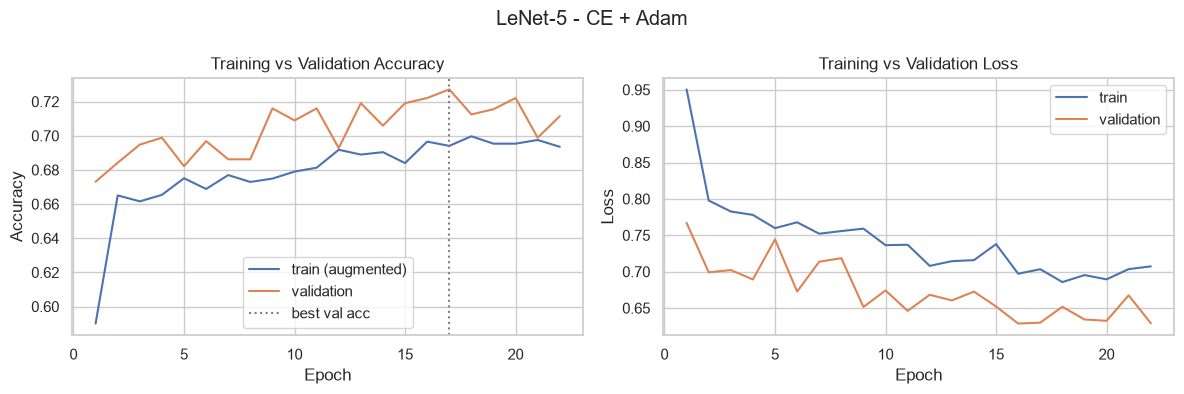

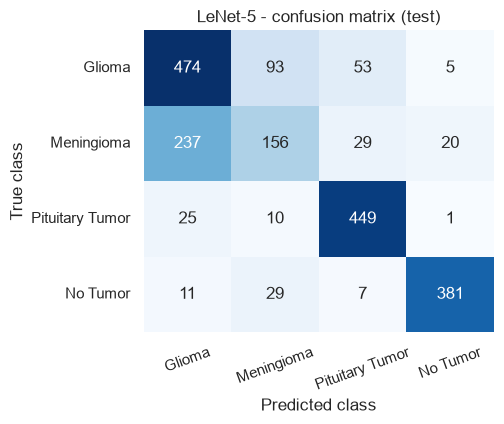

                 precision    recall  f1-score   support

         Glioma       0.63      0.76      0.69       625
     Meningioma       0.54      0.35      0.43       442
Pituitary Tumor       0.83      0.93      0.88       485
       No Tumor       0.94      0.89      0.91       428

       accuracy                           0.74      1980
      macro avg       0.74      0.73      0.73      1980
   weighted avg       0.73      0.74      0.73      1980

AlexNet: test acc 0.8338 | params 5,869,380 | status: completed (full epoch budget)


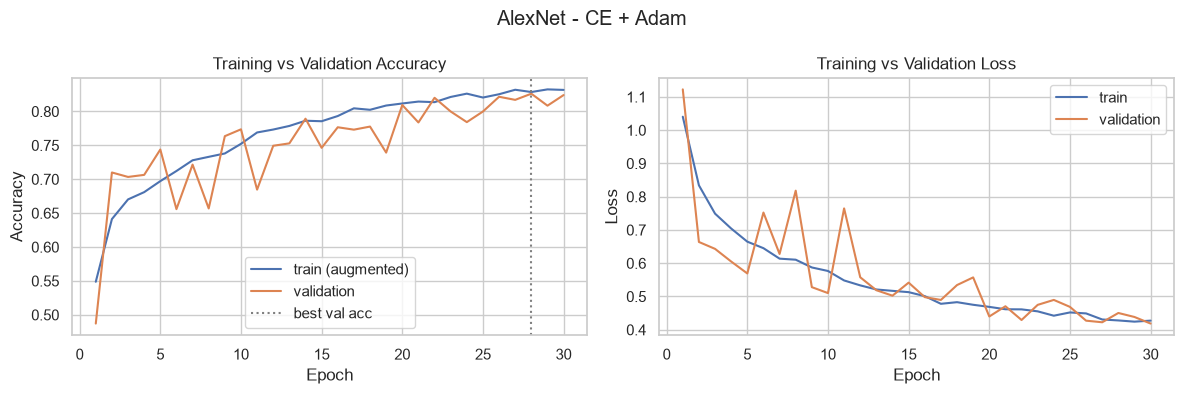

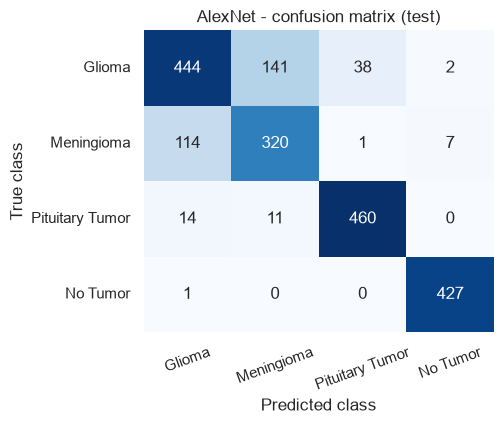

                 precision    recall  f1-score   support

         Glioma       0.77      0.71      0.74       625
     Meningioma       0.68      0.72      0.70       442
Pituitary Tumor       0.92      0.95      0.93       485
       No Tumor       0.98      1.00      0.99       428

       accuracy                           0.83      1980
      macro avg       0.84      0.85      0.84      1980
   weighted avg       0.83      0.83      0.83      1980

VGG: test acc 0.8348 | params 2,833,892 | status: early stopped (patience 6)


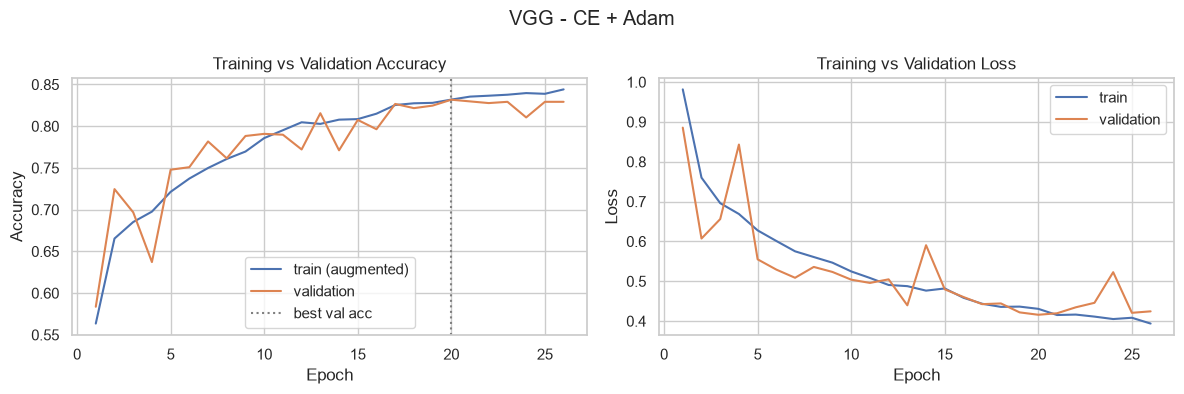

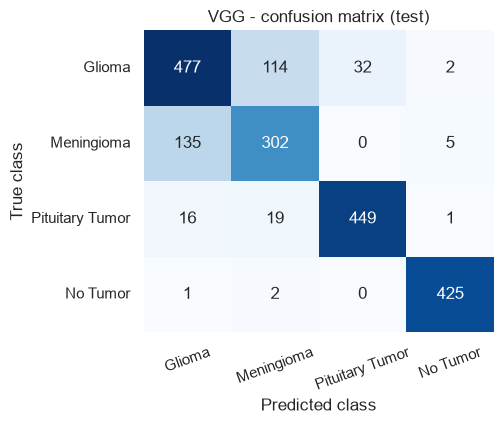

                 precision    recall  f1-score   support

         Glioma       0.76      0.76      0.76       625
     Meningioma       0.69      0.68      0.69       442
Pituitary Tumor       0.93      0.93      0.93       485
       No Tumor       0.98      0.99      0.99       428

       accuracy                           0.83      1980
      macro avg       0.84      0.84      0.84      1980
   weighted avg       0.83      0.83      0.83      1980

GoogLeNet: test acc 0.8328 | params 165,476 | status: early stopped (patience 6)


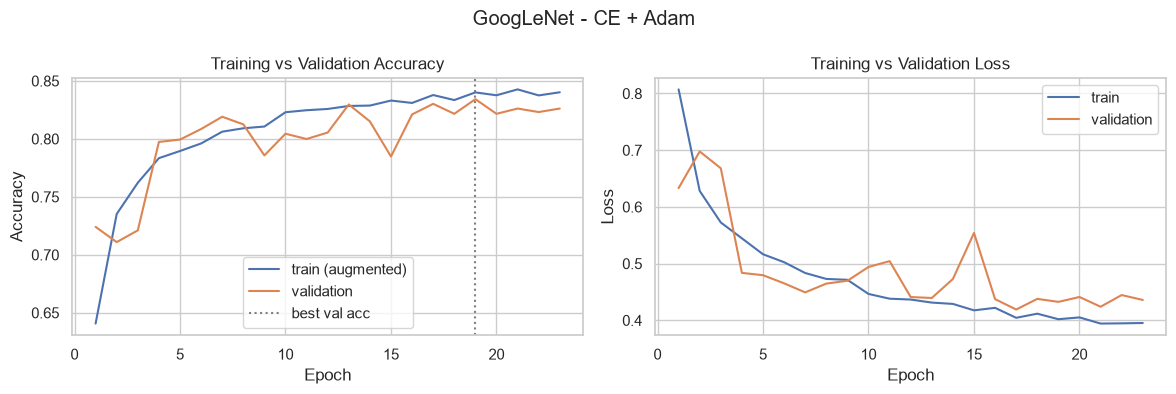

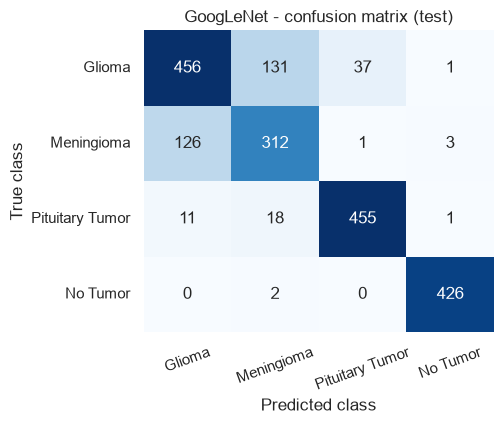

                 precision    recall  f1-score   support

         Glioma       0.77      0.73      0.75       625
     Meningioma       0.67      0.71      0.69       442
Pituitary Tumor       0.92      0.94      0.93       485
       No Tumor       0.99      1.00      0.99       428

       accuracy                           0.83      1980
      macro avg       0.84      0.84      0.84      1980
   weighted avg       0.83      0.83      0.83      1980

ResNet: test acc 0.8359 | params 2,796,772 | status: early stopped (patience 6)


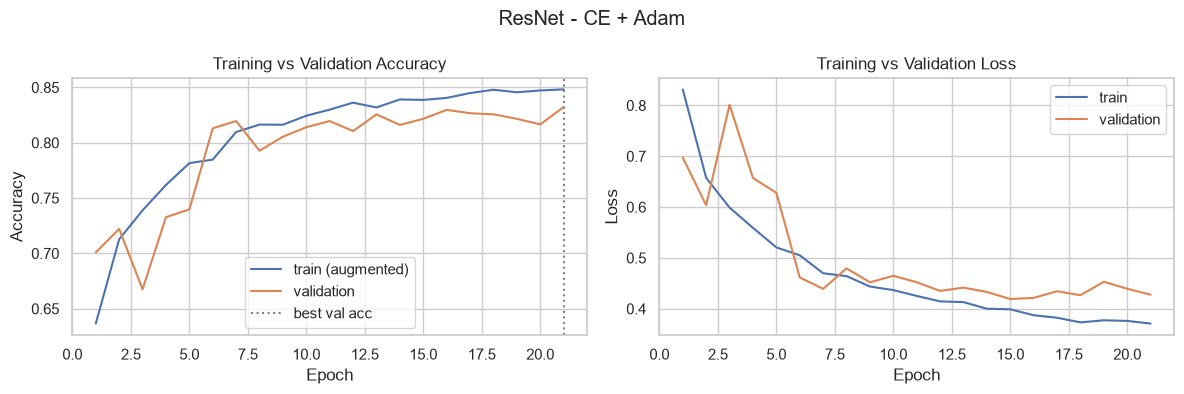

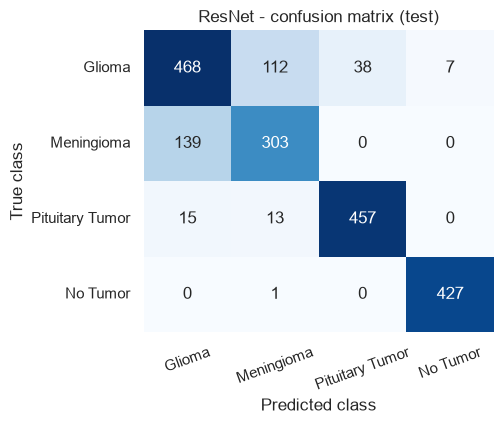

                 precision    recall  f1-score   support

         Glioma       0.75      0.75      0.75       625
     Meningioma       0.71      0.69      0.70       442
Pituitary Tumor       0.92      0.94      0.93       485
       No Tumor       0.98      1.00      0.99       428

       accuracy                           0.84      1980
      macro avg       0.84      0.84      0.84      1980
   weighted avg       0.83      0.84      0.83      1980

EfficientNet: test acc 0.8369 | params 606,276 | status: completed (full epoch budget)


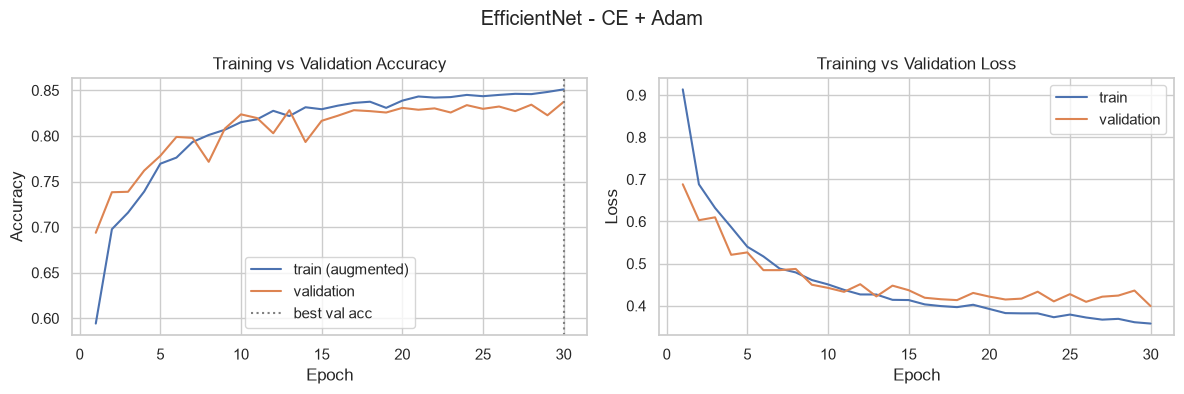

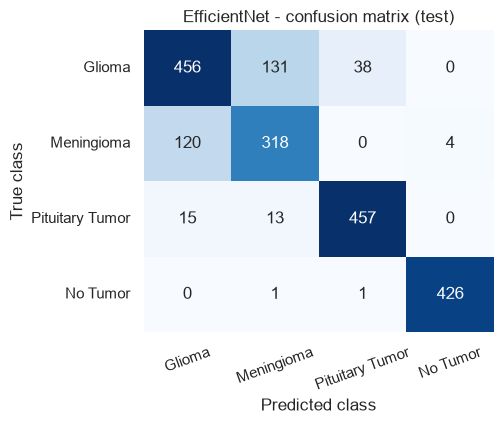

                 precision    recall  f1-score   support

         Glioma       0.77      0.73      0.75       625
     Meningioma       0.69      0.72      0.70       442
Pituitary Tumor       0.92      0.94      0.93       485
       No Tumor       0.99      1.00      0.99       428

       accuracy                           0.84      1980
      macro avg       0.84      0.85      0.84      1980
   weighted avg       0.84      0.84      0.84      1980



In [28]:
for a in ARCHS:
    res = peek(EXP1_SPECS[a])
    if res is None:
        print(f'[{a}] not trained yet'); continue
    print('=' * 80); print(f"{a}: test acc {res['test_acc']:.4f} | params {res['params']:,} | status: {res['status']}")
    plot_curves(res, f'{a} - CE + Adam')
    plot_confusion(res, f'{a} - confusion matrix (test)')
    print(res['report_text'])

,Train Acc,Val Acc,Test Acc,#Params,Train Time (s),Epochs run,Notes (train-val gap)
Architecture,,,,,,,
LeNet-5,0.7418,0.7271,0.7374,"1,627,916",215.400000,22,gap +0.015; early stopped (patience 6)
AlexNet,0.8494,0.8262,0.8338,"5,869,380",332.300000,30,gap +0.023; completed (full epoch budget)
VGG,0.8566,0.8317,0.8348,"2,833,892",446.700000,26,gap +0.025; early stopped (patience 6)
GoogLeNet,0.8503,0.8343,0.8328,"165,476",311.900000,23,gap +0.016; early stopped (patience 6)
ResNet,0.8618,0.8322,0.8359,"2,796,772",294.500000,21,gap +0.030; early stopped (patience 6)
EfficientNet,0.8638,0.8373,0.8369,"606,276",504.000000,30,gap +0.027; completed (full epoch budget)


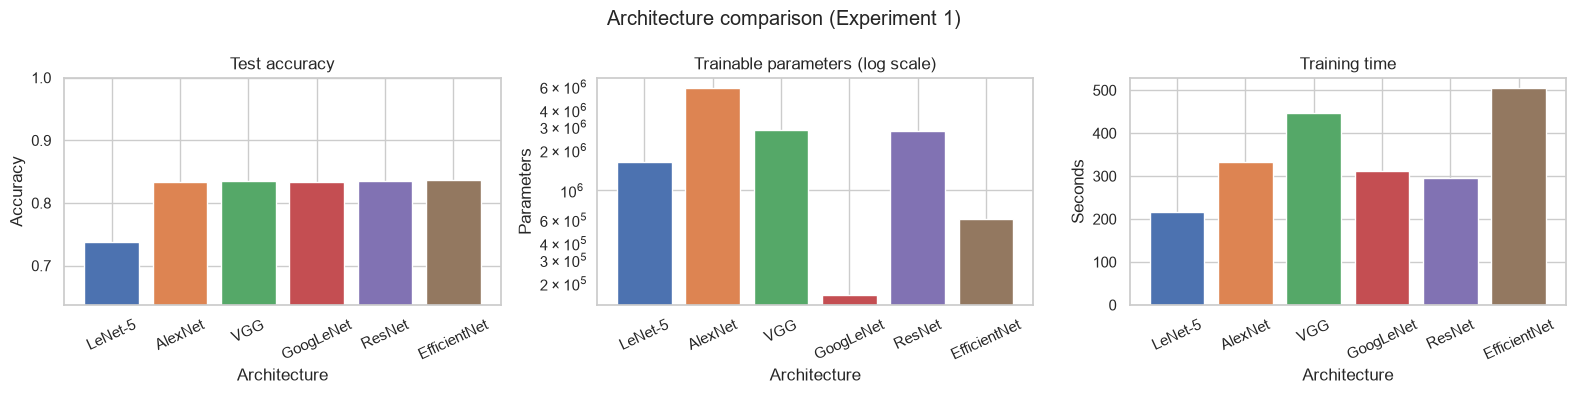

In [29]:
def exp1_table():
    rows = []
    for a in ARCHS:
        r = peek(EXP1_SPECS[a])
        if r is None:
            rows.append({'Architecture': a}); continue
        gap = r['train_acc'] - r['val_acc']
        rows.append({'Architecture': a, 'Train Acc': r['train_acc'], 'Val Acc': r['val_acc'], 'Test Acc': r['test_acc'],
                     '#Params': r['params'], 'Train Time (s)': round(r['train_time'], 1), 'Epochs run': r['epochs_run'],
                     'Notes (train-val gap)': f'gap {gap:+.3f}; {r["status"]}'})
    cols = ['Architecture', 'Train Acc', 'Val Acc', 'Test Acc', '#Params', 'Train Time (s)', 'Epochs run', 'Notes (train-val gap)']
    return pd.DataFrame(rows).reindex(columns=cols).set_index('Architecture')
exp1 = exp1_table()
display(exp1.style.format({'Train Acc': '{:.4f}', 'Val Acc': '{:.4f}', 'Test Acc': '{:.4f}', '#Params': '{:,.0f}'}, na_rep='-'))

if exp1['Test Acc'].notna().any():
    d = exp1.dropna(subset=['Test Acc'])
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].bar(d.index, d['Test Acc'], color=sns.color_palette('deep', len(d))); ax[0].set_title('Test accuracy'); ax[0].set_ylabel('Accuracy'); ax[0].set_ylim(max(0, d['Test Acc'].min() - 0.1), 1.0)
    ax[1].bar(d.index, d['#Params'], color=sns.color_palette('deep', len(d))); ax[1].set_yscale('log'); ax[1].set_title('Trainable parameters (log scale)'); ax[1].set_ylabel('Parameters')
    ax[2].bar(d.index, d['Train Time (s)'], color=sns.color_palette('deep', len(d))); ax[2].set_title('Training time'); ax[2].set_ylabel('Seconds')
    for a_ in ax: a_.set_xlabel('Architecture'); plt.setp(a_.get_xticklabels(), rotation=25)
    fig.suptitle('Architecture comparison (Experiment 1)'); fig.tight_layout(); savefig(fig, 'fig_architecture_comparison.png'); plt.show()

## 5.9 Question
Which architecture achieved the best test accuracy, and which was the most computationally efficient (shortest training time or smallest parameter count)? Were they the same architecture? Relate the differences you observed to specific structural features (depth, residual connections, inception modules, global average pooling, parameter sharing).

### Answer

**Best test accuracy: EfficientNet (0.8369).** But the top five are almost tied: AlexNet 0.8338, VGG 0.8348, GoogLeNet 0.8328, ResNet 0.8359 and EfficientNet 0.8369. They are only 0.41 percentage points apart, which is smaller than the noise of a 1,980-image test set (about 0.8 points). So I cannot say EfficientNet is clearly better. LeNet-5 is clearly the lowest (0.7374).

**Most efficient:** GoogLeNet has the fewest parameters (165,476) and LeNet-5 has the shortest training time (215.4 s, although it also stopped early at epoch 22). So the best model and the most efficient model are **not the same architecture**. LeNet-5 is fast but weaker, so cheap does not mean good.

How the structure explains this:

- **LeNet-5:** only 2 conv layers, so it is fast, but it is too simple for MRI details (Meningioma recall only 0.35). About 1.61M of its 1.63M parameters are in the first fully connected layer (13,456 inputs x 120).
- **AlexNet:** the biggest model (5.87M parameters), with about 3.4M in its two large FC layers. All those parameters did not make it better than the others (0.8338).
- **VGG:** stacks of $3\times3$ convs; 2.83M parameters and 0.8348, and one of the slowest (446.7 s) because it has many conv layers at high resolution.
- **GoogLeNet:** inception modules use $1\times1$ convs to cut channels, and global average pooling replaces big FC layers (its classifier has only 900 weights). That is how it gets 0.8328 with only 165k parameters.
- **ResNet:** skip connections make a deeper network easy to train; 0.8359 in 294.5 s.
- **EfficientNet:** depthwise convs and squeeze-and-excitation gave the top accuracy with 606,276 parameters (about a tenth of AlexNet). It was the slowest to train (504.0 s), probably because it has many small layers (51 conv layers) and used all 30 epochs, so fewer parameters does not automatically mean faster training.

---
# 6. Loss Function Comparison (Experiment 2)

Every architecture is trained again with each of the four losses. Everything else (splits, preprocessing, Adam lr 1e-3, batch size, epochs, patience, seed) is held constant. The CE column is the same run as Experiment 1. Mean Squared Error on softmax outputs is not part of this comparison.

**Loss settings used:** label smoothing $\varepsilon=0.1$; focal $\gamma=2$ with $\alpha_c = N/(K n_c)$; weighted CE $w_c = N/(K n_c)$. The weights are Glioma 0.7917, Meningioma 1.1194, Pituitary Tumor 1.0209 and No Tumor 1.1575 (computed from the training counts 2,917 / 2,063 / 2,262 / 1,995; the printed values are in Section 5.4).

In [30]:
LOSS_GRID = {(a, l): make_spec(a, l, BASE_OPT_NAME) for a in ARCHS for l in LOSS_NAMES}
if RUN_FLAGS['loss']:
    run_grid(list(LOSS_GRID.values()))
done = sum(peek(s) is not None for s in LOSS_GRID.values()); print('Finished loss-comparison runs:', done, '/', len(LOSS_GRID))

--- run 1/24
[cached] LeNet-5|CE|Adam (f191597105)
--- run 2/24
[train ] LeNet-5|LS|Adam (5593144ea1)
  epoch   1/30 | train loss 1.0457 acc 0.5885 | val loss 0.8893 acc 0.6710 | 10.7s
  epoch   2/30 | train loss 0.9269 acc 0.6676 | val loss 0.8677 acc 0.6933 | 10.1s
  epoch   3/30 | train loss 0.9073 acc 0.6742 | val loss 0.8495 acc 0.7024 | 10.0s
  epoch   4/30 | train loss 0.9012 acc 0.6799 | val loss 0.8343 acc 0.7094 | 10.1s
  epoch   5/30 | train loss 0.8866 acc 0.6860 | val loss 0.8455 acc 0.7145 | 10.3s
  epoch   6/30 | train loss 0.8862 acc 0.6821 | val loss 0.8294 acc 0.7150 | 10.0s
  epoch   7/30 | train loss 0.8782 acc 0.6926 | val loss 0.8256 acc 0.7160 | 10.0s
  epoch   8/30 | train loss 0.8712 acc 0.6921 | val loss 0.8278 acc 0.7100 | 9.8s
  epoch   9/30 | train loss 0.8700 acc 0.6920 | val loss 0.8072 acc 0.7226 | 9.8s
  epoch  10/30 | train loss 0.8674 acc 0.6931 | val loss 0.8765 acc 0.6988 | 10.1s
  epoch  11/30 | train loss 0.8645 acc 0.6959 | val loss 0.8638 acc 0.

TEST ACCURACY


,Cross-Entropy,Label Smoothing,Focal Loss,Weighted CE
LeNet-5,0.7374,0.7343,0.7242,0.7409
AlexNet,0.8338,0.8369,0.7455,0.8217
VGG,0.8348,0.8389,0.8177,0.8364
GoogLeNet,0.8328,0.8359,0.8222,0.8157
ResNet,0.8359,0.8222,0.8283,0.8364
EfficientNet,0.8369,0.8323,0.8288,0.8288


EPOCHS TO BEST VALIDATION ACCURACY (convergence speed)


,Cross-Entropy,Label Smoothing,Focal Loss,Weighted CE
LeNet-5,17,13,14,12
AlexNet,28,30,13,26
VGG,20,28,23,21
GoogLeNet,19,17,13,7
ResNet,21,7,16,13
EfficientNet,30,13,30,21


TRAIN ACC - VAL ACC (positive = overfitting tendency)


,Cross-Entropy,Label Smoothing,Focal Loss,Weighted CE
LeNet-5,+0.0147,+0.0165,+0.0182,+0.0130
AlexNet,+0.0232,+0.0258,-0.0028,+0.0255
VGG,+0.0248,+0.0282,+0.0181,+0.0310
GoogLeNet,+0.0160,+0.0230,+0.0170,+0.0198
ResNet,+0.0295,+0.0221,+0.0266,+0.0258
EfficientNet,+0.0265,+0.0247,+0.0293,+0.0231


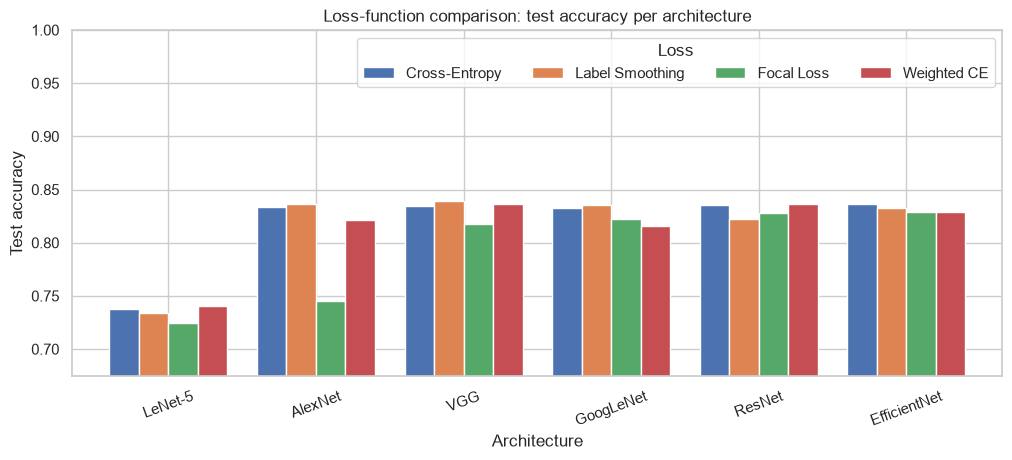

In [31]:
loss_acc = table_from(LOSS_GRID, ARCHS, list(LOSS_NAMES), 'test_acc')
loss_acc.columns = list(LOSS_NAMES.values())
print('TEST ACCURACY'); display(loss_acc.style.format('{:.4f}', na_rep='-'))

conv_speed = table_from(LOSS_GRID, ARCHS, list(LOSS_NAMES), 'epochs_to_best_val_acc'); conv_speed.columns = list(LOSS_NAMES.values())
print('EPOCHS TO BEST VALIDATION ACCURACY (convergence speed)'); display(conv_speed.style.format('{:.0f}', na_rep='-'))

gap = table_from(LOSS_GRID, ARCHS, list(LOSS_NAMES), lambda r: r['train_acc'] - r['val_acc']); gap.columns = list(LOSS_NAMES.values())
print('TRAIN ACC - VAL ACC (positive = overfitting tendency)'); display(gap.style.format('{:+.4f}', na_rep='-'))

if loss_acc.notna().any().any():
    ax = loss_acc.plot(kind='bar', figsize=(12, 4.5), width=0.8)
    ax.set_title('Loss-function comparison: test accuracy per architecture'); ax.set_xlabel('Architecture'); ax.set_ylabel('Test accuracy')
    ax.set_ylim(max(0, np.nanmin(loss_acc.values) - 0.05), 1.0); plt.xticks(rotation=20); ax.legend(title='Loss', ncol=4)
    savefig(ax.figure, 'fig_loss_comparison.png'); plt.show()

Per-class precision (P) / recall (R) on the test set - ResNet


,Glioma P,Glioma R,Meningioma P,Meningioma R,Pituitary Tumor P,Pituitary Tumor R,No Tumor P,No Tumor R
Loss,,,,,,,,
Cross-Entropy,0.752,0.749,0.706,0.686,0.923,0.942,0.984,0.998
Label Smoothing,0.736,0.754,0.684,0.613,0.900,0.946,0.984,0.998
Focal Loss,0.736,0.752,0.684,0.665,0.930,0.926,0.998,0.998
Weighted CE,0.753,0.752,0.692,0.681,0.928,0.951,1.000,0.991


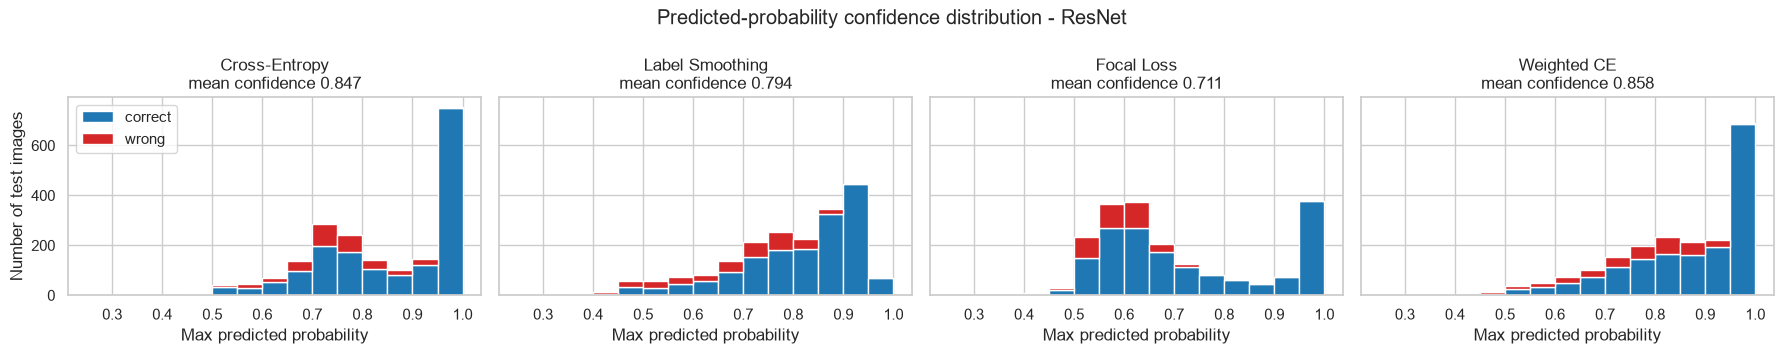

In [32]:
LOSS_FOCUS_ARCH = ARCHS[min(4, len(ARCHS) - 1)]
rows = []
for l, lname in LOSS_NAMES.items():
    r = peek(LOSS_GRID[(LOSS_FOCUS_ARCH, l)])
    if r is None: continue
    row = {'Loss': lname}
    for c in CLASS_KEYS:
        rep = r['report'][CLASS_TITLES[c]]
        row[f'{CLASS_TITLES[c]} P'], row[f'{CLASS_TITLES[c]} R'] = rep['precision'], rep['recall']
    rows.append(row)
if rows:
    print(f'Per-class precision (P) / recall (R) on the test set - {LOSS_FOCUS_ARCH}')
    display(pd.DataFrame(rows).set_index('Loss').style.format('{:.3f}'))

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for ax, (l, lname) in zip(axes, LOSS_NAMES.items()):
    r = peek(LOSS_GRID[(LOSS_FOCUS_ARCH, l)])
    if r is None:
        ax.set_title(f'{lname}\n(not run)'); continue
    conf, ok = np.array(r['conf_max']), np.array(r['conf_correct']).astype(bool)
    ax.hist([conf[ok], conf[~ok]], bins=np.linspace(0.25, 1.0, 16), stacked=True, label=['correct', 'wrong'], color=['tab:blue', 'tab:red'])
    ax.set_title(f'{lname}\nmean confidence {conf.mean():.3f}'); ax.set_xlabel('Max predicted probability')
axes[0].set_ylabel('Number of test images'); axes[0].legend()
fig.suptitle(f'Predicted-probability confidence distribution - {LOSS_FOCUS_ARCH}'); fig.tight_layout()
savefig(fig, 'fig_loss_confidence.png'); plt.show()

## 6.1 Questions
**(a)** Write the gradient of cross-entropy loss with respect to the logits and compare it, conceptually, to the gradient of focal loss. How does focal loss's modulating term change the relative weight given to easy versus hard (frequently misclassified) examples?

**(b)** Given the class distribution you found in Reflection Question 1, explain whether label smoothing, focal loss, or class-weighted cross-entropy would be the most principled choice for reducing the model's bias toward the majority class, and support your answer with your results.

### Answer

**(a)** For softmax probabilities $p_j$ and true class $y$, the cross-entropy gradient with respect to the logits is

$$\frac{\partial L_{CE}}{\partial z_j} = p_j - \mathbf{1}[j=y]$$

so the true class is pushed up (by $1-p_y$) and the other classes are pushed down (by $p_j$). For focal loss $L=-\alpha_y(1-p_y)^{\gamma}\ln p_y$, the gradient is the same direction multiplied by an extra factor:

$$\frac{\partial L_{F}}{\partial z_j} = \alpha_y\,(1-p_y)^{\gamma-1}\big[(1-p_y)-\gamma\,p_y\ln p_y\big]\,\big(p_j-\mathbf{1}[j=y]\big)$$

With $\gamma=2$ (ignoring $\alpha_y$), an easy example with $p_y=0.9$ gets a factor of only about 0.03, while a hard example with $p_y=0.2$ gets about 1.16. So focal loss almost ignores easy examples and puts most of the learning pressure on hard, often-misclassified ones. Plain CE does not make that difference.

**(b)** The most principled choice for the class imbalance is **class-weighted CE**, because it directly gives the smaller classes a bigger weight (weights from 0.7917 for Glioma to 1.1575 for No Tumor). Label smoothing is not meant for imbalance (it only makes the model less overconfident), and focal loss targets hard examples, not rare classes (here it uses the same $\alpha$ weights as weighted CE).

But my results did not show a clear benefit. Weighted CE was slightly better than CE for LeNet-5 (0.7409 vs 0.7374), VGG (0.8364 vs 0.8348) and ResNet (0.8364 vs 0.8359), and worse for AlexNet (0.8217 vs 0.8338), GoogLeNet (0.8157 vs 0.8328) and EfficientNet (0.8288 vs 0.8369). For ResNet, Meningioma recall was 0.686 with CE, 0.681 with weighted CE, 0.665 with focal and 0.613 with label smoothing, and Glioma recall stayed at about 0.75 for all four losses. Focal loss gave lower accuracy than CE for all six architectures (for example AlexNet 0.8338 down to 0.7455). Label smoothing was a little higher than CE for AlexNet, VGG and GoogLeNet. So in these runs no loss clearly reduced the bias toward Glioma. This may be because the imbalance is mild (only 1.46 : 1) and Meningioma and Glioma were just the hardest classes (recall about 0.7 for both).

---
# 7. Optimizer Comparison (Experiment 3)

Every architecture is trained with each optimizer. **Only the optimizer (and its own hyperparameters) changes**; loss = cross-entropy; batch size, seed, epoch budget and early-stopping rule are the same for all 30 runs.

| Optimizer | Settings |
|---|---|
| SGD | momentum 0.9, Nesterov, lr 0.01 |
| RMSprop | lr 0.001 |
| Adam | lr 0.001 |
| AdamW | lr 0.001, weight decay 0.01 |
| Nadam | lr 0.001 (`torch.optim.NAdam`) |

The Adam column is the same run as Experiment 1 and the CE column of Experiment 2. PyTorch's default `RMSprop` constants (`alpha=0.99`, `eps=1e-8`) differ from Keras (`rho=0.9`, `eps=1e-7`).

In [33]:
OPT_GRID = {(a, o): make_spec(a, 'CE', o) for a in ARCHS for o in OPT_SPECS}
if RUN_FLAGS['optim']:
    run_grid(list(OPT_GRID.values()))
print('Finished optimizer runs:', sum(peek(s) is not None for s in OPT_GRID.values()), '/', len(OPT_GRID))

--- run 1/30
[train ] LeNet-5|CE|SGD (4287e7a3e6)
  epoch   1/30 | train loss 0.9293 acc 0.5962 | val loss 0.7577 acc 0.6640 | 10.2s
  epoch   2/30 | train loss 0.7741 acc 0.6702 | val loss 0.6999 acc 0.6943 | 9.9s
  epoch   3/30 | train loss 0.7233 acc 0.6868 | val loss 0.6459 acc 0.7165 | 9.8s
  epoch   4/30 | train loss 0.6825 acc 0.7015 | val loss 0.6125 acc 0.7271 | 9.6s
  epoch   5/30 | train loss 0.6461 acc 0.7252 | val loss 0.5990 acc 0.7337 | 10.1s
  epoch   6/30 | train loss 0.6397 acc 0.7234 | val loss 0.6006 acc 0.7322 | 9.3s
  epoch   7/30 | train loss 0.6137 acc 0.7340 | val loss 0.5761 acc 0.7428 | 9.3s
  epoch   8/30 | train loss 0.5978 acc 0.7403 | val loss 0.5827 acc 0.7276 | 9.3s
  epoch   9/30 | train loss 0.5875 acc 0.7448 | val loss 0.5553 acc 0.7671 | 9.4s
  epoch  10/30 | train loss 0.5820 acc 0.7433 | val loss 0.5488 acc 0.7660 | 9.7s
  epoch  11/30 | train loss 0.5727 acc 0.7428 | val loss 0.5255 acc 0.7772 | 9.9s
  epoch  12/30 | train loss 0.5581 acc 0.7563 

TEST ACCURACY (required table)


,SGD (Nesterov),RMSprop,Adam,AdamW,Nadam
LeNet-5,0.7879,0.7510,0.7374,0.7389,0.7394
AlexNet,0.8318,0.7960,0.8338,0.8338,0.8399
VGG,0.8424,0.8313,0.8348,0.8414,0.8369
GoogLeNet,0.8399,0.8318,0.8328,0.8273,0.8354
ResNet,0.8232,0.8399,0.8359,0.8182,0.8399
EfficientNet,0.8242,0.8308,0.8369,0.8313,0.8283


EPOCHS TO BEST VALIDATION ACCURACY


,SGD (Nesterov),RMSprop,Adam,AdamW,Nadam
LeNet-5,17,30,17,9,7
AlexNet,23,18,28,28,30
VGG,24,17,20,23,23
GoogLeNet,23,18,19,13,17
ResNet,18,15,21,13,18
EfficientNet,19,18,30,30,19


TRAINING TIME (s)


,SGD (Nesterov),RMSprop,Adam,AdamW,Nadam
LeNet-5,224,296,215,147,131
AlexNet,309,192,332,327,326
VGG,495,380,447,416,2797
GoogLeNet,400,296,312,232,271
ResNet,306,307,294,239,310
EfficientNet,454,302,504,500,316


RUN STATUS (completed / early stopped / diverged)


,SGD (Nesterov),RMSprop,Adam,AdamW,Nadam
LeNet-5,early stopped (patience 6),completed (full epoch budget),early stopped (patience 6),early stopped (patience 6),early stopped (patience 6)
AlexNet,early stopped (patience 6),early stopped (patience 6),completed (full epoch budget),completed (full epoch budget),completed (full epoch budget)
VGG,completed (full epoch budget),early stopped (patience 6),early stopped (patience 6),early stopped (patience 6),completed (full epoch budget)
GoogLeNet,early stopped (patience 6),early stopped (patience 6),early stopped (patience 6),early stopped (patience 6),early stopped (patience 6)
ResNet,early stopped (patience 6),early stopped (patience 6),early stopped (patience 6),early stopped (patience 6),early stopped (patience 6)
EfficientNet,early stopped (patience 6),early stopped (patience 6),completed (full epoch budget),completed (full epoch budget),early stopped (patience 6)


VAL-LOSS OSCILLATION (mean |change| over the last 5 epochs; larger = noisier)


,SGD (Nesterov),RMSprop,Adam,AdamW,Nadam
LeNet-5,0.0177,0.0054,0.0232,0.0236,0.0190
AlexNet,0.0303,0.0943,0.0161,0.0154,0.0188
VGG,0.0256,0.1044,0.0485,0.0397,0.0158
GoogLeNet,0.0335,0.1543,0.0138,0.0118,0.0250
ResNet,0.0129,0.0436,0.0150,0.0177,0.0264
EfficientNet,0.0100,0.0105,0.0159,0.0067,0.0066


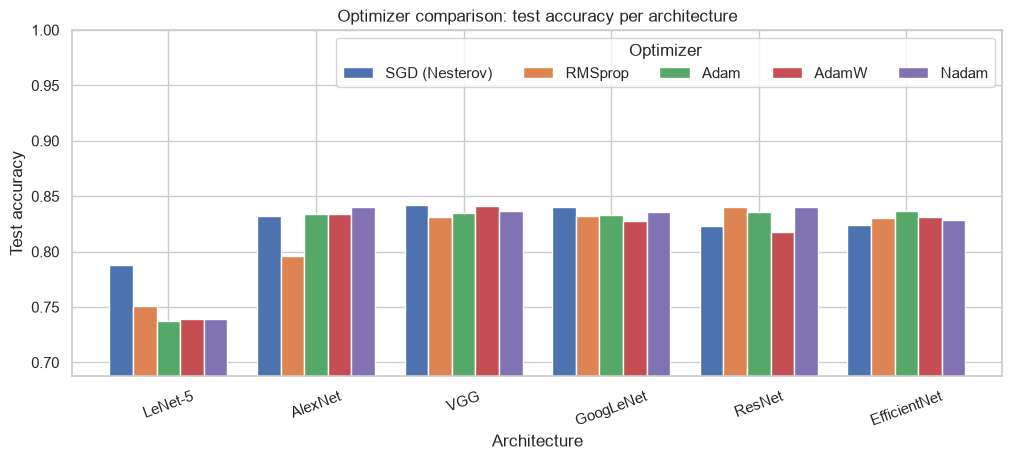

In [34]:
ocols = list(OPT_SPECS)
opt_acc = table_from(OPT_GRID, ARCHS, ocols, 'test_acc'); opt_acc.columns = [OPT_LABELS[o] for o in ocols]
opt_ep = table_from(OPT_GRID, ARCHS, ocols, 'epochs_to_best_val_acc'); opt_ep.columns = opt_acc.columns
opt_time = table_from(OPT_GRID, ARCHS, ocols, lambda r: r['train_time']); opt_time.columns = opt_acc.columns
opt_status = table_from(OPT_GRID, ARCHS, ocols, 'status'); opt_status.columns = opt_acc.columns
opt_osc = table_from(OPT_GRID, ARCHS, ocols, 'val_loss_oscillation'); opt_osc.columns = opt_acc.columns

print('TEST ACCURACY (required table)'); display(opt_acc.style.format('{:.4f}', na_rep='-'))
print('EPOCHS TO BEST VALIDATION ACCURACY'); display(opt_ep.style.format('{:.0f}', na_rep='-'))
print('TRAINING TIME (s)'); display(opt_time.style.format('{:.0f}', na_rep='-'))
print('RUN STATUS (completed / early stopped / diverged)'); display(opt_status)
print('VAL-LOSS OSCILLATION (mean |change| over the last 5 epochs; larger = noisier)'); display(opt_osc.style.format('{:.4f}', na_rep='-'))

opt_acc.to_csv('table_optimizer_test_acc.csv'); opt_ep.to_csv('table_optimizer_epochs.csv'); opt_time.to_csv('table_optimizer_time.csv')
if opt_acc.notna().any().any():
    ax = opt_acc.plot(kind='bar', figsize=(12, 4.5), width=0.8)
    ax.set_title('Optimizer comparison: test accuracy per architecture'); ax.set_xlabel('Architecture'); ax.set_ylabel('Test accuracy')
    ax.set_ylim(max(0, np.nanmin(opt_acc.values) - 0.05), 1.0); plt.xticks(rotation=20); ax.legend(title='Optimizer', ncol=5)
    savefig(ax.figure, 'fig_optimizer_comparison.png'); plt.show()

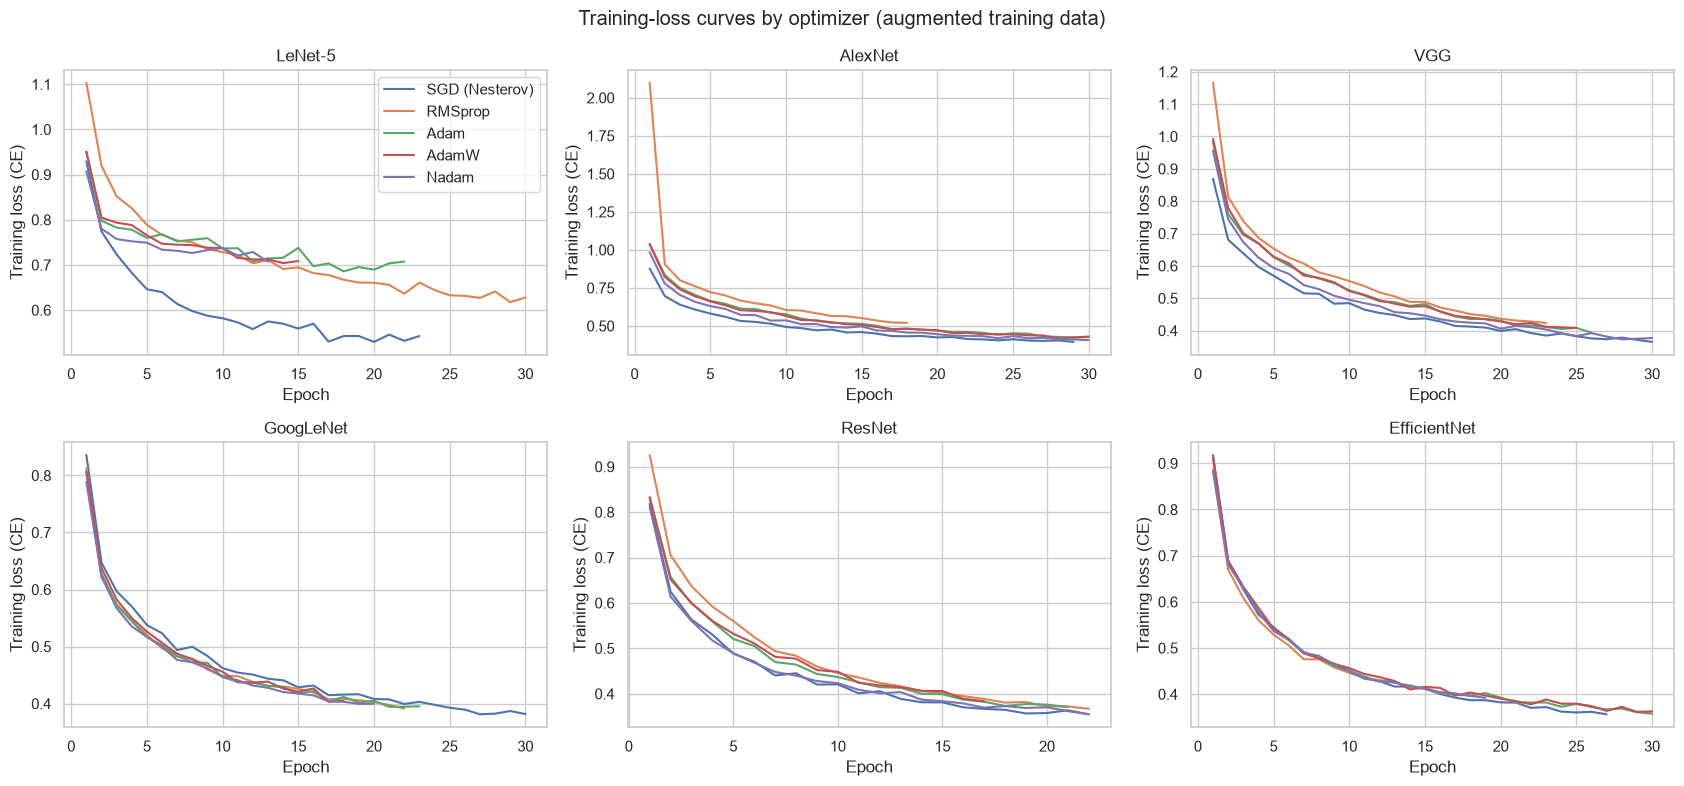

In [35]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8)); axes = axes.ravel()
for ax, a in zip(axes, ARCHS):
    for o in OPT_SPECS:
        r = peek(OPT_GRID[(a, o)])
        if r is not None:
            ax.plot(np.arange(1, len(r['history']['train_loss']) + 1), r['history']['train_loss'], label=OPT_LABELS[o])
    ax.set_title(a); ax.set_xlabel('Epoch'); ax.set_ylabel('Training loss (CE)')
axes[0].legend()
fig.suptitle('Training-loss curves by optimizer (augmented training data)'); fig.tight_layout()
savefig(fig, 'fig_optimizer_loss_curves.png'); plt.show()

## 7.1 Questions
**(a)** Across all six architectures, which optimizer most consistently achieved the highest test accuracy? Was any optimizer's ranking architecture-dependent? Cite specific rows from your table.

**(b)** SGD with Nesterov momentum typically needs more epochs to reach its best validation accuracy than the Adam-family optimizers, but can generalize at least as well on vision tasks once it converges. Did your results show this pattern? Support your answer with the epochs-to-convergence and test-accuracy values you logged.

**(c)** AdamW decouples weight decay from the gradient-based update, unlike Adam with L2 regularization folded directly into the gradient. For which architecture(s) in your table (if any) did this distinction appear to matter most? Explain why a deeper, more over-parameterized architecture (e.g. VGG or ResNet) would be more sensitive to this distinction than a shallow one (e.g. LeNet-5).

### Answer

**(a)** No optimizer won for every architecture. The best optimizer per row:

| Architecture | Best optimizer (test acc) |
|---|---|
| LeNet-5 | SGD (0.7879) |
| AlexNet | Nadam (0.8399) |
| VGG | SGD (0.8424) |
| GoogLeNet | SGD (0.8399) |
| ResNet | RMSprop and Nadam tied (0.8399) |
| EfficientNet | Adam (0.8369) |

SGD won the most rows (3 of 6) but was not consistent: it was the lowest in the EfficientNet row (0.8242) and second lowest for ResNet (0.8232). RMSprop was tied-best for ResNet (0.8399) but lowest for AlexNet (0.7960). So the ranking depends on the architecture. For the five bigger models most gaps are only about 1 to 2 points, which is close to the noise level.

**(b)** Only partly. Epochs to best validation accuracy, SGD vs Adam: LeNet-5 17 vs 17, AlexNet 23 vs 28, VGG 24 vs 20, GoogLeNet 23 vs 19, ResNet 18 vs 21, EfficientNet 19 vs 30. SGD was slower only for VGG and GoogLeNet, and faster for AlexNet, ResNet and EfficientNet. For test accuracy, SGD was higher than Adam for LeNet-5 (+0.0505), VGG (+0.0076) and GoogLeNet (+0.0071), but lower for AlexNet (-0.0020), ResNet (-0.0127) and EfficientNet (-0.0127). So the "SGD is slower but generalizes at least as well" pattern did not show up consistently. (The epoch numbers are also limited by the 30-epoch cap and early stopping.) Note that VGG + Nadam took 2,797 s, far above every other run (131 s to 504 s), probably because the computer slowed down or slept, so I do not use that time to compare speed.

**(c)** Here "Adam" has no weight decay at all, while AdamW has decoupled weight decay 0.01, so this compares no decay against decay. The biggest change was for ResNet: 0.8359 with Adam and 0.8182 with AdamW (-0.0177). The next biggest was VGG, which went up from 0.8348 to 0.8414 (+0.0066). LeNet-5 barely moved (0.7374 vs 0.7389) and AlexNet did not change (0.8338 for both).

In theory, a deeper network with many layers and weights can overfit more, and weight decay keeps the weights small at every step, so it should matter more. A shallow network like LeNet-5 has less to regularize. My results fit this only loosely: AdamW helped VGG but hurt ResNet, so the effect depends on the architecture, and with one seed I cannot call it a general rule.

---
# 8. Kernel Size Experiment (Experiment 4)

Sections 8-12 use a **small configurable CNN (`FlexCNN`)** as the base architecture. Every setting (kernel, stride, padding, pooling, head) is a constructor argument or config entry.

```
input (1 x S x S) -> [Conv(k, stride, pad) -> BN -> ReLU -> Pool] x 3 (16, 32, 64 channels) -> head -> 4 logits
```

**Setup choices:**

1. *Kernel size* and *stride* are changed on the **first** convolution only; the other two convs stay $3\times3$, stride 1. Section 12 uses the same rule.
2. *Padding* (valid / same) is applied to **all three** convolutions. "Same" = $P=\lfloor (k-1)/2\rfloor$, which keeps the size for stride 1 and gives $\lceil n/S\rceil$ for stride $S$ with odd kernels.
3. *Pooling* = $2\times2$, stride 2 after each conv block (or none / strided-conv replacement where stated).
4. *Head* = global average pooling + one linear layer for Sections 8, 9, 10 and 12. In Section 11 the head is also varied (flatten + 2 FC layers vs GAP).

## 8.1 The configurable network

In [58]:
def resolve_pad(pad, k):
    return 0 if pad == 'valid' else (k - 1) // 2 if pad == 'same' else int(pad)

class FlexCNN(StagedNet):
    """Configurable small CNN. `kernel`/`stride` apply to the FIRST conv, `padding` to all convs, `pool` after every block."""
    def __init__(self, in_ch=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE, channels=(16, 32, 64), kernel=3, stride=1,
                 padding='same', other_kernel=3, pool='max', pool_k=2, pool_s=2, head='gap', hidden=64, dropout=0.3):
        stages, specs, c = [], [], in_ch
        for i, w in enumerate(channels):
            k, s = (kernel, stride) if i == 0 else (other_kernel, 1)
            p = resolve_pad(padding, k)
            layers = [conv_bn_act(c, w, k, s, p)]
            specs.append(dict(name=f'conv{i+1}', type='conv', k=k, s=s, p=p))
            if pool == 'max':
                layers.append(nn.MaxPool2d(pool_k, pool_s)); specs.append(dict(name=f'pool{i+1}', type='pool', k=pool_k, s=pool_s, p=0))
            elif pool == 'avg':
                layers.append(nn.AvgPool2d(pool_k, pool_s)); specs.append(dict(name=f'pool{i+1}', type='pool', k=pool_k, s=pool_s, p=0))
            elif pool == 'stridedconv':
                layers.append(conv_bn_act(w, w, 3, s=2, p=1)); specs.append(dict(name=f'down{i+1}', type='conv', k=3, s=2, p=1))
            elif pool != 'none':
                raise ValueError(pool)
            stages.append((f'block{i+1}', nn.Sequential(*layers))); c = w
        feat = nn.Sequential(OrderedDict(stages))
        if head == 'gap':
            tail = [('gap', nn.AdaptiveAvgPool2d(1)), ('flatten', nn.Flatten()), ('out', nn.Sequential(nn.Dropout(dropout), nn.Linear(c, num_classes)))]
            flat = c
        elif head == 'flatten':
            flat = infer_flat_dim(feat, in_ch, img_size)
            tail = [('flatten', nn.Flatten()), ('fc', nn.Sequential(nn.Linear(flat, hidden), nn.ReLU(inplace=True), nn.Dropout(dropout))),
                    ('out', nn.Linear(hidden, num_classes))]
        else:
            raise ValueError(head)
        super().__init__(stages + tail)
        self.layer_specs, self.img_size, self.flat_dim, self.head_type = specs, img_size, flat, head

    def dims_by_formula(self, size=None):
        n, out = size or self.img_size, []
        for sp in self.layer_specs:
            n = conv_out_size(n, sp['k'], sp['s'], sp['p']); out.append((sp['name'], n))
        return out
    def dims_by_hooks(self, in_ch=1):
        out, hooks = [], []
        mods = [m for m in self.modules() if isinstance(m, (nn.Conv2d, nn.MaxPool2d, nn.AvgPool2d))]
        for m in mods:
            hooks.append(m.register_forward_hook(lambda mod, i, o: out.append(o.shape[-1])))
        was = self.training; self.eval()
        with torch.no_grad():
            self(torch.zeros(1, in_ch, self.img_size, self.img_size))
        self.train(was)
        for h in hooks: h.remove()
        return out
    def receptive_field(self):
        return receptive_field([(sp['k'], sp['s']) for sp in self.layer_specs])

@torch.no_grad()
def count_conv_macs(model, in_ch=1):
    """Multiply-accumulates of every Conv2d: H_out * W_out * C_out * (C_in/groups) * k * k."""
    recs, hooks = [], []
    for m in model.modules():
        if isinstance(m, nn.Conv2d):
            hooks.append(m.register_forward_hook(lambda mod, i, o: recs.append(
                (o.shape[2] * o.shape[3], o.shape[2] * o.shape[3] * mod.out_channels * (mod.in_channels // mod.groups) * mod.kernel_size[0] * mod.kernel_size[1]))))
    was = model.training; model.eval()
    model(torch.zeros(1, in_ch, IMG_SIZE, IMG_SIZE))
    model.train(was)
    for h in hooks: h.remove()
    return dict(total_macs=int(sum(r[1] for r in recs)), first_macs=int(recs[0][1]), first_positions=int(recs[0][0]))

FLEX_BASE = dict(channels=[16, 32, 64], kernel=3, stride=1, padding='same', pool='max', head='gap')

def flex_cfg(**over):
    return {**FLEX_BASE, **over, 'img_size': IMG_SIZE}

def flex_spec(**over):
    return make_spec(dict(kind='flex', cfg=flex_cfg(**over)), 'CE', BASE_OPT_NAME)

def flex_info(cfg):
    """Everything that can be computed WITHOUT training: dims (formula and PyTorch hooks), params, RF, MACs."""
    m = FlexCNN(**cfg)
    f, h = m.dims_by_formula(), m.dims_by_hooks()
    assert [d for _, d in f] == h, f'formula {f} != PyTorch {h}'
    return dict(dims=f, params=count_params(m), rf=m.receptive_field(), flat=m.flat_dim, **count_conv_macs(m),
                first_conv_params=sum(p.numel() for p in m.stages.block1[0][0].parameters()))

def load_trained(spec):
    m = build_from_spec(spec['model']).to(DEVICE)
    m.load_state_dict(torch.load(os.path.join(CKPT_DIR, run_id_of(spec) + '.pt'), map_location=DEVICE)); m.eval()
    return m

def rep_input(cls):
    x = IMAGES[REP[cls]['index']].float() / 255.0
    return ((x - MEAN) / STD)[None].to(DEVICE)

@torch.no_grad()
def capture(model, module, x):
    """Output of one sub-module (forward hook) for input x."""
    box = []
    h = module.register_forward_hook(lambda m, i, o: box.append(o.detach().cpu()))
    model.eval(); model(x); h.remove()
    return box[0]

def fmt_res(r, key, f='{:.4f}'):
    return np.nan if r is None else r[key]

base_info = flex_info(flex_cfg())
print('FlexCNN base: dims after each conv/pool layer =', base_info['dims'])
print('Params:', f"{base_info['params']:,}", '| receptive field of the last pooled unit:', base_info['rf'], '| conv MACs:', f"{base_info['total_macs']:,}")

FlexCNN base: dims after each conv/pool layer = [('conv1', 128), ('pool1', 64), ('conv2', 64), ('pool2', 32), ('conv3', 32), ('pool3', 16)]
Params: 23,668 | receptive field of the last pooled unit: 22 | conv MACs: 40,108,032


## 8.2 Kernel-size runs ($1\times1$, $3\times3$, $5\times5$, $7\times7$ in the first layer)

,"Output dims (conv1, same pad)",Output dims if valid pad,RF (conv1 / whole net),First-conv params,#Params (total),Train time (s),Epochs run,Test Acc
Kernel,,,,,,,,
1x1,128x128,128x128,1 / 20,16,"23,540",249.600000,23,0.6980
3x3,128x128,126x126,3 / 22,144,"23,668",162.100000,15,0.7096
5x5,128x128,124x124,5 / 24,400,"23,924",239.200000,22,0.7298
7x7,128x128,122x122,7 / 26,784,"24,308",213.800000,19,0.7328


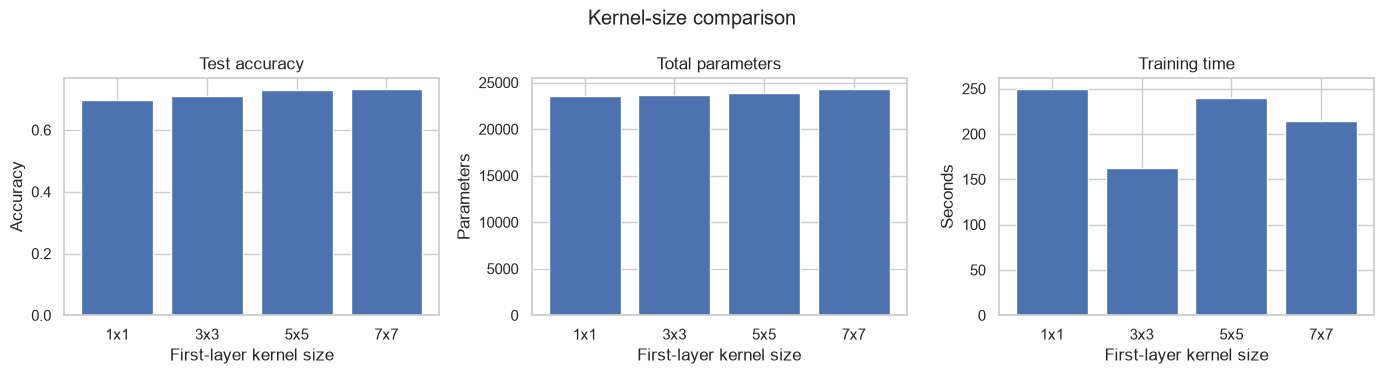

In [60]:
KERNELS = [1, 3, 5, 7]
KERNEL_SPECS = {k: flex_spec(kernel=k) for k in KERNELS}
if globals().get('RUN_FLAGS', {}).get('kernel', False):
    run_grid(list(KERNEL_SPECS.values()))

rows = []
for k in KERNELS:
    info, r = flex_info(KERNEL_SPECS[k]['model']['cfg']), peek(KERNEL_SPECS[k])
    d1 = info['dims'][0][1]
    rows.append({'Kernel': f'{k}x{k}', 'Output dims (conv1, same pad)': f'{d1}x{d1}', 'Output dims if valid pad': f"{conv_out_size(IMG_SIZE, k)}x{conv_out_size(IMG_SIZE, k)}",
                 'RF (conv1 / whole net)': f"{k} / {info['rf']}", 'First-conv params': info['first_conv_params'], '#Params (total)': info['params'],
                 'Train time (s)': np.nan if r is None else round(r['train_time'], 1), 'Epochs run': fmt_res(r, 'epochs_run'), 'Test Acc': fmt_res(r, 'test_acc')})
kernel_table = pd.DataFrame(rows).set_index('Kernel')
display(kernel_table.style.format({'Test Acc': '{:.4f}', '#Params (total)': '{:,.0f}'}, na_rep='-'))
kernel_table.to_csv('table_kernel.csv')
if kernel_table['Test Acc'].notna().any():
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.8)); kt = kernel_table.reset_index()
    ax[0].bar(kt['Kernel'], kt['Test Acc']); ax[0].set_title('Test accuracy'); ax[0].set_ylabel('Accuracy')
    ax[1].bar(kt['Kernel'], kt['#Params (total)']); ax[1].set_title('Total parameters'); ax[1].set_ylabel('Parameters')
    ax[2].bar(kt['Kernel'], kt['Train time (s)']); ax[2].set_title('Training time'); ax[2].set_ylabel('Seconds')
    for a_ in ax: a_.set_xlabel('First-layer kernel size')
    fig.suptitle('Kernel-size comparison'); fig.tight_layout(); savefig(fig, 'fig_kernel_comparison.png'); plt.show()

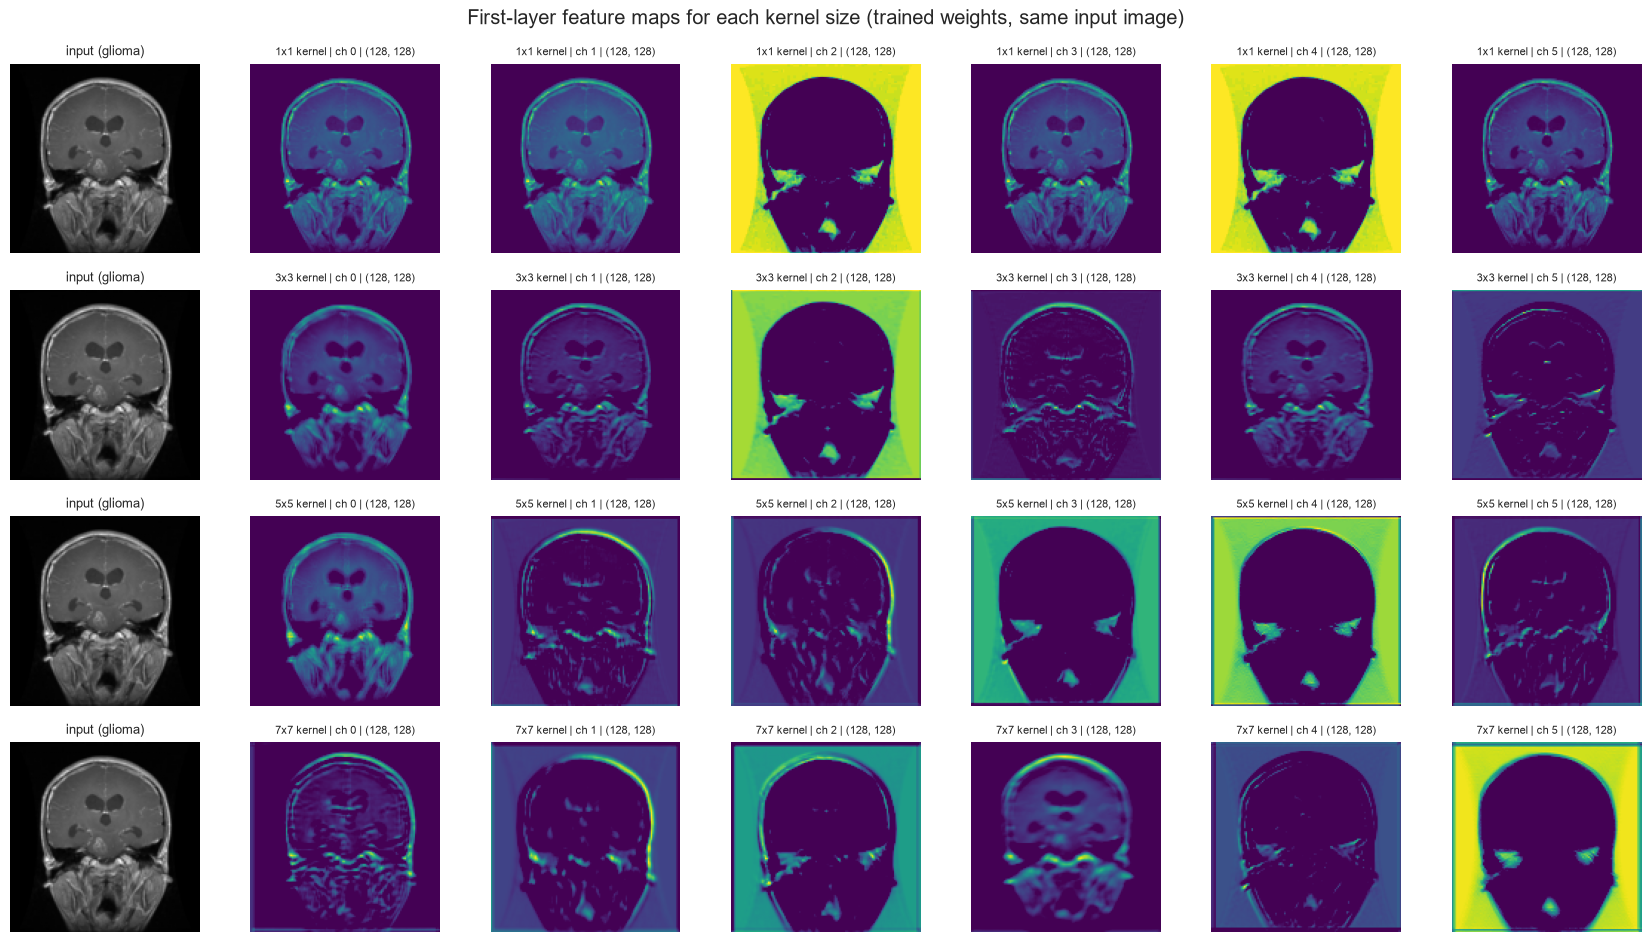

In [ ]:
FM_CLASS = 'glioma'
x_in = rep_input(FM_CLASS)
runs_ok = [k for k in KERNELS if peek(KERNEL_SPECS[k]) is not None]
if runs_ok:
    fig, axes = plt.subplots(len(runs_ok), 7, figsize=(17, 2.4 * len(runs_ok)))
    axes = np.atleast_2d(axes)
    for r_, k in enumerate(runs_ok):
        m = load_trained(KERNEL_SPECS[k])
        fm = capture(m, m.stages.block1[0], x_in)[0]
        axes[r_, 0].imshow(x_in[0, 0].cpu(), cmap='gray'); axes[r_, 0].set_title(f'input ({FM_CLASS})', fontsize=9)
        for j in range(6):
            axes[r_, j + 1].imshow(fm[j], cmap='viridis'); axes[r_, j + 1].set_title(f'{k}x{k} kernel | ch {j} | {tuple(fm.shape[1:])}', fontsize=8)
        for a_ in axes[r_]: a_.axis('off')
    fig.suptitle('First-layer feature maps for each kernel size (trained weights, same input image)'); fig.tight_layout()
    savefig(fig, 'fig_kernel_feature_maps.png'); plt.show()
else:
    print('Run the kernel experiment first.')

## 8.3 One $5\times5$ versus two stacked $3\times3$ convolutions, and the role of $1\times1$

These are pure calculations (no training). $C$ = number of input = output channels.

In [ ]:
def conv_params(cin, cout, k, bias=False):
    return cin * cout * k * k + (cout if bias else 0)

rows = []
for C in (16, 64, 256):
    one5, two3 = conv_params(C, C, 5), 2 * conv_params(C, C, 3)
    rows.append({'C (in = out)': C, 'one 5x5: params': one5, 'one 5x5: RF': receptive_field([(5, 1)]),
                 'two 3x3: params': two3, 'two 3x3: RF': receptive_field([(3, 1), (3, 1)]), 'params saved (%)': round((1 - two3 / one5) * 100, 1),
                 'non-linearities (5x5 / 3x3+3x3)': '1 / 2'})
display(pd.DataFrame(rows).set_index('C (in = out)'))

direct = conv_params(256, 256, 3)
bottleneck = conv_params(256, 64, 1) + conv_params(64, 64, 3) + conv_params(64, 256, 1)
print(f'3x3 conv 256->256 directly            : {direct:,} parameters')
print(f'1x1 (256->64) + 3x3 (64->64) + 1x1 (64->256): {bottleneck:,} parameters  ({bottleneck / direct * 100:.1f}% of the direct cost)')
c1 = nn.Conv2d(256, 64, 1); print('1x1 conv on a 256 x 16 x 16 map ->', tuple(c1(torch.zeros(1, 256, 16, 16)).shape), '(spatial size unchanged, channels 256 -> 64)')

,one 5x5: params,one 5x5: RF,two 3x3: params,two 3x3: RF,params saved (%),non-linearities (5x5 / 3x3+3x3)
C (in = out),,,,,,
16,6400,5,4608,5,28.0,1 / 2
64,102400,5,73728,5,28.0,1 / 2
256,1638400,5,1179648,5,28.0,1 / 2


3x3 conv 256->256 directly            : 589,824 parameters
1x1 (256->64) + 3x3 (64->64) + 1x1 (64->256): 69,632 parameters  (11.8% of the direct cost)
1x1 conv on a 256 x 16 x 16 map -> (1, 64, 16, 16) (spatial size unchanged, channels 256 -> 64)


Explain in your own words (in the answer cell): (i) why two stacked $3\times3$ layers are usually preferred over one $5\times5$ (parameters, extra non-linearity), and (ii) what a $1\times1$ convolution does (per-pixel linear mixing across channels, used to change/reduce the channel count cheaply).

## 8.4 Question
Based on your results, did larger kernels improve accuracy enough to justify their extra parameters and compute cost for this dataset? Use your table's numbers to support your answer.

### Answer

**8.3 (i) Two stacked $3\times3$ vs one $5\times5$.** Both see the same $5\times5$ area (receptive field 5). With $C$ input and output channels, one $5\times5$ conv has $25C^2$ weights and two $3\times3$ convs have $2\times9C^2 = 18C^2$, which is 28% fewer (for $C=16$: 6,400 vs 4,608; $C=64$: 102,400 vs 73,728; $C=256$: 1,638,400 vs 1,179,648). Two layers also have two ReLUs instead of one, so the network can learn more complex patterns.

**8.3 (ii) The $1\times1$ convolution.** It looks at one pixel at a time but mixes all the channels at that pixel with learned weights, like a small fully connected layer applied at every pixel. So it can change (usually reduce) the number of channels cheaply without changing the image size. In the notebook, a $1\times1$ conv turned a $256\times16\times16$ map into $64\times16\times16$. The bottleneck 1x1 (256 to 64) + 3x3 (64 to 64) + 1x1 (64 to 256) uses 69,632 parameters, only 11.8% of the 589,824 needed by a direct $3\times3$ conv from 256 to 256 channels.

**8.4 Did larger kernels pay off?** A bit, and in this small network they cost very little. Test accuracy was 0.6980 ($1\times1$), 0.7096 ($3\times3$), 0.7298 ($5\times5$) and 0.7328 ($7\times7$). Total parameters only went from 23,540 to 24,308 (+768, about 3%), because only the first layer changes (16, 144, 400 and 784 weights). The first layer's compute grows with $k^2$ ($7\times7$ costs about 5.4 times the $3\times3$ layer), but training time did not follow it: 249.6, 162.1, 239.2 and 213.8 s. That is mostly because the runs stopped at different epochs (23, 15, 22 and 19); per epoch they all took about 11 s.

The gain from $3\times3$ to $5\times5$ is +0.0202, but from $5\times5$ to $7\times7$ it is only +0.0030, so $5\times5$ looks like the best trade-off. The accuracy gap from $1\times1$ is more believable because a $1\times1$ kernel cannot see any neighbors. With one seed, differences of about 1 point (the noise level for a 1,980-image test set) should not be over-trusted.

---
# 9. Stride Experiment (Experiment 5)

Base network, first-layer kernel fixed at $3\times3$, first-layer stride $S=1,2,3$ ("same" padding, $P=1$). The output size is checked with $\lfloor (n+2P-K)/S\rfloor+1$, convolution multiply-accumulates (MACs) are counted analytically, and a **strided convolution** is tested as a replacement for a pooling layer.

In [ ]:
STRIDES = [1, 2, 3]
STRIDE_SPECS = {s: flex_spec(stride=s) for s in STRIDES}
if RUN_FLAGS['stride']:
    run_grid(list(STRIDE_SPECS.values()))

rows = []
for s in STRIDES:
    info, r = flex_info(STRIDE_SPECS[s]['model']['cfg']), peek(STRIDE_SPECS[s])
    d1 = info['dims'][0][1]
    assert d1 == (IMG_SIZE + 2 * 1 - 3) // s + 1
    rows.append({'Stride': s, 'Output dims (conv1)': f'{d1}x{d1}', 'Conv1 output positions': info['first_positions'],
                 'Positions kept vs input (%)': round(info['first_positions'] / IMG_SIZE ** 2 * 100, 1),
                 'Conv1 MACs': info['first_macs'], 'Total conv MACs': info['total_macs'], '#Params': info['params'],
                 'Train time (s)': np.nan if r is None else round(r['train_time'], 1), 'Test Acc': fmt_res(r, 'test_acc'),
                 'Notes': '' if r is None else r['status']})
stride_table = pd.DataFrame(rows).set_index('Stride')
display(stride_table.style.format({'Test Acc': '{:.4f}', 'Conv1 MACs': '{:,.0f}', 'Total conv MACs': '{:,.0f}', '#Params': '{:,.0f}'}, na_rep='-'))
stride_table.to_csv('table_stride.csv')
print('Parameters do not depend on stride (same #Params in every row), but MACs and output size do.' if stride_table['#Params'].nunique() == 1 else 'Check parameter counts!')

--- run 1/3
[cached] Flex|CE|Adam (8a1d9d0785)
--- run 2/3
[train ] Flex|CE|Adam (7dd37141c6)
  epoch   1/30 | train loss 1.0589 acc 0.5389 | val loss 0.8761 acc 0.6569 | 10.5s
  epoch   2/30 | train loss 0.8954 acc 0.6215 | val loss 1.0452 acc 0.5417 | 9.6s
  epoch   3/30 | train loss 0.8569 acc 0.6396 | val loss 0.7432 acc 0.7044 | 9.5s
  epoch   4/30 | train loss 0.8336 acc 0.6390 | val loss 0.8009 acc 0.6695 | 9.5s
  epoch   5/30 | train loss 0.8097 acc 0.6534 | val loss 0.7836 acc 0.6574 | 9.5s
  epoch   6/30 | train loss 0.7941 acc 0.6615 | val loss 0.6914 acc 0.7185 | 12.2s
  epoch   7/30 | train loss 0.7767 acc 0.6705 | val loss 0.9656 acc 0.5851 | 9.2s
  epoch   8/30 | train loss 0.7651 acc 0.6713 | val loss 0.6618 acc 0.7271 | 9.2s
  epoch   9/30 | train loss 0.7667 acc 0.6687 | val loss 0.6778 acc 0.7024 | 9.1s
  epoch  10/30 | train loss 0.7522 acc 0.6819 | val loss 0.6559 acc 0.7261 | 10.0s
  epoch  11/30 | train loss 0.7379 acc 0.6843 | val loss 0.8000 acc 0.6705 | 9.2s
 

,Output dims (conv1),Conv1 output positions,Positions kept vs input (%),Conv1 MACs,Total conv MACs,#Params,Train time (s),Test Acc,Notes
Stride,,,,,,,,,
1,128x128,16384,100.000000,"2,359,296","40,108,032","23,668",162.100000,0.7096,early stopped (patience 6)
2,64x64,4096,25.000000,"589,824","10,027,008","23,668",283.000000,0.7631,completed (full epoch budget)
3,43x43,1849,11.300000,"266,256","4,141,584","23,668",127.100000,0.7500,early stopped (patience 6)


Parameters do not depend on stride (same #Params in every row), but MACs and output size do.


### 9.1 Pooling layer vs strided convolution in the same position

`pool='max'` is a 2x2/2 max-pool after each block; `pool='stridedconv'` is a learnable $3\times3$, stride-2 convolution in the same position. The stride of the first conv is 1 in both.

--- run 1/2
[cached] Flex|CE|Adam (8a1d9d0785)
--- run 2/2
[train ] Flex|CE|Adam (80df2fc305)
  epoch   1/30 | train loss 1.0123 acc 0.5698 | val loss 0.8719 acc 0.6079 | 11.2s
  epoch   2/30 | train loss 0.8745 acc 0.6303 | val loss 0.7932 acc 0.6786 | 10.6s
  epoch   3/30 | train loss 0.8155 acc 0.6519 | val loss 0.8591 acc 0.6286 | 10.7s
  epoch   4/30 | train loss 0.7856 acc 0.6644 | val loss 0.9748 acc 0.6074 | 10.8s
  epoch   5/30 | train loss 0.7402 acc 0.6758 | val loss 0.6310 acc 0.7377 | 11.3s
  epoch   6/30 | train loss 0.7196 acc 0.6846 | val loss 0.6772 acc 0.7014 | 11.9s
  epoch   7/30 | train loss 0.6951 acc 0.7021 | val loss 0.6360 acc 0.7145 | 11.8s
  epoch   8/30 | train loss 0.6751 acc 0.7074 | val loss 0.6628 acc 0.7317 | 11.8s
  epoch   9/30 | train loss 0.6737 acc 0.7095 | val loss 0.7388 acc 0.6806 | 11.7s
  epoch  10/30 | train loss 0.6584 acc 0.7170 | val loss 0.7552 acc 0.6746 | 11.8s
  epoch  11/30 | train loss 0.6405 acc 0.7292 | val loss 0.7538 acc 0.6766 |

,Dims after each conv/pool/down layer,#Params,Total conv MACs,Train time (s),Test Acc
Down-sampling,,,,,
MaxPool 2x2/2,"[128, 64, 64, 32, 32, 16]","23,668","40,108,032",162.100000,0.7096
Strided conv 3x3/2,"[128, 64, 64, 32, 32, 16]","72,276","68,419,584",125.400000,0.7520


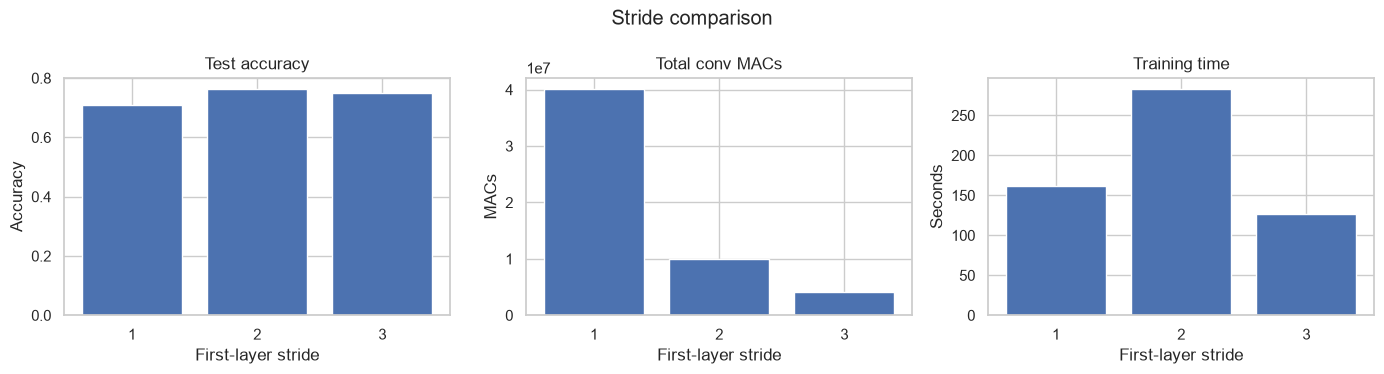

In [ ]:
DOWN_SPECS = {'MaxPool 2x2/2': flex_spec(pool='max'), 'Strided conv 3x3/2': flex_spec(pool='stridedconv')}
if RUN_FLAGS['stride']:
    run_grid(list(DOWN_SPECS.values()))
rows = []
for name, sp in DOWN_SPECS.items():
    info, r = flex_info(sp['model']['cfg']), peek(sp)
    rows.append({'Down-sampling': name, 'Dims after each conv/pool/down layer': [d for _, d in info['dims']], '#Params': info['params'],
                 'Total conv MACs': info['total_macs'], 'Train time (s)': np.nan if r is None else round(r['train_time'], 1), 'Test Acc': fmt_res(r, 'test_acc')})
display(pd.DataFrame(rows).set_index('Down-sampling').style.format({'Test Acc': '{:.4f}', '#Params': '{:,.0f}', 'Total conv MACs': '{:,.0f}'}, na_rep='-'))

if stride_table['Test Acc'].notna().any():
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
    st = stride_table.reset_index()
    ax[0].bar(st['Stride'].astype(str), st['Test Acc']); ax[0].set_title('Test accuracy'); ax[0].set_ylabel('Accuracy')
    ax[1].bar(st['Stride'].astype(str), st['Total conv MACs']); ax[1].set_title('Total conv MACs'); ax[1].set_ylabel('MACs')
    ax[2].bar(st['Stride'].astype(str), st['Train time (s)']); ax[2].set_title('Training time'); ax[2].set_ylabel('Seconds')
    for a_ in ax: a_.set_xlabel('First-layer stride')
    fig.suptitle('Stride comparison'); fig.tight_layout(); savefig(fig, 'fig_stride_comparison.png'); plt.show()

## 9.2 Question
Does stride affect the number of trainable parameters in a convolutional layer? Explain why or why not, and distinguish this from stride's effect on computational cost. Also discuss how much spatial information is discarded as the stride grows, and whether the strided convolution matched max-pooling in your runs.

### Answer

**Parameters:** No. A convolution's weights have shape $C_{out}\times C_{in}\times k\times k$, no matter how far the kernel jumps. All three stride rows have the same 23,668 parameters.

**Computation:** Yes. Stride changes how many positions the kernel visits, so the output size and the work change. With $\lfloor (128+2-3)/S\rfloor+1$, the first conv output is $128\times128$ (16,384 positions), $64\times64$ (4,096) and $43\times43$ (1,849) for $S=1,2,3$. Total conv MACs fall from 40.11M to 10.03M to 4.14M.

**Spatial information thrown away:** stride 2 keeps only 25% of the positions and stride 3 only 11.3%, so fine details such as small edges can be skipped. Still, accuracy did not drop in my runs: 0.7096 (stride 1), 0.7631 (stride 2) and 0.7500 (stride 3). So for this small network the lost positions did not hurt, but it is one seed and the differences are near the noise level.

**Strided conv vs max-pooling:** the strided conv gave the same output sizes (128, 64, 64, 32, 32, 16) and a test accuracy of 0.7520 vs 0.7096 for max-pooling, so it matched or beat it. But it costs more: 72,276 parameters vs 23,668 and 68.42M MACs vs 40.11M.

---
# 10. Padding Experiment (Experiment 6)

Valid ($P=0$) versus same padding ($P=\lfloor (k-1)/2\rfloor$) on the **first three convolutional layers** (kernel $3\times3$, stride 1, with $2\times2$ max-pooling after each).

## 10.1 Manual calculation

Input $n=128$ (`IMG_SIZE`).

| Layer | Valid: $\lfloor (n+0-3)/1\rfloor+1$ | After pool: $\lfloor (n-2)/2\rfloor+1$ | Same: $\lfloor (n+2-3)/1\rfloor+1$ | After pool |
|---|---|---|---|---|
| L1 | 126 | 63 | 128 | 64 |
| L2 | 61 | 30 | 64 | 32 |
| L3 | 28 | 14 | 32 | 16 |

Working for valid padding: L1 $=128-3+1=126$, pool $=\lfloor(126-2)/2\rfloor+1=63$; L2 $=63-3+1=61$, pool $=\lfloor(61-2)/2\rfloor+1=30$; L3 $=30-3+1=28$, pool $=\lfloor(28-2)/2\rfloor+1=14$. For same padding each conv keeps the size ($128$, $64$, $32$) and each pool halves it ($64$, $32$, $16$).

## 10.2 PyTorch verification and runs

In [ ]:
PADDINGS = ['valid', 'same']
PAD_SPECS = {p: flex_spec(padding=p) for p in PADDINGS}

dim_rows = []
for p in PADDINGS:
    info = flex_info(PAD_SPECS[p]['model']['cfg'])
    d = dict(info['dims'])
    dim_rows.append({'Padding': p, 'Dims after L1 (conv)': d['conv1'], 'after pool1': d['pool1'], 'Dims after L2 (conv)': d['conv2'], 'after pool2': d['pool2'],
                     'Dims after L3 (conv)': d['conv3'], 'after pool3': d['pool3']})
display(pd.DataFrame(dim_rows).set_index('Padding'))
print('Formula and PyTorch agree for every layer (assert in flex_info).')

if RUN_FLAGS['padding']:
    run_grid(list(PAD_SPECS.values()))
rows = []
for p in PADDINGS:
    info, r = flex_info(PAD_SPECS[p]['model']['cfg']), peek(PAD_SPECS[p]); d = dict(info['dims'])
    rows.append({'Padding': 'Valid (P=0)' if p == 'valid' else 'Same', 'Dims after L1': d['conv1'], 'Dims after L2': d['conv2'], 'Dims after L3': d['conv3'],
                 'Val Acc': fmt_res(r, 'val_acc'), 'Test Acc': fmt_res(r, 'test_acc')})
pad_table = pd.DataFrame(rows).set_index('Padding')
display(pad_table.style.format({'Val Acc': '{:.4f}', 'Test Acc': '{:.4f}'}, na_rep='-')); pad_table.to_csv('table_padding.csv')

,Dims after L1 (conv),after pool1,Dims after L2 (conv),after pool2,Dims after L3 (conv),after pool3
Padding,,,,,,
valid,126,63,61,30,28,14
same,128,64,64,32,32,16


Formula and PyTorch agree for every layer (assert in flex_info).
--- run 1/2
[train ] Flex|CE|Adam (523c1b8261)
  epoch   1/30 | train loss 1.0822 acc 0.5287 | val loss 0.9119 acc 0.6579 | 11.3s
  epoch   2/30 | train loss 0.9497 acc 0.5999 | val loss 1.1030 acc 0.5275 | 10.9s
  epoch   3/30 | train loss 0.9094 acc 0.6154 | val loss 0.9669 acc 0.5988 | 10.9s
  epoch   4/30 | train loss 0.8915 acc 0.6234 | val loss 0.8294 acc 0.6710 | 10.8s
  epoch   5/30 | train loss 0.8707 acc 0.6307 | val loss 0.7944 acc 0.6579 | 10.9s
  epoch   6/30 | train loss 0.8593 acc 0.6332 | val loss 0.7762 acc 0.6801 | 11.1s
  epoch   7/30 | train loss 0.8425 acc 0.6433 | val loss 0.8829 acc 0.6220 | 10.9s
  epoch   8/30 | train loss 0.8344 acc 0.6433 | val loss 0.7404 acc 0.7004 | 10.9s
  epoch   9/30 | train loss 0.8368 acc 0.6444 | val loss 0.7005 acc 0.7014 | 10.7s
  epoch  10/30 | train loss 0.8195 acc 0.6529 | val loss 0.7310 acc 0.6882 | 10.3s
  epoch  11/30 | train loss 0.8031 acc 0.6606 | val loss 0

,Dims after L1,Dims after L2,Dims after L3,Val Acc,Test Acc
Padding,,,,,
Valid (P=0),126,61,28,0.7064,0.7177
Same,128,64,32,0.7089,0.7096


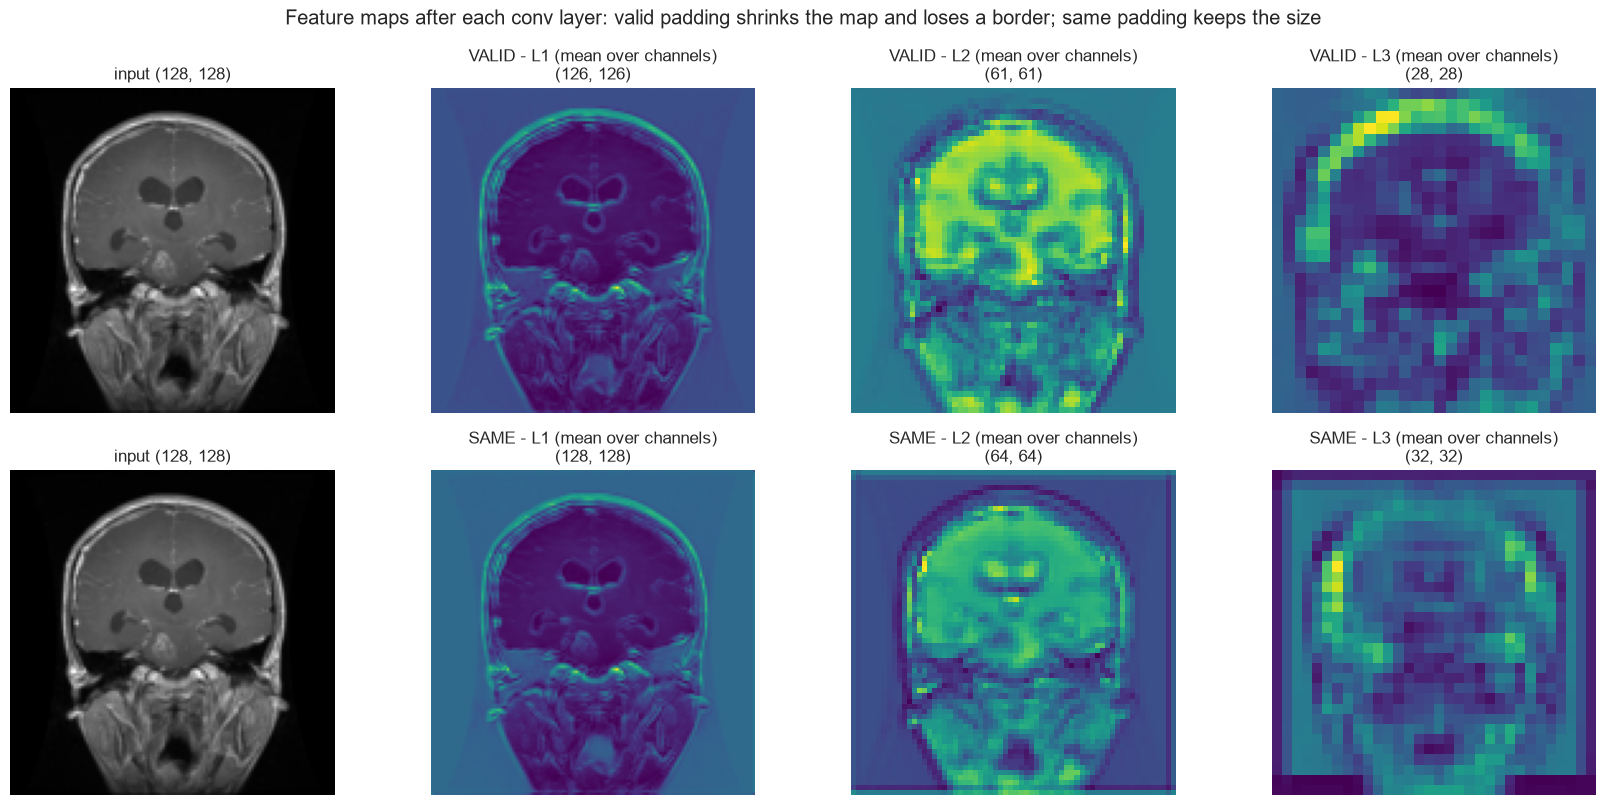

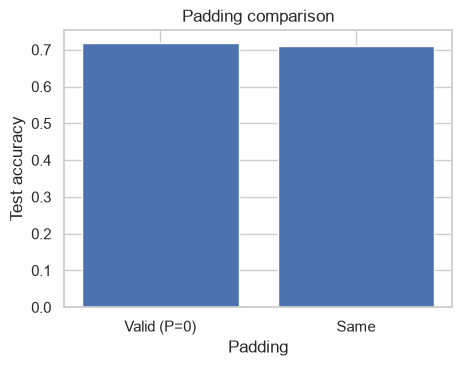

In [ ]:
x_in = rep_input(FM_CLASS)
if all(peek(PAD_SPECS[p]) is not None for p in PADDINGS):
    fig, axes = plt.subplots(2, 4, figsize=(17, 8.2))
    for r_, p in enumerate(PADDINGS):
        m = load_trained(PAD_SPECS[p])
        axes[r_, 0].imshow(x_in[0, 0].cpu(), cmap='gray'); axes[r_, 0].set_title(f'input {tuple(x_in.shape[2:])}'); axes[r_, 0].axis('off')
        for l in range(3):
            fm = capture(m, getattr(m.stages, f'block{l+1}')[0], x_in)[0]
            axes[r_, l + 1].imshow(fm.mean(0), cmap='viridis')
            axes[r_, l + 1].set_title(f'{p.upper()} - L{l+1} (mean over channels)\n{tuple(fm.shape[1:])}'); axes[r_, l + 1].axis('off')
    fig.suptitle('Feature maps after each conv layer: valid padding shrinks the map and loses a border; same padding keeps the size')
    fig.tight_layout(); savefig(fig, 'fig_padding_feature_maps.png'); plt.show()
else:
    print('Run the padding experiment first.')

if pad_table['Test Acc'].notna().any():
    fig, ax = plt.subplots(figsize=(5, 3.6)); ax.bar(pad_table.index, pad_table['Test Acc']); ax.set_title('Padding comparison'); ax.set_xlabel('Padding'); ax.set_ylabel('Test accuracy')
    savefig(fig, 'fig_padding_comparison.png'); plt.show()

In [61]:
try:
    IMG_SIZE
except NameError:
    IMG_SIZE = 128

def conv_out_size(n, k, s=1, p=0):
    return (n + 2 * p - k) // s + 1

def receptive_field(layers):
    rf, jump = 1, 1
    for k, s in layers:
        rf += (k - 1) * jump
        jump *= s
    return rf

def valid_depth_to_one_pixel(n, k):
    d = 0
    while n >= k:
        n = conv_out_size(n, k); d += 1
    return d, n

for k in (3, 5):
    d, last = valid_depth_to_one_pixel(IMG_SIZE, k)
    print(f'input {IMG_SIZE}, kernel {k}x{k}, stride 1, valid padding (no pooling): '
          f'size after d layers = {IMG_SIZE} - d*{k-1}; '
          f'{d} layers can be applied, final size {last}x{last}')

input 128, kernel 3x3, stride 1, valid padding (no pooling): size after d layers = 128 - d*2; 63 layers can be applied, final size 2x2
input 128, kernel 5x5, stride 1, valid padding (no pooling): size after d layers = 128 - d*4; 31 layers can be applied, final size 4x4


## 10.3 Question
Did valid padding measurably hurt performance for a network this shallow? At what depth (number of valid-padding layers) would the feature map shrink to a single pixel for your chosen input size and kernel size? Show the calculation. Also explain why repeated valid-padding convolutions shrink the resolution quickly, and what information is lost at the image boundary.

### Answer

**Did valid padding hurt?** No. Test accuracy was 0.7177 with valid padding and 0.7096 with same padding (validation 0.7064 vs 0.7089). The difference is tiny and within noise. The network is shallow (3 convs), so losing 2 pixels per conv at the border costs little. This is one seed, so I would not say valid is really better.

**How deep until one pixel?** A $3\times3$, stride-1 valid conv takes $n$ to $n-2$, so after $d$ layers the size is

$$n_d = 128 - 2d$$

After $d=63$ layers the map is $128-126=2$, so $2\times2$. A 64th $3\times3$ conv does not fit in a $2\times2$ map, and $128-2d=1$ would need $d=63.5$. So this even input never reaches exactly $1\times1$ (an odd input such as 127 would reach it at $d=63$). For $5\times5$ kernels, $n_d=128-4d$, so 31 layers give $4\times4$ and the 32nd cannot be applied.

**Why the map shrinks and what is lost:** a valid conv cannot center the kernel on border pixels, so every layer removes $k-1$ pixels from the height and from the width, and this adds up with each layer (and pooling shrinks it even more). Border pixels are also used by fewer kernel windows (a corner pixel is in only one $3\times3$ window, a center pixel in nine), so the information near the edge of the image is used less and then cut off. Anything near the border, such as a tumor close to the edge of the scan, can be lost. Same padding adds zeros around the image so the border pixels still get used.

---
# 11. Pooling Experiment (Experiment 7)

Three strategies, $2\times2$ pooling with stride 2 as the primary setting:

| Row | Intermediate down-sampling | Head |
|---|---|---|
| MaxPool 2x2/2 | max-pool after each conv block | flatten -> FC(64) -> classes |
| AvgPool 2x2/2 | average-pool after each conv block | flatten -> FC(64) -> classes |
| Global Avg Pool | max-pool 2x2/2 (as above) | **global average pooling** -> classes |

Secondary comparison: $3\times3$ pooling with stride 2 (max and average, flatten head). The GAP row keeps max-pooling between blocks and replaces only the flatten + FC head, so it differs from the MaxPool row by the head alone (and has a much smaller classifier: 23,668 vs 1,072,308 parameters).

--- run 1/5
[train ] Flex|CE|Adam (1fe839b029)
  epoch   1/30 | train loss 1.0729 acc 0.5041 | val loss 0.7270 acc 0.6988 | 11.5s
  epoch   2/30 | train loss 0.8657 acc 0.5973 | val loss 0.6589 acc 0.7115 | 10.7s
  epoch   3/30 | train loss 0.8181 acc 0.6300 | val loss 0.7586 acc 0.6877 | 10.9s
  epoch   4/30 | train loss 0.7911 acc 0.6424 | val loss 0.6878 acc 0.6943 | 10.6s
  epoch   5/30 | train loss 0.7743 acc 0.6572 | val loss 0.6243 acc 0.6766 | 10.7s
  epoch   6/30 | train loss 0.7662 acc 0.6569 | val loss 0.6452 acc 0.7120 | 10.6s
  epoch   7/30 | train loss 0.7461 acc 0.6613 | val loss 0.6008 acc 0.7110 | 10.6s
  epoch   8/30 | train loss 0.7385 acc 0.6634 | val loss 0.6596 acc 0.7221 | 10.7s
  epoch   9/30 | train loss 0.7245 acc 0.6630 | val loss 0.5788 acc 0.7256 | 10.5s
  epoch  10/30 | train loss 0.7071 acc 0.6747 | val loss 0.6409 acc 0.7196 | 10.8s
  epoch  11/30 | train loss 0.7136 acc 0.6659 | val loss 0.5843 acc 0.7372 | 10.8s
  epoch  12/30 | train loss 0.6898 acc 0

,Output dims,Train time (s),Test Acc,#Params,Notes
Pooling,,,,,
MaxPool 2x2/2,64x64 after pool1; features into classifier: 16384,320.200000,0.7838,"1,072,308",train-val gap +0.017; val acc 0.778; completed (full epoch budget)
AvgPool 2x2/2,64x64 after pool1; features into classifier: 16384,318.500000,0.7975,"1,072,308",train-val gap +0.008; val acc 0.818; completed (full epoch budget)
Global Avg Pool,64x64 after pool1; features into classifier: 64,162.100000,0.7096,"23,668",train-val gap -0.009; val acc 0.709; early stopped (patience 6)
MaxPool 3x3/2 (secondary),63x63 after pool1; features into classifier: 14400,323.200000,0.8000,"945,332",train-val gap +0.013; val acc 0.798; completed (full epoch budget)
AvgPool 3x3/2 (secondary),63x63 after pool1; features into classifier: 14400,216.700000,0.7813,"945,332",train-val gap +0.016; val acc 0.785; early stopped (patience 6)


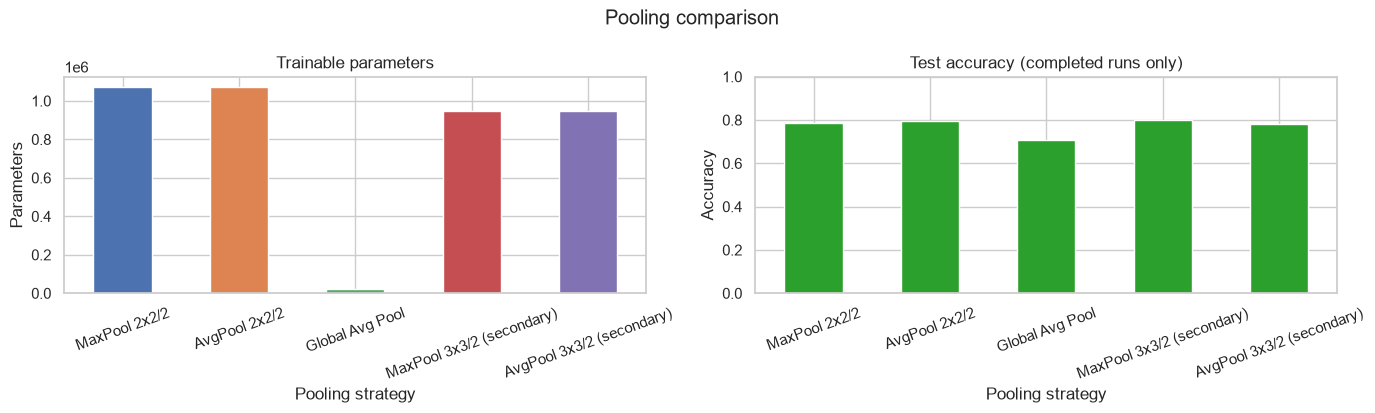

In [112]:
POOL_SPECS = {
    'MaxPool 2x2/2': flex_spec(pool='max', pool_k=2, pool_s=2, head='flatten'),
    'AvgPool 2x2/2': flex_spec(pool='avg', pool_k=2, pool_s=2, head='flatten'),
    'Global Avg Pool': flex_spec(pool='max', pool_k=2, pool_s=2, head='gap'),
    'MaxPool 3x3/2 (secondary)': flex_spec(pool='max', pool_k=3, pool_s=2, head='flatten'),
    'AvgPool 3x3/2 (secondary)': flex_spec(pool='avg', pool_k=3, pool_s=2, head='flatten'),
}
if 'COMB_SPECS' in globals() and 'A' in COMB_SPECS:
    POOL_SPECS['Global Avg Pool'] = COMB_SPECS['A']
if globals().get('RUN_FLAGS', {}).get('pooling', False):
    run_grid(list(POOL_SPECS.values()))

rows = []
for name, sp in POOL_SPECS.items():
    info, r = flex_info(sp['model']['cfg']), peek(sp)
    pool_dims = [d for n_, d in info['dims'] if n_.startswith('pool')]
    out_dims = f"{pool_dims[0]}x{pool_dims[0]} after pool1; features into classifier: {info['flat']}"
    note = '' if r is None else f"train-val gap {r['train_acc'] - r['val_acc']:+.3f}; val acc {r['val_acc']:.3f}; {r['status']}"
    rows.append({'Pooling': name, 'Output dims': out_dims, 'Train time (s)': np.nan if r is None else round(r['train_time'], 1),
                 'Test Acc': fmt_res(r, 'test_acc'), '#Params': info['params'], 'Notes': note})
pool_table = pd.DataFrame(rows).set_index('Pooling')
display(pool_table.style.format({'Test Acc': '{:.4f}', '#Params': '{:,.0f}'}, na_rep='-')); pool_table.to_csv('table_pooling.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
pool_table['#Params'].plot(kind='bar', ax=axes[0], color=sns.color_palette('deep', len(pool_table)))
axes[0].set_title('Trainable parameters'); axes[0].set_xlabel('Pooling strategy'); axes[0].set_ylabel('Parameters')
axes[0].tick_params(axis='x', rotation=20)
completed = pool_table['Test Acc'].dropna()
if completed.empty:
    axes[1].text(0.5, 0.5, 'No completed pooling runs', ha='center', va='center', transform=axes[1].transAxes)
else:
    completed.plot(kind='bar', ax=axes[1], color='tab:green')
    axes[1].set_ylim(0, 1)
    axes[1].tick_params(axis='x', rotation=20)
    for name in pool_table.index[pool_table['Test Acc'].isna()]:
        axes[1].text(0.02, 0.96 - 0.08 * list(pool_table.index).index(name), f'{name}: not run',
                     transform=axes[1].transAxes, va='top', fontsize=8)
axes[1].set_title('Test accuracy (completed runs only)'); axes[1].set_xlabel('Pooling strategy'); axes[1].set_ylabel('Accuracy')
fig.suptitle('Pooling comparison')
fig.tight_layout(); savefig(fig, 'fig_pooling_comparison.png'); plt.show()

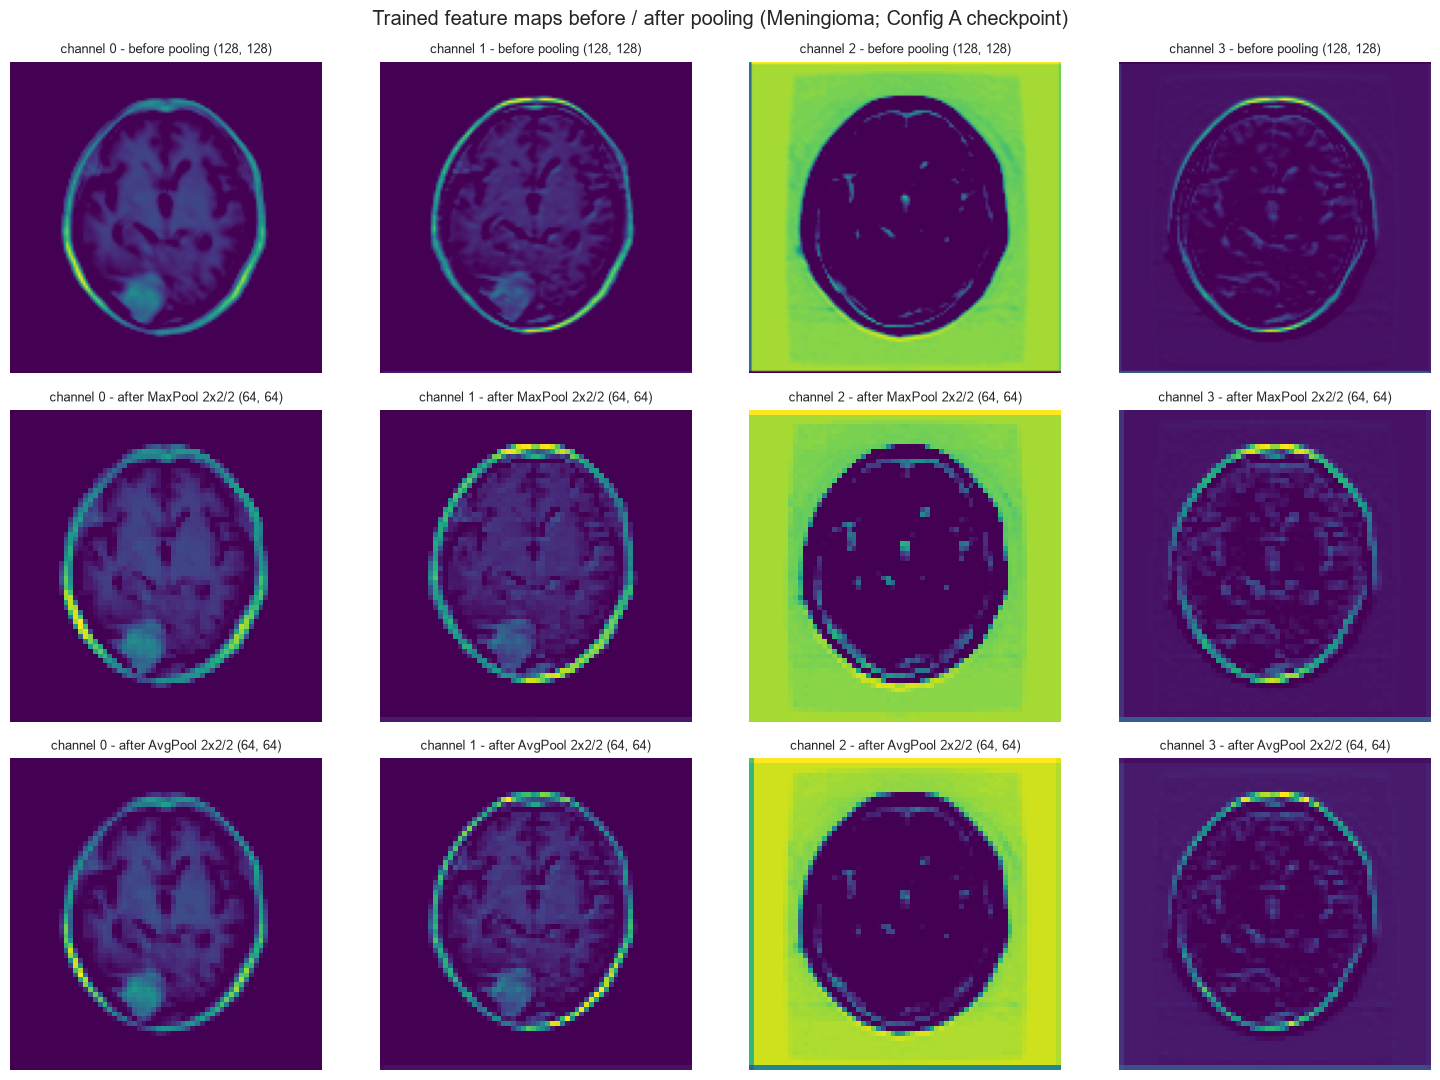

Feature maps use the cached trained Config A checkpoint; no training was run.


In [91]:
POOL_CLASS = 'meningioma'
if 'COMB_SPECS' in globals() and peek(COMB_SPECS['A']) is not None:
    m = load_trained(COMB_SPECS['A'])
    image_path = os.path.join(DATA_ROOT, POOL_CLASS, '00103.png')
    image = Image.open(image_path).convert('L').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    image_array = np.array(image, dtype=np.uint8)
    mean = globals().get('MEAN', 0.1726)
    std = globals().get('STD', 0.1837)
    x_in = torch.from_numpy(image_array).float().div(255.0).sub(mean).div(std)[None, None].to(DEVICE)
    pre = capture(m, m.stages.block1[0], x_in)
    mx, av = F.max_pool2d(pre, 2, 2), F.avg_pool2d(pre, 2, 2)
    chans = [0, 1, 2, 3]
    fig, axes = plt.subplots(3, 4, figsize=(15, 11))
    for j, ch in enumerate(chans):
        for r_, (title, feature_map) in enumerate([
            ('before pooling', pre),
            ('after MaxPool 2x2/2', mx),
            ('after AvgPool 2x2/2', av),
        ]):
            axes[r_, j].imshow(feature_map[0, ch].cpu(), cmap='viridis')
            axes[r_, j].set_title(f'channel {ch} - {title} {tuple(feature_map.shape[2:])}', fontsize=9)
            axes[r_, j].axis('off')
    fig.suptitle(f'Trained feature maps before / after pooling ({CLASS_TITLES[POOL_CLASS]}; Config A checkpoint)')
    fig.tight_layout(); savefig(fig, 'fig_pooling_feature_maps.png'); plt.show()
    print('Feature maps use the cached trained Config A checkpoint; no training was run.')
else:
    print('No completed Config A checkpoint is available for trained pooling feature maps.')

## 11.1 Explanations

1. Why max pooling keeps strong local activations while average pooling gives smoother features.
2. Why pooling layers have **no trainable parameters**, and how gradients flow: max-pool routes the gradient only to the arg-max position, average-pool spreads it equally (a numerical demonstration is in Section 13).
3. Why global average pooling is useful right before the classifier in ResNet / GoogLeNet.

## 11.2 Question
In a medical imaging context, where a faint but diagnostically critical signal (e.g. a small tumor boundary) could be smoothed away, which pooling strategy would you expect to be safer, and did your results confirm this expectation?

### Answer

**11.1 (1)** Max pooling keeps the biggest number in each window, so a strong activation (a sharp edge or a bright spot) survives unchanged. Average pooling takes the mean of the window, so a strong value is mixed with its weaker neighbors and the result is smoother (in the demo, the window 1, 3, 4, 2 gives a max of 4 but an average of 2.5).

**11.1 (2)** Pooling uses a fixed rule (take the max or the mean), so there are no weights to learn. For gradients, max-pool sends the whole gradient to the one position that had the maximum and gives 0 to the others. Average-pool splits it equally, so each position of a $2\times2$ window gets 0.25 (see Section 13.9).

**11.1 (3)** Global average pooling turns each feature map into one number, so the classifier only gets one value per channel (for example 256 for ResNet and 224 for GoogLeNet) instead of a huge flattened vector (13,456 for LeNet-5). That means far fewer weights in the classifier, less overfitting, and it works for any image size.

**11.2** I would expect **max pooling** to be safer, because it keeps the strongest response in each window, while average pooling can wash out a faint signal. My results did not clearly confirm this:

- $2\times2$ pooling: average 0.7975 was higher than max 0.7838.
- $3\times3$ pooling: max 0.8000 was higher than average 0.7813.

So there was no consistent winner, and the gaps (about 1 to 2 points) are near the noise level of a single run. Overall accuracy also cannot tell if faint tumor boundaries were kept. The GAP row (0.7096) had a very small classifier and no overfitting (train-val gap -0.009), but lower accuracy than the flatten + FC rows. A likely reason is that GAP throws away where in the image a feature appeared, but this row also changes the classifier size, so I cannot separate the two effects.

---
# 12. Combined Hyperparameter Experiments (Experiment 8)

Six combined configurations on the base `FlexCNN` (kernel and stride on the first conv, padding on all convs, pooling after each block, GAP head). Config A is identical to the base network, so it **reuses** the run already done in Sections 8-11.

--- run 1/6
[cached] Flex|CE|Adam (8a1d9d0785)
--- run 2/6
[train ] Flex|CE|Adam (a25437922b)
  epoch   1/30 | train loss 1.1008 acc 0.5290 | val loss 0.9118 acc 0.6271 | 10.5s
  epoch   2/30 | train loss 0.9644 acc 0.5933 | val loss 0.8525 acc 0.6594 | 10.4s
  epoch   3/30 | train loss 0.9216 acc 0.6122 | val loss 0.8345 acc 0.6705 | 10.6s
  epoch   4/30 | train loss 0.8975 acc 0.6150 | val loss 0.8335 acc 0.6539 | 10.1s
  epoch   5/30 | train loss 0.8750 acc 0.6319 | val loss 0.8050 acc 0.6599 | 10.1s
  epoch   6/30 | train loss 0.8643 acc 0.6297 | val loss 0.7892 acc 0.6665 | 10.1s
  epoch   7/30 | train loss 0.8493 acc 0.6425 | val loss 0.8230 acc 0.6513 | 10.1s
  epoch   8/30 | train loss 0.8405 acc 0.6383 | val loss 0.8651 acc 0.6331 | 10.6s
  epoch   9/30 | train loss 0.8396 acc 0.6448 | val loss 0.7626 acc 0.6892 | 10.2s
  epoch  10/30 | train loss 0.8285 acc 0.6505 | val loss 0.7185 acc 0.7059 | 10.3s
  epoch  11/30 | train loss 0.8145 acc 0.6527 | val loss 1.2261 acc 0.4967 |

,Kernel,Stride,Padding,Pooling,Test Acc,Final map dims,#Params,Total conv MACs,Train time (s)
Config,,,,,,,,,
A,3x3,1,Same,Max,0.7096,16,"23,668","40,108,032",162.100000
B,3x3,1,Same,Average,0.7444,16,"23,668","40,108,032",307.300000
C,5x5,1,Valid,Max,0.7455,14,"23,924","37,189,888",242.900000
D,5x5,2,Same,Average,0.7429,8,"23,924","11,075,584",131.700000
E,7x7,1,Valid,Max,0.7566,13,"24,308","41,146,432",250.400000
F,3x3,2,Same,None,0.7283,64,"23,668","94,961,664",235.200000


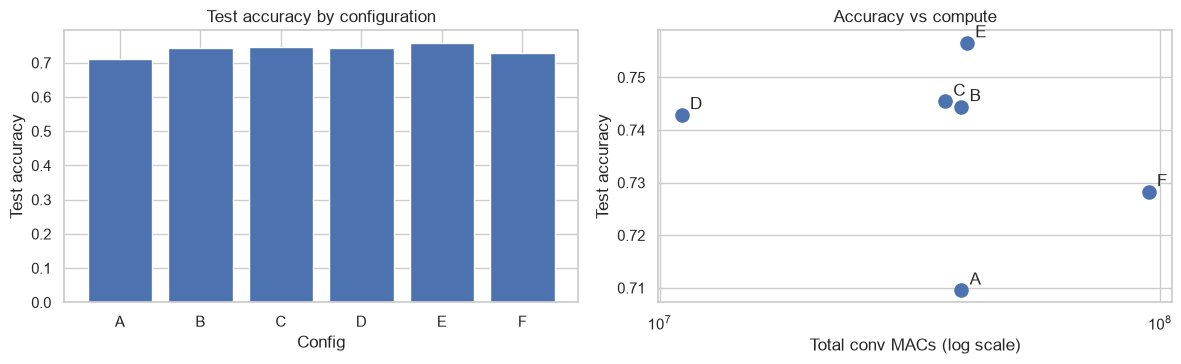

In [113]:
COMBINED = OrderedDict([
    ('A', dict(kernel=3, stride=1, padding='same',  pool='max')),
    ('B', dict(kernel=3, stride=1, padding='same',  pool='avg')),
    ('C', dict(kernel=5, stride=1, padding='valid', pool='max')),
    ('D', dict(kernel=5, stride=2, padding='same',  pool='avg')),
    ('E', dict(kernel=7, stride=1, padding='valid', pool='max')),
    ('F', dict(kernel=3, stride=2, padding='same',  pool='none')),
])
COMB_SPECS = {k: flex_spec(**v) for k, v in COMBINED.items()}
if globals().get('RUN_FLAGS', {}).get('combined', False):
    run_grid(list(COMB_SPECS.values()))

rows = []
for k, v in COMBINED.items():
    info, r = flex_info(COMB_SPECS[k]['model']['cfg']), peek(COMB_SPECS[k])
    rows.append({'Config': k, 'Kernel': f"{v['kernel']}x{v['kernel']}", 'Stride': v['stride'], 'Padding': v['padding'].capitalize(),
                 'Pooling': {'max': 'Max', 'avg': 'Average', 'none': 'None'}[v['pool']], 'Test Acc': fmt_res(r, 'test_acc'),
                 'Final map dims': info['dims'][-1][1], '#Params': info['params'], 'Total conv MACs': info['total_macs'],
                 'Train time (s)': np.nan if r is None else round(r['train_time'], 1)})
comb_table = pd.DataFrame(rows).set_index('Config')
display(comb_table.style.format({'Test Acc': '{:.4f}', '#Params': '{:,.0f}', 'Total conv MACs': '{:,.0f}'}, na_rep='-')); comb_table.to_csv('table_combined.csv')

if comb_table['Test Acc'].notna().any():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    ax[0].bar(comb_table.index, comb_table['Test Acc']); ax[0].set_title('Test accuracy by configuration'); ax[0].set_xlabel('Config'); ax[0].set_ylabel('Test accuracy')
    sc = ax[1].scatter(comb_table['Total conv MACs'], comb_table['Test Acc'], s=90)
    for k_, row in comb_table.iterrows(): ax[1].annotate(k_, (row['Total conv MACs'], row['Test Acc']), textcoords='offset points', xytext=(6, 4))
    ax[1].set_xscale('log'); ax[1].set_title('Accuracy vs compute'); ax[1].set_xlabel('Total conv MACs (log scale)'); ax[1].set_ylabel('Test accuracy')
    fig.tight_layout(); savefig(fig, 'fig_combined_comparison.png'); plt.show()

## 12.1 Question
Do the effects of kernel size, stride, padding, and pooling appear to be *independent*, or do you see evidence of interaction (the effect of one parameter changes depending on another)? Use specific rows from your table (e.g. Config C versus Config E) to support your answer, and discuss the trade-off between spatial resolution, receptive field, computational cost, and accuracy.

### Answer

The results suggest the settings **interact**, but the six rows change several settings at once (it is not a full factorial design), so this is a hint and not proof.

- **Pooling effect depends on the setup.** A to B changes only max to average pooling: 0.7096 to 0.7444 (+0.0348). But in Section 11 (flatten head), $2\times2$ average beat max by only +0.0137, and with $3\times3$ pooling max was better. So the effect of pooling changes with the other settings.
- **Kernel effect depends on padding.** Config C ($5\times5$, valid, max) 0.7455 vs Config E ($7\times7$, valid, max) 0.7566 is +0.0111. With same padding in Section 8 the same step ($5\times5$ to $7\times7$) gave only +0.0030.
- **Cost vs accuracy.** Config D ($5\times5$, stride 2, average) has a final map of $8\times8$, a receptive field of 43 and 11.08M conv MACs, and got 0.7429, almost the same as Config B (0.7444) which uses 40.11M MACs. Config F (stride 2, no pooling) keeps a $64\times64$ final map and uses the most compute (94.96M MACs) but only got 0.7283 with the smallest receptive field (11).

**Trade-off:** high spatial resolution (F) is expensive and did not give better accuracy; downsampling (D) gives a big receptive field and low compute, but a small final map; the best accuracy was Config E (0.7566) with a medium cost (41.15M MACs), receptive field 26 and a $13\times13$ final map. No configuration was best in everything.

---
# 13. Mathematical Verification Summary

## 13.1 Convolution output dimensions for every configuration tested

In [93]:
rows = []
if all(name in globals() for name in ('PATCH', 'CONV_RESULTS', 'CLASS_KEYS')):
    rows.append({
        'Where': 'Sec. 4 patch',
        'Config': f'{PATCH}x{PATCH} patch, k=3, s=1, P=0',
        'Dims after each conv/pool layer': [conv_out_size(PATCH, 3)],
        'Formula == PyTorch': all(
            CONV_RESULTS[c]['manual'].shape == (conv_out_size(PATCH, 3),) * 2
            for c in CLASS_KEYS
        ),
    })

group_specs = [
    ('Sec. 8 kernel', globals().get('KERNEL_SPECS')),
    ('Sec. 9 stride', globals().get('STRIDE_SPECS')),
    ('Sec. 9.1 down-sampling', globals().get('DOWN_SPECS')),
    ('Sec. 10 padding', globals().get('PAD_SPECS')),
    ('Sec. 11 pooling', globals().get('POOL_SPECS')),
    ('Sec. 12 combined', globals().get('COMB_SPECS')),
]
for where, specs in group_specs:
    if not specs:
        continue
    for name, spec in specs.items():
        info = flex_info(spec['model']['cfg'])
        rows.append({
            'Where': where,
            'Config': name,
            'Dims after each conv/pool layer': [dim for _, dim in info['dims']],
            'Formula == PyTorch': True,
        })

pd.set_option('display.max_colwidth', 120)
dims_summary = pd.DataFrame(rows, columns=[
    'Where', 'Config', 'Dims after each conv/pool layer', 'Formula == PyTorch'
])
display(dims_summary)

,Where,Config,Dims after each conv/pool layer,Formula == PyTorch
0,Sec. 8 kernel,1,"[128, 64, 64, 32, 32, 16]",True
1,Sec. 8 kernel,3,"[128, 64, 64, 32, 32, 16]",True
2,Sec. 8 kernel,5,"[128, 64, 64, 32, 32, 16]",True
3,Sec. 8 kernel,7,"[128, 64, 64, 32, 32, 16]",True
4,Sec. 11 pooling,MaxPool 2x2/2,"[128, 64, 64, 32, 32, 16]",True
5,Sec. 11 pooling,AvgPool 2x2/2,"[128, 64, 64, 32, 32, 16]",True
6,Sec. 11 pooling,Global Avg Pool,"[128, 64, 64, 32, 32, 16]",True
7,Sec. 11 pooling,MaxPool 3x3/2 (secondary),"[128, 63, 63, 31, 31, 15]",True
8,Sec. 11 pooling,AvgPool 3x3/2 (secondary),"[128, 63, 63, 31, 31, 15]",True
9,Sec. 12 combined,A,"[128, 64, 64, 32, 32, 16]",True


## 13.2 Convolutional parameters for each kernel size
For a conv layer without bias: $k^2\,C_{in}\,C_{out}$ (our convs have no bias because BatchNorm follows; BatchNorm adds $2C_{out}$).

In [94]:
rows = []
for k in KERNELS:
    m = FlexCNN(**KERNEL_SPECS[k]['model']['cfg']); conv1 = m.stages.block1[0][0]; bn1 = m.stages.block1[0][1]
    formula = k * k * 1 * 16
    counted = sum(p.numel() for p in conv1.parameters())
    assert formula == counted
    rows.append({'Kernel': f'{k}x{k}', 'k^2 * Cin * Cout = k^2*1*16': formula, 'counted in PyTorch': counted, 'BatchNorm params (2*Cout)': sum(p.numel() for p in bn1.parameters()),
                 'whole network': count_params(m)})
display(pd.DataFrame(rows).set_index('Kernel'))

,k^2 * Cin * Cout = k^2*1*16,counted in PyTorch,BatchNorm params (2*Cout),whole network
Kernel,,,,
1x1,16,16,32,23540
3x3,144,144,32,23668
5x5,400,400,32,23924
7x7,784,784,32,24308


## 13.3 Receptive fields

In [95]:
print('1 layer  (3x3, s=1)               :', receptive_field([(3, 1)]))
print('2 stacked 3x3, s=1                :', receptive_field([(3, 1), (3, 1)]), ' = 3 + (3-1)*1')
print('one 5x5, s=1                      :', receptive_field([(5, 1)]))
lenet_layers = [(5, 1), (2, 2), (5, 1), (2, 2)]
print('LeNet-5 conv/pool stack           :', receptive_field(lenet_layers))
print('FlexCNN base (full depth, 3 blocks):', base_info['rf'], ' <- layers (k,s):', [(sp['k'], sp['s']) for sp in FlexCNN(**flex_cfg()).layer_specs])
rows = [{'Config': f'Config {k}', 'Receptive field (full conv/pool stack)': flex_info(s['model']['cfg'])['rf']} for k, s in COMB_SPECS.items()]
display(pd.DataFrame(rows).set_index('Config'))

1 layer  (3x3, s=1)               : 3
2 stacked 3x3, s=1                : 5  = 3 + (3-1)*1
one 5x5, s=1                      : 5
LeNet-5 conv/pool stack           : 16
FlexCNN base (full depth, 3 blocks): 22  <- layers (k,s): [(3, 1), (2, 2), (3, 1), (2, 2), (3, 1), (2, 2)]


,Receptive field (full conv/pool stack)
Config,
Config A,22
Config B,22
Config C,24
Config D,43
Config E,26
Config F,11


## 13.4 Pooling output dimensions

In [96]:
rows = []
for k_, s_, n in [(2, 2, IMG_SIZE), (3, 2, IMG_SIZE), (2, 2, IMG_SIZE - 2), (3, 2, IMG_SIZE - 2)]:
    formula = (n - k_) // s_ + 1
    t = torch.zeros(1, 1, n, n)
    assert F.max_pool2d(t, k_, s_).shape[-1] == formula == F.avg_pool2d(t, k_, s_).shape[-1]
    rows.append({'Input n': n, 'Pool k / stride': f'{k_} / {s_}', 'floor((n-k)/s)+1': formula, 'PyTorch max/avg pool': formula})
rows.append({'Input n': IMG_SIZE, 'Pool k / stride': 'global', 'floor((n-k)/s)+1': 1, 'PyTorch max/avg pool': tuple(nn.AdaptiveAvgPool2d(1)(torch.zeros(1, 8, IMG_SIZE, IMG_SIZE)).shape[2:])})
display(pd.DataFrame(rows))

,Input n,Pool k / stride,floor((n-k)/s)+1,PyTorch max/avg pool
0,128,2 / 2,64,64
1,128,3 / 2,63,63
2,126,2 / 2,63,63
3,126,3 / 2,62,62
4,128,global,1,"(1, 1)"


## 13.5 Flattened feature dimension entering the first fully connected layer (LeNet-5, by hand)

In [97]:
n = IMG_SIZE
n1 = conv_out_size(n, 5); p1 = n1 // 2
n2 = conv_out_size(p1, 5); p2 = n2 // 2
by_hand = 16 * p2 * p2
print(f'{n} -> conv5: {n1} -> pool: {p1} -> conv5: {n2} -> pool: {p2}   =>  flatten = 16 * {p2} * {p2} = {by_hand}')
lenet = LeNet5(img_size=IMG_SIZE)
assert lenet.stages.fc1[0].in_features == by_hand == lenet.flat_dim
print('PyTorch fc1 in_features =', lenet.stages.fc1[0].in_features, '-> matches the hand calculation')
display(pd.DataFrame({a: {'features into classifier': MODEL_ZOO[a](img_size=IMG_SIZE).flat_dim} for a in ARCHS}).T)

128 -> conv5: 124 -> pool: 62 -> conv5: 58 -> pool: 29   =>  flatten = 16 * 29 * 29 = 13456
PyTorch fc1 in_features = 13456 -> matches the hand calculation


,features into classifier
LeNet-5,13456
AlexNet,2304
VGG,1024
GoogLeNet,224
ResNet,256
EfficientNet,320


## 13.6 Total trainable parameters of the six architectures

In [98]:
param_rows = {a: count_params(MODEL_ZOO[a](in_ch=1, num_classes=NUM_CLASSES, img_size=IMG_SIZE)) for a in ARCHS}
param_table = pd.DataFrame({'trainable parameters': param_rows})
if 'EXP1_SPECS' in globals():
    for a in ARCHS:
        result = peek(EXP1_SPECS[a])
        if result is not None:
            assert result['params'] == param_rows[a], a
display(param_table.style.format('{:,.0f}'))

,trainable parameters
LeNet-5,"1,627,916"
AlexNet,"5,869,380"
VGG,"2,833,892"
GoogLeNet,"165,476"
ResNet,"2,796,772"
EfficientNet,"606,276"


## 13.7 Loss values computed by hand for one prediction

One image, 4 logits $z=(2.0,\,0.5,\,-1.0,\,0.0)$, true class = Meningioma (index 1).
$p_c=\dfrac{e^{z_c}}{\sum_j e^{z_j}}$, $\;L_{CE}=-\ln p_y$, $\;L_{LS}=(1-\varepsilon)L_{CE}+\varepsilon\frac1K\sum_c(-\ln p_c)$, $\;L_{focal}=-\alpha_y(1-p_y)^{\gamma}\ln p_y$.

In [117]:
LABEL_SMOOTH_EPS = globals().get('LABEL_SMOOTH_EPS', 0.1)
FOCAL_GAMMA = globals().get('FOCAL_GAMMA', 2.0)
_SAVED_TRAIN_COUNTS = (2917, 2063, 2262, 1995)
_SAVED_CLASS_WEIGHTS = tuple(sum(_SAVED_TRAIN_COUNTS) / (len(_SAVED_TRAIN_COUNTS) * count) for count in _SAVED_TRAIN_COUNTS)
CLASS_WEIGHTS = globals().get('CLASS_WEIGHTS', _SAVED_CLASS_WEIGHTS)
FOCAL_ALPHA = globals().get('FOCAL_ALPHA', CLASS_WEIGHTS)

z = [2.0, 0.5, -1.0, 0.0]; y = 1
exps = [math.exp(v) for v in z]; S = sum(exps)
p = [e / S for e in exps]
print('exp(z)  =', [round(e, 4) for e in exps], '| sum =', round(S, 4))
print('softmax =', [round(v, 4) for v in p], '| p_y =', round(p[y], 4))

ce_hand = -math.log(p[y])
ls_hand = (1 - LABEL_SMOOTH_EPS) * ce_hand + LABEL_SMOOTH_EPS * sum(-math.log(v) for v in p) / len(p)
focal_hand = -float(FOCAL_ALPHA[y]) * (1 - p[y]) ** FOCAL_GAMMA * math.log(p[y])
wce_hand_unnorm = float(CLASS_WEIGHTS[y]) * ce_hand
print(f'CE            = -ln({p[y]:.4f}) = {ce_hand:.6f}')
print(f'Label smooth. = {1-LABEL_SMOOTH_EPS:.1f}*{ce_hand:.4f} + {LABEL_SMOOTH_EPS:.1f}*mean(-ln p_c) = {ls_hand:.6f}')
print(f'Focal         = -{FOCAL_ALPHA[y]:.4f} * (1-{p[y]:.4f})^{FOCAL_GAMMA:g} * ln({p[y]:.4f}) = {focal_hand:.6f}')
print(f'Weighted CE   = w_y * CE = {CLASS_WEIGHTS[y]:.4f} * {ce_hand:.4f} = {wce_hand_unnorm:.6f}   (before PyTorch\'s division by sum of weights in the batch)')

zt, yt = torch.tensor([z]), torch.tensor([y])
assert abs(torch.nn.functional.cross_entropy(zt, yt).item() - ce_hand) < 1e-6
assert abs(torch.nn.functional.cross_entropy(zt, yt, label_smoothing=LABEL_SMOOTH_EPS).item() - ls_hand) < 1e-6
logp = torch.nn.functional.log_softmax(zt, dim=1)
logpt = logp.gather(1, yt[:, None]).squeeze(1)
pt = logpt.exp()
alpha = torch.as_tensor(FOCAL_ALPHA, dtype=torch.float32)
focal_ref = (-alpha[yt] * (1 - pt) ** FOCAL_GAMMA * logpt).mean()
assert abs(focal_ref.item() - focal_hand) < 1e-6
print('Hand-computed CE, label smoothing and focal loss match the PyTorch references.')
print('PyTorch weighted CE for this single sample:', round(torch.nn.functional.cross_entropy(zt, yt, weight=torch.as_tensor(CLASS_WEIGHTS, dtype=torch.float32)).item(), 6), '(equals plain CE because the weight cancels for a batch of one)')

exp(z)  = [7.3891, 1.6487, 0.3679, 1.0] | sum = 10.4057
softmax = [0.7101, 0.1584, 0.0354, 0.0961] | p_y = 0.1584
CE            = -ln(0.1584) = 1.842350
Label smooth. = 0.9*1.8423 + 0.1*mean(-ln p_c) = 1.854850
Focal         = -1.1194 * (1-0.1584)^2 * ln(0.1584) = 1.460525
Weighted CE   = w_y * CE = 1.1194 * 1.8423 = 2.062262   (before PyTorch's division by sum of weights in the batch)
Hand-computed CE, label smoothing and focal loss match the PyTorch references.
PyTorch weighted CE for this single sample: 1.84235 (equals plain CE because the weight cancels for a batch of one)


## 13.8 Optimizer update rules (SGD-Nesterov and Adam) and per-parameter state

With gradient $g_t$, learning rate $\eta$:

**SGD + Nesterov momentum** (PyTorch form): $v_t=\mu v_{t-1}+g_t,\quad \theta_{t+1}=\theta_t-\eta\,(g_t+\mu v_t)$ - one extra buffer $v$ per parameter.

**Adam:** $m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\; v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2,\; \hat m_t=\dfrac{m_t}{1-\beta_1^t},\; \hat v_t=\dfrac{v_t}{1-\beta_2^t},\; \theta_{t+1}=\theta_t-\eta\dfrac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}$ - two extra buffers per parameter.

In [100]:
grads, lr, mu, b1, b2, eps = [0.5, -0.2, 0.3], 0.01, 0.9, 0.9, 0.999, 1e-8

def manual_sgd_nesterov():
    th, v, out = 1.0, 0.0, []
    for g in grads:
        v = mu * v + g
        th = th - lr * (g + mu * v); out.append(th)
    return np.array(out)

def manual_adam():
    th, m, v, out = 1.0, 0.0, 0.0, []
    for t, g in enumerate(grads, 1):
        m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g * g
        mh, vh = m / (1 - b1 ** t), v / (1 - b2 ** t)
        th = th - lr * mh / (math.sqrt(vh) + eps); out.append(th)
    return np.array(out)

def torch_path(make_opt):
    w = nn.Parameter(torch.tensor([1.0], dtype=torch.float64)); opt = make_opt([w]); out = []
    for g in grads:
        w.grad = torch.tensor([g], dtype=torch.float64); opt.step(); out.append(w.item())
    return np.array(out)

t_sgd = torch_path(lambda p: torch.optim.SGD(p, lr=lr, momentum=mu, nesterov=True))
t_adam = torch_path(lambda p: torch.optim.Adam(p, lr=lr, betas=(b1, b2), eps=eps))
print('SGD-Nesterov  manual :', manual_sgd_nesterov().round(8), '\n              torch  :', t_sgd.round(8), '| match:', np.allclose(manual_sgd_nesterov(), t_sgd, atol=1e-9))
print('Adam          manual :', manual_adam().round(8), '\n              torch  :', t_adam.round(8), '| match:', np.allclose(manual_adam(), t_adam, atol=1e-9))

rows = []
for name, s in list(OPT_SPECS.items()) + [('SGD (no momentum, reference)', dict(cls='SGD', kwargs=dict(lr=0.01)))]:
    lin = nn.Linear(4, 2); opt = getattr(torch.optim, s['cls'])(lin.parameters(), **s['kwargs'])
    lin(torch.randn(3, 4)).sum().backward(); opt.step()
    st = opt.state[lin.weight]
    tensors = {k: v for k, v in st.items() if torch.is_tensor(v) and v.numel() > 1}
    rows.append({'Optimizer': name, 'per-parameter state tensors': len(tensors), 'state names': ', '.join(tensors) or '(none - only the raw gradient)',
                 'extra values per weight': len(tensors)})
display(pd.DataFrame(rows).set_index('Optimizer'))

SGD-Nesterov  manual : [0.9905   0.99025  0.982525] 
              torch  : [0.9905   0.99025  0.982525] | match: True
Adam          manual : [0.99       0.98654394 0.98109954] 
              torch  : [0.99       0.98654394 0.98109954] | match: True


,per-parameter state tensors,state names,extra values per weight
Optimizer,,,
SGD,1,momentum_buffer,1
RMSprop,1,square_avg,1
Adam,2,"exp_avg, exp_avg_sq",2
AdamW,2,"exp_avg, exp_avg_sq",2
Nadam,2,"exp_avg, exp_avg_sq",2
"SGD (no momentum, reference)",0,(none - only the raw gradient),0


## 13.9 Gradient flow through max pooling versus average pooling

MaxPool 2x2/2: output =
[[4. 5.]
 [3. 7.]]
 gradient w.r.t. input =
[[0. 0. 0. 0.]
 [1. 0. 0. 1.]
 [0. 0. 1. 0.]
 [1. 0. 0. 0.]]

AvgPool 2x2/2: output =
[[2.5 2. ]
 [1.5 4. ]]
 gradient w.r.t. input =
[[0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]
 [0.25 0.25 0.25 0.25]]



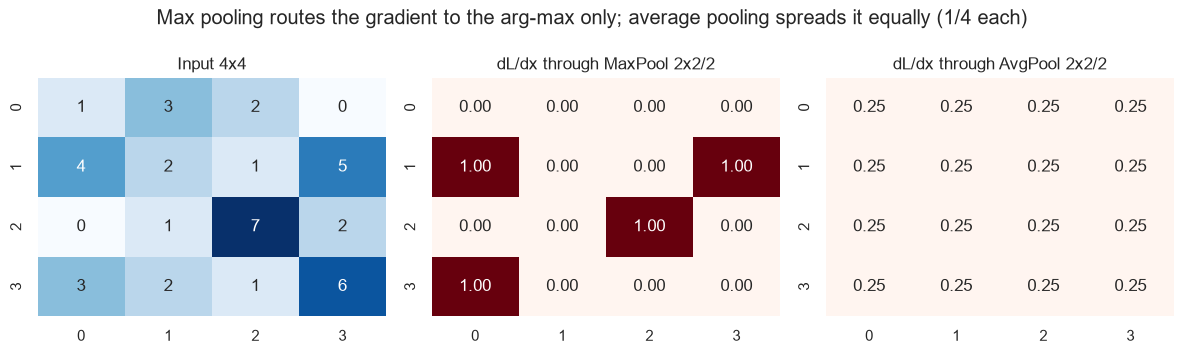

In [101]:
t = torch.tensor([[1., 3., 2., 0.],
                  [4., 2., 1., 5.],
                  [0., 1., 7., 2.],
                  [3., 2., 1., 6.]]).reshape(1, 1, 4, 4)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
sns.heatmap(t[0, 0].numpy(), annot=True, fmt='.0f', cbar=False, cmap='Blues', ax=axes[0]); axes[0].set_title('Input 4x4')
for ax, name, fn in [(axes[1], 'MaxPool 2x2/2', F.max_pool2d), (axes[2], 'AvgPool 2x2/2', F.avg_pool2d)]:
    x = t.clone().requires_grad_(True)
    out = fn(x, 2, 2); out.sum().backward()
    print(f'{name}: output =\n{out[0, 0].detach().numpy()}\n gradient w.r.t. input =\n{x.grad[0, 0].numpy()}\n')
    sns.heatmap(x.grad[0, 0].numpy(), annot=True, fmt='.2f', cbar=False, cmap='Reds', ax=ax); ax.set_title(f'dL/dx through {name}')
fig.suptitle('Max pooling routes the gradient to the arg-max only; average pooling spreads it equally (1/4 each)')
fig.tight_layout(); savefig(fig, 'fig_pooling_gradient_flow.png'); plt.show()

## 13.10 Written explanation
Explain how gradients propagate differently through max pooling and average pooling (use the demonstration above), and why pooling layers have no trainable parameters.

### Answer

In the $4\times4$ demo with an upstream gradient of 1 for each pooled output:

- **Max pooling:** the forward pass keeps the biggest number in each $2\times2$ window (outputs 4, 5, 3, 7). In the backward pass, the gradient goes only to the position of that maximum, so those four positions get 1 and the other twelve get 0.
- **Average pooling:** each output is the mean of 4 numbers, so each input contributes $\tfrac14$ of it. The gradient is split equally, and every position gets 0.25.

Pooling layers have no trainable parameters because they apply a fixed rule (the maximum or the mean) with no weights to learn. Gradients still pass through them to the earlier layers, but there is nothing to update inside the pooling layer itself.

---
# 14. Visualization Requirements - Checklist

The required figures are saved in `figures/`. The cell below checks that each one exists.

In [126]:
def fig_name(prefix, a):
    return f'{prefix}_{a}_CE_Adam.png'.replace(' ', '')

required = [('Original images (Sec. 1)', 'fig_original_images.png')]
required += [(f'Augmentation - {CLASS_TITLES[c]} (Sec. 3)', f'fig_augmentation_{c}.png') for c in CLASS_KEYS]
required += [(f'Convolution calculation - {CLASS_TITLES[c]} (Sec. 4)', f'fig_convolution_{c}.png') for c in CLASS_KEYS]
required += [(f'Loss/accuracy curves - {a} (Sec. 5)', fig_name('fig_curves', a)) for a in ARCHS]
required += [(f'Confusion matrix - {a} (Sec. 5)', fig_name('fig_confusion', a)) for a in ARCHS]
required += [('Architecture comparison (Sec. 5)', 'fig_architecture_comparison.png'), ('Loss-function comparison (Sec. 6)', 'fig_loss_comparison.png'),
             ('Optimizer comparison (Sec. 7)', 'fig_optimizer_comparison.png'), ('Optimizer loss curves overlay (Sec. 7)', 'fig_optimizer_loss_curves.png'),
             ('Kernel feature maps (Sec. 8)', 'fig_kernel_feature_maps.png'), ('Kernel-size comparison (Sec. 8)', 'fig_kernel_comparison.png'),
             ('Stride comparison (Sec. 9)', 'fig_stride_comparison.png'),
             ('Padding feature maps (Sec. 10)', 'fig_padding_feature_maps.png'), ('Padding comparison (Sec. 10)', 'fig_padding_comparison.png'),
             ('Pooling feature maps before/after (Sec. 11)', 'fig_pooling_feature_maps.png'), ('Pooling comparison (Sec. 11)', 'fig_pooling_comparison.png'),
             ('Combined configs comparison (Sec. 12)', 'fig_combined_comparison.png'), ('Pooling gradient flow (Sec. 13)', 'fig_pooling_gradient_flow.png')]
chk = pd.DataFrame([{'Required figure': n, 'file': f, 'status': 'ok' if os.path.exists(os.path.join(FIG_DIR, f)) else 'MISSING'} for n, f in required])
display(chk.style.apply(lambda s: ['color: red' if v == 'MISSING' else '' for v in s], subset=['status']))
print(f"{(chk.status == 'ok').sum()} / {len(chk)} required figures present")

,Required figure,file,status
0,Original images (Sec. 1),fig_original_images.png,ok
1,Augmentation - Glioma (Sec. 3),fig_augmentation_glioma.png,ok
2,Augmentation - Meningioma (Sec. 3),fig_augmentation_meningioma.png,ok
3,Augmentation - Pituitary Tumor (Sec. 3),fig_augmentation_pituitary.png,ok
4,Augmentation - No Tumor (Sec. 3),fig_augmentation_notumor.png,ok
5,Convolution calculation - Glioma (Sec. 4),fig_convolution_glioma.png,ok
6,Convolution calculation - Meningioma (Sec. 4),fig_convolution_meningioma.png,ok
7,Convolution calculation - Pituitary Tumor (Sec. 4),fig_convolution_pituitary.png,ok
8,Convolution calculation - No Tumor (Sec. 4),fig_convolution_notumor.png,ok
9,Loss/accuracy curves - LeNet-5 (Sec. 5),fig_curves_LeNet-5_CE_Adam.png,ok


34 / 34 required figures present


---
# 15. Code Organization and Experiment Log

Every finished run (settings and results) is logged to `experiment_log.csv`. The cell below loads that log.

In [103]:
log_df = load_run_log()
print(f'{len(log_df)} finished runs logged in {LOG_CSV}')
display(log_df.drop(columns=['model', 'opt_kwargs']).head(60) if len(log_df) else log_df)

56 finished runs logged in experiment_log.csv


,run_id,loss,optimizer,epochs_budget,patience,batch_size,img_size,seed,params,epochs_run,best_epoch,train_time_s,status,train_acc,val_acc,test_acc
0,03df0177ba,CE,Adam,30,6,32,128,42,23668,15,8,127.1,early stopped (patience 6),0.735520,0.730672,0.750000
1,0555d5f086,CE,Adam,30,6,32,128,42,606276,30,30,504.0,completed (full epoch budget),0.863809,0.837292,0.836869
2,0619a27243,CE,Adam,30,6,32,128,42,23924,22,18,239.2,early stopped (patience 6),0.724802,0.719555,0.729798
3,0a37a68a3b,CE,SGD,30,6,32,128,42,2796772,22,18,306.2,early stopped (patience 6),0.860777,0.834260,0.823232
4,1300554095,CE,SGD,30,6,32,128,42,5869380,29,23,309.3,early stopped (patience 6),0.857638,0.830217,0.831818
5,21ccf0cfef,CE,RMSprop,30,6,32,128,42,606276,18,18,302.5,early stopped (patience 6),0.852983,0.826175,0.830808
6,22d67427f0,CE,RMSprop,30,6,32,128,42,2833892,23,17,380.4,early stopped (patience 6),0.838476,0.816574,0.831313
7,2407c98043,LS,Adam,30,6,32,128,42,606276,19,13,324.4,early stopped (patience 6),0.855906,0.831228,0.832323
8,2f43966047,WCE,Adam,30,6,32,128,42,2796772,19,13,266.4,early stopped (patience 6),0.858504,0.832744,0.836364
9,3fad0ad5ee,CE,AdamW,30,6,32,128,42,606276,30,30,500.3,completed (full epoch budget),0.862726,0.835270,0.831313


---
# 16. Technical Report Notes and Submission Checklist

**Setup.** 13,196 brain MRI images (4 classes) were converted to $128\times128$ grayscale, split 70/15/15 (stratified, seed 42) and normalized with training-split statistics. All models were trained from scratch on a GTX 1080 with batch size 32, a maximum of 30 epochs and early stopping on validation loss (patience 6). Sections 5-7 use six architectures. Sections 8-12 use one small CNN (23,668 parameters), so their accuracies (about 0.70 to 0.80) cannot be compared with the six architectures (mostly 0.83 to 0.84; LeNet-5 0.74).

**Main results (observed).**

- Architectures (CE + Adam): EfficientNet was best (0.8369), but the top five are within 0.41 points of each other, which is inside the test-set noise. LeNet-5 was clearly lowest (0.7374).
- The best single result was VGG with SGD (Nesterov): 0.8424. The smallest model was GoogLeNet (165,476 parameters; 0.8328 with Adam and 0.8399 with SGD).
- Class-wise, No Tumor was almost perfect (recall 0.99 to 1.00 except LeNet-5), Pituitary Tumor was 0.93 to 0.95, and Meningioma (0.68 to 0.72, except LeNet-5 at 0.35) and Glioma (0.71 to 0.76) were the hardest.
- No loss function or optimizer won for every architecture. Focal loss lowered accuracy for all six architectures, and SGD helped LeNet-5 the most (0.7374 to 0.7879).
- Small CNN: the $7\times7$ first layer was the best kernel (0.7328), stride 2 was the best stride (0.7631, with 25% of the conv positions), valid padding scored 0.7177 vs 0.7096 for same, and Config E was the best combined setup (0.7566).

**Limitations.** Every result comes from one seed, and a 1,980-image test set has a standard error of about 0.8 points at 84% accuracy (about 1 point at 71%), so gaps below about 1 point should not be treated as real. The pooling comparison changes the classifier head together with the pooling type, and the VGG + Nadam training time is an outlier. An accuracy near 84% is not good enough for clinical use.